# ✍️ Lab 05: Can an LLM Judge Replace Your Analysts? 🔬

## Module 05 — Evaluating Generative Outputs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05-generative-outputs-lab.ipynb)

### 🕵️ The decision on your desk

Last quarter a portfolio manager caught an LLM-written earnings summary claiming revenue grew **15%** when it grew **8%**. Another summary left out a **debt covenant waiver** (lenders agreeing not to enforce a loan condition the company broke: a classic distress signal). Since then two analysts have reviewed every summary by hand. It's slow, and the summaries keep coming.

Your VP has a proposal:

> *"Put an LLM judge in front of every summary and retire the manual review. On our spot check it **agreed with the analysts 90% of the time**."*

By the end of this lab you'll **sign off on that proposal or block it, with evidence**. Along the way, a number you would normally trust will turn out to be lying to you.

| | |
|---|---|
| ⏱️ **Time** | 60–75 min core · +45 min for the five challenges |
| 🎚️ **Level** | Intermediate |
| 🔑 **Keys needed** | None. Runs offline with a simulated judge (`PROVIDER = "mock"`). Optional: an OpenAI or Anthropic key to run a real judge |
| 🧰 **Tools** | Python, `pandas`, `scikit-learn` (Cohen's κ), `pydantic` (verdict schema), `matplotlib` |
| 🏁 **You'll leave with** | A binary judge validated with TPR/TNR/κ, a three-probe bias kit, an evidence-based SHIP/BLOCK call, and a scored prediction card |

## 🧭 Overview

You'll build four evaluators for LLM-written earnings summaries, then turn the hardest question on the **evaluator itself**: how often is the judge wrong, and in which direction?

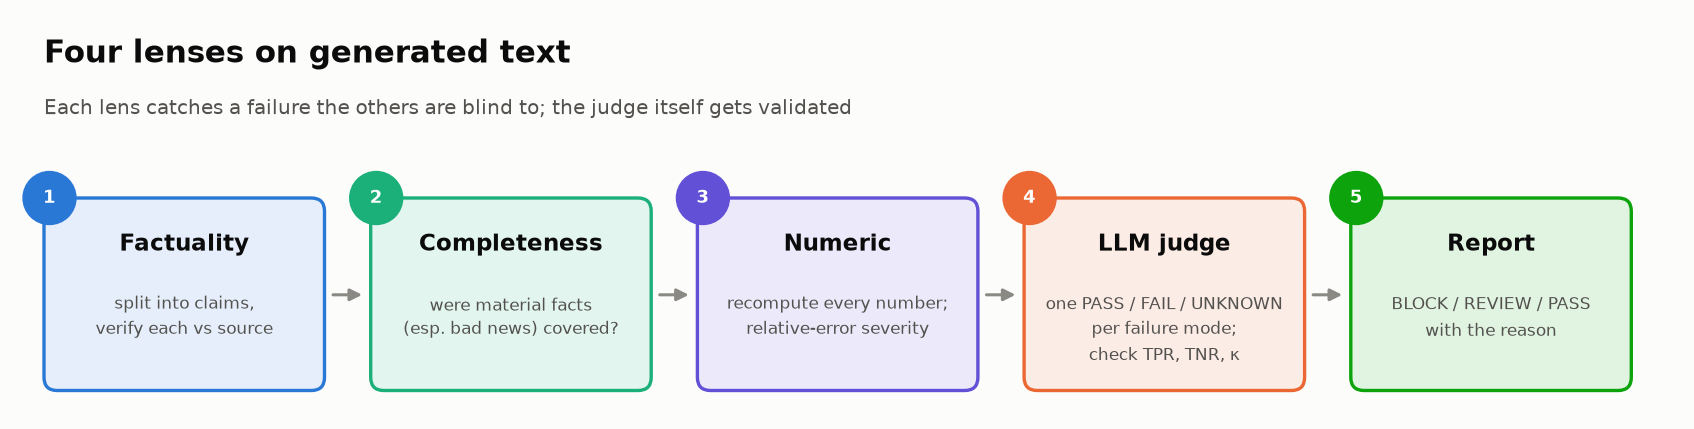

<sub>🖼️ *Each lens catches a failure the others are blind to.*</sub>

| Act | Tasks | Question it answers |
|---|---|---|
| 1. Deterministic checks | 2–6 | Are the claims true? Is anything material missing? Is the math right? |
| 2. The LLM judge | 7–8 | Can one PASS/FAIL check per failure mode catch what code can't? |
| 3. Judge the judge | 9–11 | How often is it wrong? Where? What sways it? |
| 4. The decision | 12 | Should the judge replace human review? |

<details>
<summary>📖 Jargon decoder: 34 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Earnings summary** | A short write-up of a company's quarterly results that investors act on | Hook, Task 2 |
| **Revenue · net income · net loss** | Sales · profit after every cost · a negative net income | Task 2 |
| **QoQ · YoY** | Quarter-over-quarter (vs the previous quarter) · year-over-year (vs the same quarter last year) | Tasks 2, 6 |
| **EPS** | Earnings per share: net income ÷ shares outstanding | Tasks 2, 6 |
| **Gross · operating margin** | Share of revenue left after direct costs · after all operating costs | Task 2 |
| **Guidance** | Management's forecast range for next quarter's results | Task 2 |
| **Debt covenant waiver** | Lenders agree not to enforce a loan condition the company broke or was about to break. A distress signal | Hook, Tasks 3, 5 |
| **Leverage** | Debt relative to what the company can pay it with; this lab's rubric flags debt above 2× cash | Tasks 8–9 |
| **Material** | Big enough to change a reasonable reader's decision | Tasks 2, 5, 6 |
| **Claim · atomic claim** | One checkable statement · one subject, one metric, one value | Task 4 |
| **Fabrication · distortion · conflation** | Three kinds of hallucination: an invented detail · a real fact with wrong details · facts mixed across sources or periods | Task 4 |
| **Factuality vs completeness** | "Is what it says true?" vs "Does it say everything material?" | Tasks 4–5 |
| **Deterministic check** | Code that gives the same answer every time (a regex, a recomputation); no model involved | Tasks 4–6 |
| **Entailment** | Whether a text actually *states or implies* a fact. Word overlap can't tell "a waiver was obtained" from "no waiver was obtained"; an entailment check can | Task 5, Challenge 1 |
| **Absolute · relative error** | \|stated − actual\| · that, divided by \|actual\| | Task 6 |
| **Percentage points (pp)** | The plain difference between two percentages: 25% vs 20% is 5 pp apart, a 25% *relative* error | Tasks 6, 11 |
| **Failure mode** | One specific, observable way an output goes wrong ("omits a material risk") | Tasks 2, 7 |
| **Rubric** | The written criteria a judge grades against | Task 7 |
| **Likert scale** | A 1–5 rating ("how good is it?") | Tasks 7–8 |
| **LLM judge** | A model given the source, the output and one rubric check, returning a verdict | Task 8 |
| **Structured output · Pydantic** | The API forces the reply to match a schema · the Python library used to define that schema as a class | Task 8 |
| **Critique-then-verdict** | The judge writes its evidence before its decision, so the decision is conditioned on it | Task 8 |
| **UNKNOWN (abstention)** | The judge declines to decide; a human does | Tasks 8–9 |
| **Meta-evaluation** | Evaluating the evaluator against expert labels | Task 9 |
| **TP · FN · FP · TN** | With FAIL as "positive": caught defect · missed defect · false alarm · correct pass | Task 9 |
| **TPR (recall) · TNR (specificity)** | Share of real failures the judge catches · share of good outputs it passes | Task 9 |
| **Raw agreement · base rate** | Share of verdicts that match · how often a rater says FAIL at all | Task 9 |
| **Cohen's κ (kappa)** | Agreement left after subtracting what the two raters' base rates would produce by luck; 0 = chance, 1 = perfect | Task 9 |
| **95% confidence interval (Wilson)** | The range of true rates consistent with what you observed; Wilson is the version that behaves on small samples | Task 9 |
| **Dev · test split** | Labels you tune a judge on · held-out labels you score it on once | Task 9, Challenge 3 |
| **Slicing** | Grouping errors by an input feature (format, position, type) to find the pattern | Task 10 |
| **Pairwise judging · position / verbosity / style bias** | The judge picks the better of two outputs · it favours the first slot / longer text / markdown formatting, regardless of content | Task 11 |
| **Self-preference · PoLL** | A judge favouring its own model family · a "panel of LLM evaluators" that votes | Task 11, Stretch B |
| **Defense in depth · IRS OPR** | Independent layers, so one layer's blind spot is another's catch · the IRS office that regulates tax practitioners | Task 12 |

</details>

## 🎯 Learning Objectives

1. Score factuality by splitting a summary into claims and labeling each **supported, contradicted or unsupported** against the source
2. Score completeness with material (especially negative) facts weighted more, and tell incompleteness from conciseness
3. Check numbers by **relative error** with severity tiers
4. Build an LLM judge from **binary PASS/FAIL checks, one per failure mode**, with critique-then-verdict, structured output and an `UNKNOWN` escape hatch
5. Validate a judge against expert labels with **TPR, TNR and Cohen's κ**, and explain why raw agreement misleads on imbalanced data
6. Probe a judge for position, verbosity and formatting bias
7. Combine the layers into a production decision

## 📋 Prerequisites

- Module 01 (Modern AI Evaluation Foundations) and Module 02 (Failure Mode Analysis)
- Some prompt-engineering experience
- Python with pandas and numpy. The confusion matrix (TP/FN/FP/TN) is explained where it's needed (Task 9)

## ⏱️ Estimated Time

**60–75 minutes** for Tasks 1–12. Stretch goals add ~15 minutes.

## 🧪 Environment and Setup

- Google Colab or local Jupyter, Python 3.10+. Every core cell runs **offline with no API keys**.
- `PROVIDER = "mock"` (the default) uses a simulated judge, so everyone sees the same numbers.
- For a real judge, set `PROVIDER = "openai"` (`gpt-6-luna`) or `"anthropic"` (`claude-haiku-5-5`) in Task 1 and provide `OPENAI_API_KEY` or `ANTHROPIC_API_KEY` (in Colab: 🔑 Secrets). Your numbers will then differ from the Expected Output blocks.

## 📖 Scenario

You're an ML engineer at a financial services firm. An LLM writes quarterly earnings summaries from raw financial data; portfolio managers trade on them.

> ⚠️ **Why This Matters:** One wrong number or one missing disclosure can drive a bad trade or a regulatory finding. These are compliance and financial-risk failures, not style issues.

Your job: catch factual errors, omissions, numeric mistakes and misleading framing **before** a summary reaches a decision-maker, and decide how much of that work an LLM judge can do alone.

---

## Task 1: Environment Setup 🛠️

Everything downstream reads one config cell; a model ID typed twice is next quarter's silent bug.

### Goal
Imports, a judge provider, and the lab kit (the cards, tiles and chart theme used in every task).

### Why
Model names live in **one** config cell, so switching from the offline mock to a real judge is a one-line change.

### Steps
1. Run the install cell (skip it if you stay on `PROVIDER = "mock"`).
2. Run the imports + configuration cell.
3. Run the 🎨 **Lab kit** cell. In Colab its code is collapsed; you don't need to read it.
4. Fill in your 🔮 **prediction card**: five numbers, committed before you see anything. Key Takeaways scores them.

In [ ]:
%%capture
# Only needed for a REAL judge (PROVIDER = "openai" or "anthropic").
# pandas, numpy, scikit-learn, matplotlib and pydantic are preinstalled in Colab.
!pip install -U openai anthropic

In [ ]:
import json                      # source data -> judge prompt
import re                        # claim extraction and text parsing
import hashlib                   # deterministic "noise" for the simulated judges
from collections import defaultdict
from typing import Literal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field          # the judge's verdict schema (structured output)
from sklearn.metrics import cohen_kappa_score  # agreement beyond chance

# ── Configuration: the ONLY place model names live ─────────────────────────────
PROVIDER = "mock"                              # "mock" (offline, default) | "openai" | "anthropic"
OPENAI_JUDGE_MODEL = "gpt-6-luna"              # stronger judge: "gpt-6.1-sol"
ANTHROPIC_JUDGE_MODEL = "claude-haiku-5-5"     # stronger judge: "claude-sonnet-5-5"
SEED = 7                                       # fixes the synthetic data (a real judge is never deterministic)

pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 70)
print(f"✅ Imports OK · PROVIDER = {PROVIDER!r}")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

In [ ]:
# 🔮 YOUR PREDICTION CARD: commit to five numbers now. Key Takeaways scores them against your run.
# The defaults are the VP's guesses. Overwrite them with yours before you read further.
MY_PREDICTIONS = {
    "summaries_with_material_error": 0,  # Tasks 3/6: how many of the six summaries state a materially wrong number? (0-6)
    "claims_caught_of_3": 3,             # Task 4: a claim verifier checks 3 known wrong numbers. How many does it catch? (0-3)
    "stamp_agreement_pct": 50,           # Task 9: a "judge" that always says PASS. Its % agreement with the expert on hidden risks? (0-100)
    "risk_judge_tpr_pct": 90,            # Task 9: the risk judge agrees with the expert 90% of the time. What % of hidden risks does it catch?
    "markdown_shift_pp": 5,              # Task 11: same words, rewritten as bold bullets. How many points does a judge's preference move? (0-50)
}
print(f"🔮 {len(MY_PREDICTIONS)} predictions locked in. Scored in Key Takeaways.")


### Checkpoint ✅
All three cells run without errors. `ModuleNotFoundError`: run the install cell, then restart the runtime.

### Expected Output
```
✅ Imports OK · PROVIDER = 'mock'
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
🔮 5 predictions locked in. Scored in Key Takeaways.
```

> 💡 **Why no `temperature=0`?** Anthropic's API rejects `temperature`/`top_p`/`top_k` (HTTP 400 from API version 2026-10-21), and support on OpenAI's gpt-6 models is unverified, so the code never sends it. It never bought reproducibility anyway: in a Thinking Machines experiment (Sept 2025), 1,000 identical temperature-0 requests produced 80 distinct completions. Here, reproducibility comes from the offline mock and fixed seeds; **trust in a real judge comes from validating it (Task 9)**.

---

Every evaluation starts with **ground truth**: the source data each summary was written from.

---

🧭 **Where you are:** Act 1 of 4 (Tasks 2–6): deterministic checks on six summaries. Three layers that code can run exactly, before any model judges anything.

## Task 2: Load the Financial Analysis Dataset 📊

Every evaluator you build compares a summary with its source; load the wrong truth and every layer lies with confidence.

### Goal
Six LLM-generated quarterly earnings summaries, each with its **source data** (ground truth), the **generated summary** (what you're evaluating), and two kinds of expert labels.

### Why
You can only measure where an LLM went wrong when you know the right answer. In real work the source of truth is a database, a filing or a reference answer; here it's the source data.

🏦 **In your world:** swap earnings summaries for an AI-written quarter-end summary of a small business's books, or a plain-English explanation of a tax return. Same structure (source → generated text), same failure modes.

### Dataset schema
- **company**, **quarter**
- **source_data**: the real figures and notable events. **Ground truth**. New to earnings data? **QoQ** = vs last quarter, **YoY** = vs the same quarter last year, **EPS** = net income per share, **margin** = share of revenue kept, **guidance** = management's forecast (📖 decoder above for the rest)
- **generated_summary**: the LLM's text. **What you're evaluating**
- **key_facts**: facts a correct summary should cover (completeness, Task 5)
- **numeric_claims**: numbers the summary states, paired with the true values (Task 6)
- **human_quality_score**: an expert's holistic 1–5 rating (the old way)
- **human_labels**: the same expert's **PASS/FAIL per failure mode**, a failure mode being one specific, observable way a summary goes wrong (the 2026 way; used from Task 8)

> 🔮 **Predict:** The expert scored these six between 2 and 5. If your team ships anything rated **3 or higher**, how many ship: **A** 2 · **B** 4 · **C** all 6? And would you send every one of them to a portfolio manager?

### Steps
Run the collapsed 🧰 dataset cell, then the first-look cell under it.

In [ ]:
# @title 🧰 Dataset: 6 summaries with source data, key facts, numeric claims and expert labels (hidden · 308 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# Synthetic financial analysis evaluation dataset
# Each entry represents one quarterly summary generated by an LLM.
#
# STRUCTURE OF EACH ENTRY:
#   - source_data: The ACTUAL numbers (our ground truth)
#   - generated_summary: What the LLM wrote (what we're checking)
#   - key_facts: Facts that SHOULD appear (for completeness scoring)
#   - numeric_claims: Specific numbers to verify (stated vs actual)
#   - human_quality_score: Expert rating for comparison to our automated scores
# ──────────────────────────────────────────────────────────────

financial_dataset = [
    {
        "id": 1,
        "company": "TechFlow Inc.",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 142_000_000,
            "revenue_prev_quarter": 128_000_000,
            "revenue_prev_year": 118_000_000,
            "operating_expenses": 98_000_000,
            "net_income": 31_000_000,
            "net_income_prev_quarter": 27_000_000,
            "gross_margin_pct": 45.2,
            "operating_margin_pct": 31.0,
            "eps": 2.15,
            "eps_prev_quarter": 1.88,
            "total_debt": 85_000_000,
            "cash_on_hand": 210_000_000,
            "headcount": 3_200,
            "guidance_next_quarter_revenue_low": 148_000_000,
            "guidance_next_quarter_revenue_high": 155_000_000,
            "notable_events": ["Acquired DataSync Corp for $45M", "Launched CloudEdge platform"]
        },
        # This summary is HIGH QUALITY — accurate, complete, well-framed
        "generated_summary": "TechFlow Inc. reported strong Q3 2025 results with revenue of $142M, up 10.9% quarter-over-quarter and 20.3% year-over-year. Net income reached $31M with EPS of $2.15, representing 14.4% growth over Q2. The company maintains a healthy balance sheet with $210M in cash against $85M in total debt. Operating margin was 31.0% with gross margins at 45.2%. During the quarter, TechFlow acquired DataSync Corp for $45M and launched the CloudEdge platform. Management guided Q4 revenue to $148M-$155M, signaling continued momentum.",
        "key_facts": [
            "Revenue of $142M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $31M",
            "EPS of $2.15",
            "Cash position of $210M",
            "Debt position of $85M",
            "Acquisition of DataSync Corp",
            "Launch of CloudEdge platform",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 142_000_000, "actual": 142_000_000},
            "qoq_growth_pct": {"stated": 10.9, "actual": 10.94},
            "yoy_growth_pct": {"stated": 20.3, "actual": 20.34},
            "eps": {"stated": 2.15, "actual": 2.15},
            "eps_growth_pct": {"stated": 14.4, "actual": 14.36},
            "net_income": {"stated": 31_000_000, "actual": 31_000_000}
        },
        "human_quality_score": 5  # Expert says: excellent summary
    },
    {
        "id": 2,
        "company": "GreenLeaf Energy",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 89_000_000,
            "revenue_prev_quarter": 94_000_000,
            "revenue_prev_year": 82_000_000,
            "operating_expenses": 78_000_000,
            "net_income": 4_500_000,
            "net_income_prev_quarter": 11_000_000,
            "gross_margin_pct": 28.1,
            "operating_margin_pct": 12.4,
            "eps": 0.38,
            "eps_prev_quarter": 0.92,
            "total_debt": 220_000_000,
            "cash_on_hand": 45_000_000,
            "headcount": 1_800,
            "guidance_next_quarter_revenue_low": 91_000_000,
            "guidance_next_quarter_revenue_high": 97_000_000,
            "notable_events": ["Debt covenant waiver obtained from lenders", "CEO transition announced"]
        },
        # ⚠️ This summary is MISLEADING — everything stated is true,
        # but it OMITS critical negative information (declining revenue,
        # plummeting income, debt covenant waiver, CEO leaving)
        "generated_summary": "GreenLeaf Energy posted Q3 2025 revenue of $89M, growing 8.5% year-over-year. Operating margin remained healthy at 12.4%. EPS came in at $0.38. The company has $45M in cash and continues to invest in renewable infrastructure expansion. Management expects Q4 revenue between $91M and $97M, reflecting confidence in their growth strategy.",
        "key_facts": [
            "Revenue of $89M",
            "Revenue declined quarter-over-quarter",
            "Year-over-year revenue growth",
            "Significant net income decline",
            "EPS of $0.38 (sharp drop from $0.92)",
            "High debt level of $220M",
            "Low cash position of $45M relative to debt",
            "Debt covenant waiver obtained",
            "CEO transition announced",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 89_000_000, "actual": 89_000_000},
            "yoy_growth_pct": {"stated": 8.5, "actual": 8.54},
            "operating_margin_pct": {"stated": 12.4, "actual": 12.4},
            "eps": {"stated": 0.38, "actual": 0.38}
        },
        "human_quality_score": 2  # Expert says: dangerously misleading
    },
    {
        "id": 3,
        "company": "MedVault Health",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 210_000_000,
            "revenue_prev_quarter": 198_000_000,
            "revenue_prev_year": 175_000_000,
            "operating_expenses": 165_000_000,
            "net_income": 33_000_000,
            "net_income_prev_quarter": 29_000_000,
            "gross_margin_pct": 52.8,
            "operating_margin_pct": 21.4,
            "eps": 1.72,
            "eps_prev_quarter": 1.51,
            "total_debt": 150_000_000,
            "cash_on_hand": 320_000_000,
            "headcount": 5_400,
            "guidance_next_quarter_revenue_low": 218_000_000,
            "guidance_next_quarter_revenue_high": 225_000_000,
            "notable_events": ["FDA approval for DiagnostiQ AI platform", "Expanded into 3 new European markets"]
        },
        # ⚠️ This summary has a NUMERIC ERROR — states 25% YoY growth
        # but the actual calculation is (210-175)/175 = 20.0%
        "generated_summary": "MedVault Health delivered solid Q3 2025 results. Revenue hit $210M, up 6.1% from Q2 and 25% year-over-year — a strong acceleration driven by the new DiagnostiQ AI platform which received FDA approval during the quarter. Net income was $33M with EPS of $1.72. Gross margins expanded to 52.8%, among the best in the health-tech sector. The company expanded into 3 new European markets and holds a fortress balance sheet with $320M in cash versus $150M in debt. Operating expenses rose to $165M reflecting investment in European expansion. Q4 guidance of $218M-$225M suggests management expects mid-single-digit sequential growth.",
        "key_facts": [
            "Revenue of $210M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $33M",
            "EPS of $1.72",
            "Gross margin of 52.8%",
            "FDA approval for DiagnostiQ AI",
            "European market expansion",
            "Cash position of $320M",
            "Debt of $150M",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 210_000_000, "actual": 210_000_000},
            "qoq_growth_pct": {"stated": 6.1, "actual": 6.06},
            "yoy_growth_pct": {"stated": 25.0, "actual": 20.0},  # <-- THE ERROR: 25% vs 20%
            "eps": {"stated": 1.72, "actual": 1.72},
            "gross_margin_pct": {"stated": 52.8, "actual": 52.8},
            "net_income": {"stated": 33_000_000, "actual": 33_000_000}
        },
        "human_quality_score": 3  # Expert says: good but has a numeric error
    },
    {
        "id": 4,
        "company": "UrbanLogix",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 67_000_000,
            "revenue_prev_quarter": 71_000_000,
            "revenue_prev_year": 63_000_000,
            "operating_expenses": 72_000_000,
            "net_income": -8_500_000,
            "net_income_prev_quarter": -3_200_000,
            "gross_margin_pct": 18.7,
            "operating_margin_pct": -7.5,
            "eps": -0.62,
            "eps_prev_quarter": -0.23,
            "total_debt": 180_000_000,
            "cash_on_hand": 52_000_000,
            "headcount": 2_100,
            "guidance_next_quarter_revenue_low": 70_000_000,
            "guidance_next_quarter_revenue_high": 75_000_000,
            "notable_events": ["Restructuring plan announced — 15% workforce reduction", "Entered partnership with CityGrid for smart delivery"]
        },
        # ⚠️ This summary SPINS negative news positively —
        # calls widening losses "strategic investments" and omits the layoffs
        "generated_summary": "UrbanLogix reported Q3 2025 revenue of $67M, up 6.3% year-over-year, demonstrating resilience in the logistics space. While operating expenses of $72M exceeded revenue, the company's strategic investments are positioning it for long-term growth. EPS was -$0.62. The company announced an exciting partnership with CityGrid for smart delivery solutions and has $52M in cash to fund operations. Management guided Q4 revenue to $70M-$75M.",
        "key_facts": [
            "Revenue of $67M",
            "Revenue declined quarter-over-quarter",
            "Year-over-year revenue growth",
            "Net loss of $8.5M (widening losses)",
            "Negative operating margin of -7.5%",
            "EPS of -$0.62 (worsening from -$0.23)",
            "High debt of $180M vs $52M cash",
            "15% workforce restructuring",
            "CityGrid partnership",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 67_000_000, "actual": 67_000_000},
            "yoy_growth_pct": {"stated": 6.3, "actual": 6.35},
            "operating_expenses": {"stated": 72_000_000, "actual": 72_000_000},
            "eps": {"stated": -0.62, "actual": -0.62}
        },
        "human_quality_score": 2  # Expert says: misleading positive spin
    },
    {
        "id": 5,
        "company": "NexaPay Financial",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 325_000_000,
            "revenue_prev_quarter": 310_000_000,
            "revenue_prev_year": 280_000_000,
            "operating_expenses": 245_000_000,
            "net_income": 58_000_000,
            "net_income_prev_quarter": 52_000_000,
            "gross_margin_pct": 61.3,
            "operating_margin_pct": 24.6,
            "eps": 3.42,
            "eps_prev_quarter": 3.07,
            "total_debt": 120_000_000,
            "cash_on_hand": 480_000_000,
            "headcount": 8_200,
            "guidance_next_quarter_revenue_low": 335_000_000,
            "guidance_next_quarter_revenue_high": 345_000_000,
            "notable_events": ["Launched instant cross-border payments in 12 new countries", "Regulatory approval for crypto custody services"]
        },
        # ⚠️ This summary has FABRICATED details — says 15 countries
        # (actual: 12) and EPS growth of 22% (actual: ~11.4%)
        "generated_summary": "NexaPay Financial posted exceptional Q3 2025 results with revenue of $325M, up 4.8% sequentially and 16.1% year-over-year. Net income surged to $58M, driving EPS to $3.42 — a 22% increase versus Q2. Gross margins of 61.3% and operating margins of 24.6% reflect excellent unit economics. The company launched instant cross-border payments in 15 new countries and received regulatory approval for crypto custody services. With $480M in cash and only $120M in debt, NexaPay has significant capacity for M&A. Q4 guidance of $335M-$345M represents 3-6% sequential growth. One risk to watch: operating expenses of $245M grew faster than revenue on a percentage basis.",
        "key_facts": [
            "Revenue of $325M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $58M",
            "EPS of $3.42",
            "Gross margin of 61.3%",
            "Operating margin of 24.6%",
            "Cross-border payments expansion",
            "Crypto custody regulatory approval",
            "Strong cash position ($480M vs $120M debt)",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 325_000_000, "actual": 325_000_000},
            "qoq_growth_pct": {"stated": 4.8, "actual": 4.84},
            "yoy_growth_pct": {"stated": 16.1, "actual": 16.07},
            "eps": {"stated": 3.42, "actual": 3.42},
            "eps_growth_pct": {"stated": 22.0, "actual": 11.40},  # <-- WRONG: 22% vs 11.4%
            "net_income": {"stated": 58_000_000, "actual": 58_000_000},
            "countries_expanded": {"stated": 15, "actual": 12}  # <-- FABRICATED: 15 vs 12
        },
        "human_quality_score": 3  # Expert says: mostly good but has errors
    },
    {
        "id": 6,
        "company": "SkyBridge Telecom",
        "quarter": "Q3 2025",
        "source_data": {
            "revenue": 195_000_000,
            "revenue_prev_quarter": 192_000_000,
            "revenue_prev_year": 188_000_000,
            "operating_expenses": 170_000_000,
            "net_income": 18_000_000,
            "net_income_prev_quarter": 16_500_000,
            "gross_margin_pct": 38.5,
            "operating_margin_pct": 12.8,
            "eps": 1.05,
            "eps_prev_quarter": 0.96,
            "total_debt": 340_000_000,
            "cash_on_hand": 75_000_000,
            "headcount": 4_600,
            "guidance_next_quarter_revenue_low": 196_000_000,
            "guidance_next_quarter_revenue_high": 202_000_000,
            "notable_events": ["5G network coverage reached 80% of target markets", "Signed 10-year spectrum lease agreement"]
        },
        # This summary is DECENT — accurate but misses the $340M debt position
        "generated_summary": "SkyBridge Telecom delivered steady Q3 2025 results with revenue of $195M, a modest 1.6% increase over Q2 and 3.7% year-over-year growth. Net income of $18M and EPS of $1.05 show continued profitability. The company achieved a major milestone with 5G coverage reaching 80% of target markets and secured a 10-year spectrum lease. Operating margin of 12.8% was stable. Cash on hand stands at $75M. Q4 guidance of $196M–$202M suggests continued steady performance.",
        "key_facts": [
            "Revenue of $195M",
            "Quarter-over-quarter revenue growth",
            "Year-over-year revenue growth",
            "Net income of $18M",
            "EPS of $1.05",
            "5G coverage milestone (80%)",
            "Spectrum lease agreement",
            "Debt position of $340M",
            "Cash position of $75M",
            "Q4 revenue guidance range"
        ],
        "numeric_claims": {
            "revenue": {"stated": 195_000_000, "actual": 195_000_000},
            "qoq_growth_pct": {"stated": 1.6, "actual": 1.56},
            "yoy_growth_pct": {"stated": 3.7, "actual": 3.72},
            "eps": {"stated": 1.05, "actual": 1.05},
            "net_income": {"stated": 18_000_000, "actual": 18_000_000}
        },
        "human_quality_score": 4  # Expert says: solid but missing debt info
    }
]

# ── The expert's BINARY labels, one per failure mode (used from Task 8 on) ──
# Same expert, different question: not "how good is it, 1-5?" but "does it show failure X, yes or no?"
MODES = ["numbers_correct", "grounded", "risks_disclosed", "balanced_framing"]
HUMAN_LABELS = {
    1: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    2: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "FAIL"},
    3: {"numbers_correct": "FAIL", "grounded": "FAIL", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    4: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "FAIL"},
    5: {"numbers_correct": "FAIL", "grounded": "FAIL", "risks_disclosed": "PASS", "balanced_framing": "PASS"},
    6: {"numbers_correct": "PASS", "grounded": "PASS", "risks_disclosed": "FAIL", "balanced_framing": "PASS"},
}
for item in financial_dataset:
    item["human_labels"] = HUMAN_LABELS[item["id"]]


In [ ]:
# A first look at the six summaries, the way the expert saw them: one 1–5 score each.
overview = pd.DataFrame([{
    "id": it["id"], "company": it["company"],
    "revenue": f"${it['source_data']['revenue'] / 1e6:.0f}M",
    "net income": f"${it['source_data']['net_income'] / 1e6:.1f}M",
    "key facts": len(it["key_facts"]), "numeric claims": len(it["numeric_claims"]),
    "human 1-5": it["human_quality_score"],
} for it in financial_dataset]).set_index("id")
print(f"Loaded {len(financial_dataset)} financial analysis summaries.\n")
print(overview.to_string())

scores = [it["human_quality_score"] for it in financial_dataset]
tiles([
    ("Summaries", len(financial_dataset), "Q3 2025 earnings", None),
    ("Expert score range", f"{min(scores)}–{max(scores)}", "holistic 1–5 rating", None),
    ("Rated 3 or higher", f"{sum(s >= 3 for s in scores)} of {len(scores)}", "would all of these be safe to send?", "warning"),
])


### Checkpoint ✅
A 6-row table and three tiles.

### Expected Output (partial)
```
Loaded 6 financial analysis summaries.

              company revenue net income  key facts  numeric claims  human 1-5
id
1       TechFlow Inc.   $142M     $31.0M         10               6          5
2    GreenLeaf Energy    $89M      $4.5M         10               4          2
...
```
Tiles: **Rated 3 or higher: 4 of 6**.

### 🔍 What Just Happened?
A "ship anything ≥ 3" rule sends **four** summaries to portfolio managers. By Task 6 you'll know how many of those four contain a **materially** wrong number: wrong by enough to change a decision.

---

## Task 3: 🔍 Think First — What Makes a Financial Summary Trustworthy?

An evaluator catches only the error classes someone named first; the one nobody named is the one that ships.

### Goal
Your own list of the ways a financial summary can be wrong, ranked by damage, before you build anything.

### Why
You can't build an evaluator for errors you haven't named. In finance a bad summary isn't a wasted read; it's a bad trade or a regulatory finding.

🏦 **In your world:** the tax-season GreenLeaf is a refund explanation that gets the refund right and never mentions the underpayment penalty or the unreported contractor income.

> 🔮 **Predict:** How many of the six summaries contain at least one materially wrong number? **A** 0–1 · **B** 2–3 · **C** 4–6. It's the first number on your prediction card; Task 6 reveals the answer.

### Context
The GreenLeaf Energy summary (Summary 2):

> "GreenLeaf Energy posted Q3 2025 revenue of $89M, growing 8.5% year-over-year. Operating margin remained healthy at 12.4%. EPS came in at $0.38. The company has $45M in cash and continues to invest in renewable infrastructure expansion. Management expects Q4 revenue between $91M and $97M, reflecting confidence in their growth strategy."

Now its source data (Summary 2 in the cell above):
- Revenue fell from Q2 ($94M → $89M): not mentioned
- Net income fell from $11M to $4.5M: not mentioned
- EPS fell from $0.92 to $0.38: stated without the drop
- $220M of debt against $45M of cash: debt not mentioned
- A **debt covenant waiver**: omitted
- The **CEO is leaving**: omitted

Every sentence is true. The summary still paints a misleading picture, by omission. That is the hardest error class to catch and one of the most dangerous.

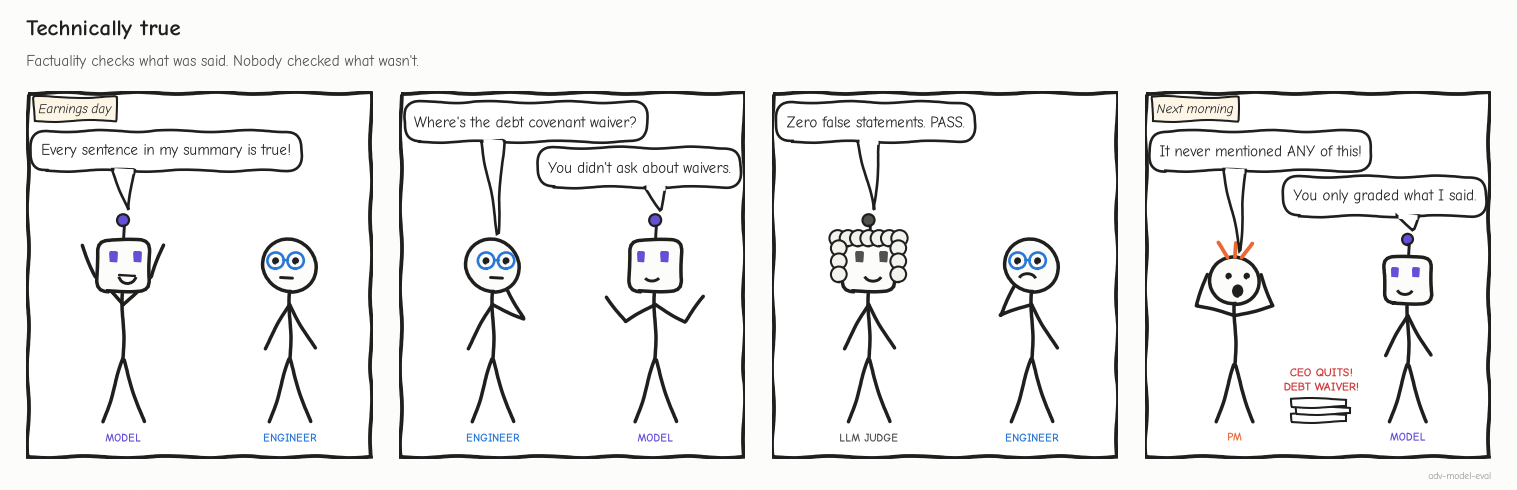

<sub>🖼️ *A factuality score only grades what was said. Hold on to this; Task 5 measures what wasn't.*</sub>

### Questions
Take **3–4 minutes** and write your answers in the cell below. ⏩ *Fast-track: short on time? Answer question 2 in your head and move on.*

1. **Types of errors:** In what distinct ways can a financial summary be wrong? Go beyond "incorrect numbers."
2. **Severity ranking:** Rank from most to least dangerous:
   - Rounding a growth rate (10.94% → 10.9%)
   - Omitting a debt covenant waiver
   - Stating revenue grew when it fell quarter-over-quarter
   - Revenue of $142M reported as $143M
   - Optimistic framing of declining metrics
3. **Omission vs fabrication:** Which is more dangerous in financial reporting, leaving out critical information or stating something false? Why?
4. **Evaluation dimensions:** List at least 4 distinct dimensions you'd evaluate a summary on.

> ⚠️ **Common Mistake:** Treating evaluation as "are the facts correct?" GreenLeaf is 100% factually correct and dangerously misleading. A good evaluator checks **several dimensions**.

No answers are provided here; your reasoning shapes how you approach the pipeline.

### ✍️ Your Reflections

**Write your answers here** (double-click to edit this cell):

1. **Types of errors:**

   *Your answer...*

2. **Severity ranking:**

   *Your answer...*

3. **Omission vs fabrication:**

   *Your answer...*

4. **Evaluation dimensions:**

   *Your answer...*

---
*Keep this cell; you'll check your dimensions against the four evaluators you build.*

---

## Task 4: Implement Factuality Scoring (Claim Extraction + Verification) 🔍

A fluent paragraph with one wrong number reads exactly like a fluent paragraph with none; this layer, **factuality** (is what it *says* true?), is the first to tell them apart.

### Goal
A pipeline that splits each summary into **claims** (one checkable statement each), labels each claim against the source data, and produces a factuality score per summary.

### Why
Fluent text can be wrong, and readers trust fluent text. In finance, one wrong number can move a million-dollar trade.

🏦 **In your world:** every number in a tax or bookkeeping explanation ("your refund is $1,240", "your effective rate is 11.2%") is a claim to check against the computed return or ledger, one atomic claim at a time.

### Three kinds of hallucination

| Type | What happens | Example from this dataset |
|---|---|---|
| **Fabrication** | A detail the source doesn't contain | "15 countries" (source: 12) |
| **Distortion** | A real fact with wrong details | "25% YoY growth" (source: 20%) |
| **Conflation** | Details mixed across sources or periods | Q2 numbers in a Q3 summary |

### Claim labels

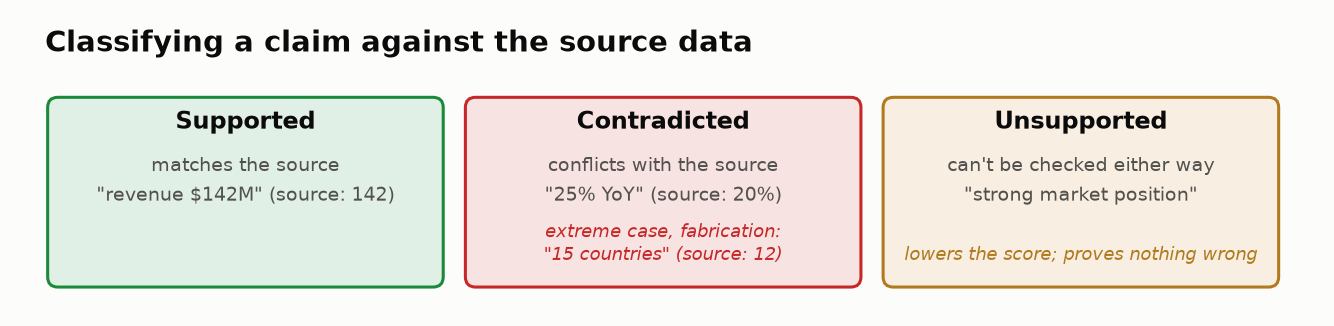

Each claim gets one of three labels:

- **Supported**: matches the source ("revenue of $142M"; source: 142).
- **Contradicted**: conflicts with the source ("25% year-over-year"; source: 20%). A **fabrication** (NexaPay's "15 countries") is the extreme case; this verifier labels it contradicted, so the table's `fabricated` column stays 0.
- **Unsupported**: can't be checked either way: opinion ("strong market position") or a claim the verifier can't map to a source field. It lowers the score without proving anything wrong.

**Factuality score = (supported − 2 × contradicted − 2 × fabricated) / total claims.** A false claim costs double an unverifiable one. Worked: 10 claims, 7 supported, 1 contradicted, 2 unsupported → (7 − 2) / 10 = **0.50**.

> 📘 **Concept · Atomic claim**
>
> **What it is:** one subject, one metric, one value ("EPS growth = 22%"), checkable against a single source field.
>
> **What it can't tell you:** whether something material was left out. Factuality grades only what was said.
>
> **Anchor:** "driving EPS to $3.42 — a 22% increase" is two claims: $3.42 is right, 22% is wrong (the source implies 11.4%). Verified as one sentence, whichever fact matches first decides the label.

> 🔮 **Predict:** A keyword verifier will check every sentence of all six summaries. MedVault's "25% year-over-year" (the truth is 20%) will come back **A** contradicted · **B** unsupported · **C** supported.

### Steps
1. Read `extract_claims()`. The verifier under it is collapsed (five priority rules, first match wins); expand it after the checkpoint.
2. Run factuality scoring on all six summaries and read the issues list; the collapsed scoreboard cell adds the tiles and cards.

In [ ]:
# ──────────────────────────────────────────────────────────────
# STEP 1: CLAIM EXTRACTION
# Split a summary into individual, checkable claims: you can't verify
# a paragraph at once, but you can verify one statement.
# ──────────────────────────────────────────────────────────────

def extract_claims(summary_text):
    """
    Split a financial summary into claims: sentences, then the parts of
    compound sentences. In production an LLM does this step; rules keep
    the lab reproducible.
    """
    # Split into sentences at period/exclamation/question marks
    sentences = re.split(r'(?<=[.!?])\s+', summary_text.strip())
    claims = []
    for sent in sentences:
        # Split compound sentences (e.g., "Revenue grew and margins expanded")
        # so each part becomes a separate, verifiable claim
        parts = re.split(r'\s+and\s+|\s+while\s+', sent)   # 👀 Look at: a dash-joined fact stays glued to its neighbour
        for part in parts:
            part = part.strip()
            if len(part) > 15:  # Skip very short fragments that aren't real claims
                claims.append(part)
    return claims

print(f"✅ extract_claims() defined. GreenLeaf splits into {len(extract_claims(financial_dataset[1]['generated_summary']))} claims.")


In [ ]:
# @title 🧰 Step 2 · Claim verifier: 5 priority rules, first match wins (hidden · 122 lines · expand after the checkpoint)
# ──────────────────────────────────────────────────────────────
# STEP 2: CLAIM VERIFICATION
# Label each claim supported / contradicted / unsupported against the
# source data. This is the core of factuality scoring.
# ──────────────────────────────────────────────────────────────

def verify_claim_against_source(claim, source_data, numeric_claims):
    """
    Label one claim against the source data. Returns (status, explanation).
    Status: 'supported', 'contradicted' or 'unsupported'. The schema also
    allows 'fabricated', but this verifier always has a true value to
    compare against, so it never emits it.
    """
    claim_lower = claim.lower()

    # ── Priority 1: Check numeric claims ──
    # Numeric claims first: compare stated vs actual, with a rounding tolerance
    for metric, values in numeric_claims.items():
        stated = values["stated"]
        actual = values["actual"]

        # Check if this claim mentions this metric
        stated_str = str(stated)
        if isinstance(stated, float):
            stated_str = f"{stated}"

        # Look for the stated value in the claim text
        if _claim_references_metric(claim_lower, metric, stated):
            # Compare stated value to actual with tolerance
            if isinstance(stated, (int, float)) and isinstance(actual, (int, float)):
                tolerance = max(abs(actual) * 0.02, 0.1)  # 2% tolerance or 0.1 absolute
                if abs(stated - actual) <= tolerance:
                    return "supported", f"{metric}: stated {stated} matches actual {actual}"
                else:
                    # The claim CONTRADICTS the source: a factual error
                    return "contradicted", f"{metric}: stated {stated} but actual is {actual} (difference: {abs(stated - actual):.2f})"

    # ── Priority 2: Check notable events ──
    # See if the claim mentions a real event from the source data
    for event in source_data.get("notable_events", []):
        event_keywords = set(event.lower().split())
        claim_words = set(claim_lower.split())
        overlap = event_keywords & claim_words
        if len(overlap) >= 3:  # At least 3 words in common = likely match
            return "supported", f"Matches notable event: {event}"

    # ── Priority 3: Check key financial figures (revenue, income, cash, debt) ──
    revenue = source_data.get("revenue", 0)
    if _mentions_revenue(claim_lower) and _mentions_amount(claim_lower, revenue):
        return "supported", "Revenue figure matches source"

    net_income = source_data.get("net_income", 0)
    if _mentions_net_income(claim_lower) and _mentions_amount(claim_lower, net_income):
        return "supported", "Net income figure matches source"

    cash = source_data.get("cash_on_hand", 0)
    if "cash" in claim_lower and _mentions_amount(claim_lower, cash):
        return "supported", "Cash figure matches source"

    debt = source_data.get("total_debt", 0)
    if "debt" in claim_lower and _mentions_amount(claim_lower, debt):
        return "supported", "Debt figure matches source"

    # ── Priority 4: Flag claims with unverified numbers ──
    # If a claim contains numbers we can't verify, mark as unsupported
    numbers_in_claim = re.findall(r'\$?[\d,]+\.?\d*[MB]?', claim)
    if numbers_in_claim:
        return "unsupported", f"Contains numbers {numbers_in_claim} - not directly verified"

    # ── Priority 5: Flag subjective framing ──
    # Words like "strong", "exceptional" etc. are opinions, not verifiable facts
    framing_indicators = ["strong", "solid", "exceptional", "resilience", "exciting",
                          "healthy", "significant", "continued", "steady", "fortress"]
    if any(word in claim_lower for word in framing_indicators):
        return "unsupported", "Subjective framing - cannot verify against data"

    # Fallback: can't verify this claim either way
    return "unsupported", "Claim not directly verifiable from source data"


# ── Helper functions for matching claims to source data ──

def _claim_references_metric(claim_lower, metric, value):
    """Check if a claim references a particular metric by looking for
    both the metric keyword AND the stated value in the claim text."""
    metric_keywords = {
        "revenue": ["revenue"],
        "qoq_growth_pct": ["quarter-over-quarter", "sequentially", "from q", "over q2", "q2"],
        "yoy_growth_pct": ["year-over-year", "yoy"],
        "eps": ["eps", "earnings per share"],
        "eps_growth_pct": ["eps", "earnings per share"],
        "operating_margin_pct": ["operating margin"],
        "gross_margin_pct": ["gross margin"],
        "net_income": ["net income"],
        "operating_expenses": ["operating expense"],
        "countries_expanded": ["countries", "country"]
    }
    keywords = metric_keywords.get(metric, [metric.replace("_", " ")])
    value_str = str(value) if isinstance(value, int) else f"{value}"
    # Both conditions must be true: claim mentions the metric AND the value
    return any(kw in claim_lower for kw in keywords) and value_str in claim_lower.replace(",", "")


def _mentions_revenue(text):
    """Does this text talk about revenue?"""
    return "revenue" in text


def _mentions_net_income(text):
    """Does this text talk about net income or net loss?"""
    return "net income" in text or "net loss" in text


def _mentions_amount(text, amount):
    """Check if text mentions an amount in $M format (e.g., $142M, $31.0M)."""
    millions = amount / 1e6
    patterns = [f"${millions:.0f}m", f"${millions:.1f}m", f"${int(millions)}m"]
    return any(p in text.replace(" ", "").lower() for p in patterns)


print("✅ verify_claim_against_source() defined: 5 priority rules, first match wins.")


In [ ]:
# ──────────────────────────────────────────────────────────────
# Run factuality scoring on ALL summaries:
# extract claims → verify each against the source → compute a score
# ──────────────────────────────────────────────────────────────
factuality_results = []
for item in financial_dataset:
    claims = extract_claims(item["generated_summary"])                       # Step 1: decompose
    results = []
    for claim in claims:                                                     # Step 2: verify each claim
        status, explanation = verify_claim_against_source(claim, item["source_data"], item["numeric_claims"])
        results.append({"claim": claim, "status": status, "explanation": explanation})
    counts = {s: sum(r["status"] == s for r in results) for s in ["supported", "contradicted", "fabricated", "unsupported"]}
    total = len(results)
    # Step 3: score. Contradicted/fabricated claims count double: false is worse than unverifiable
    score = (counts["supported"] - 2 * counts["contradicted"] - 2 * counts["fabricated"]) / total if total else 0   # 👀 Look at: false costs double
    factuality_results.append({"id": item["id"], "company": item["company"], "total_claims": total, **counts,
                               "factuality_score": score, "details": results})

fact_df = pd.DataFrame(factuality_results).set_index("id")[
    ["company", "total_claims", "supported", "contradicted", "fabricated", "unsupported", "factuality_score"]]
print(fact_df.round(3).to_string())
print("\n⚠️  Issues found:")
for fr in factuality_results:
    for r in fr["details"]:
        if r["status"] in ("contradicted", "fabricated"):
            print(f"  [{r['status'].upper()}] {fr['company']}: \"{r['claim'][:72]}...\"")
            print(f"      → {r['explanation']}")


In [ ]:
# @title 🧰 Scoreboard: which of the 3 known wrong numbers were caught, tiles + cards (hidden · 46 lines · expand if curious)
# ── Which of the KNOWN wrong numbers did claim verification catch? ──
wrong_numbers = [(it["company"], m) for it in financial_dataset for m, v in it["numeric_claims"].items()
                 if abs(v["stated"] - v["actual"]) > max(abs(v["actual"]) * 0.02, 0.1)]
caught = {(fr["company"], r["explanation"].split(":")[0]) for fr in factuality_results
          for r in fr["details"] if r["status"] in ("contradicted", "fabricated")}
missed = [(c, m) for c, m in wrong_numbers if (c, m) not in caught]
# For each missed error, find the claim that states the wrong value, and see what the verifier said about it
missed_claims = []
for c, m in missed:
    item = next(it for it in financial_dataset if it["company"] == c)
    stated = f"{item['numeric_claims'][m]['stated']:g}%"
    fr = next(f for f in factuality_results if f["company"] == c)
    hit = next((r for r in fr["details"] if stated in r["claim"]), None)
    if hit:
        missed_claims.append((c, stated, hit))
        print(f"  [MISSED → {hit['status'].upper()}] {c}: \"{hit['claim'][:60]}...\"\n      → {hit['explanation']}")
n_claims, n_unsup = int(fact_df["total_claims"].sum()), int(fact_df["unsupported"].sum())
tech, green = fact_df.loc[1, "factuality_score"], fact_df.loc[2, "factuality_score"]

tiles([
    ("Claims checked", n_claims, "across 6 summaries", None),
    ("Wrong numbers caught", f"{len(wrong_numbers) - len(missed)} of {len(wrong_numbers)}", "contradicted claims", "critical"),
    ("Unsupported", f"{n_unsup / n_claims:.0%}", "the verifier couldn't tell", "warning"),
])
n_marked_ok = sum(h["status"] == "supported" for _, _, h in missed_claims)
insight(
    f"Claim verification caught {len(wrong_numbers) - len(missed)} of {len(wrong_numbers)} wrong numbers, "
    f"and marked {n_marked_ok} of the misses SUPPORTED",
    f"{' and '.join(f'{c.split()[0]}' + chr(39) + f's {st!r}' for c, st, _ in missed_claims)} each sit in a sentence that "
    "also contains a *true* fact. The verifier matched the true fact and stamped the whole sentence supported: **one "
    f"verified fact vouched for a false one.** {n_unsup} of {n_claims} claims came back unsupported, and the "
    f"dangerously incomplete GreenLeaf scores **{green:.2f}**, about the same as the excellent TechFlow (**{tech:.2f}**).\n"
    "**Rule of thumb: decompose to atomic claims (one checkable fact each) before verifying; a "
    "factuality score never sees what was left out.**",
    kind="warning",
)
insight(
    "Decompose-then-verify works at scale when the verifier is good",
    "SAFE (Wei et al., Google DeepMind, NeurIPS 2024) splits long answers into atomic facts and checks each one "
    "with search: it agreed with crowd annotators on 72% of ~16k facts, and on 100 sampled disagreements "
    "**SAFE was right 76% of the time**, at over 20× lower cost than human annotation. Disagreeing with humans "
    "doesn't make an evaluator wrong. Same method as ours; the weak link here is the keyword verifier, which a "
    "model-based verifier replaces (Stretch A).",
    kind="research",
)


### Checkpoint ✅
A factuality table for all 6 summaries, one issue, three tiles and two cards.

### Expected Output (partial)
```
              company  total_claims  supported  contradicted  fabricated  unsupported  factuality_score
id
1       TechFlow Inc.             8          5             0           0            3             0.625
2    GreenLeaf Energy             7          4             0           0            3             0.571
...
5   NexaPay Financial            11          6             1           0            4             0.364
...
⚠️  Issues found:
  [CONTRADICTED] NexaPay Financial: "The company launched instant cross-border payments in 15 new countries..."
      → countries_expanded: stated 15 but actual is 12 (difference: 3.00)
  [MISSED → SUPPORTED] MedVault Health: "25% year-over-year — a strong acceleration driven by the new..."
      → Matches notable event: FDA approval for DiagnostiQ AI platform
  [MISSED → SUPPORTED] NexaPay Financial: "Net income surged to $58M, driving EPS to $3.42 — a 22% incr..."
      → eps: stated 3.42 matches actual 3.42
```
Tiles: **Claims checked 49 · Wrong numbers caught 1 of 3 · Unsupported 37%**.

### 🔍 What Just Happened?
The claim layer caught NexaPay's wrong country count and **missed two wrong growth rates**, labeling both *supported* because each sentence also held a true fact (Stretch A fixes this). It is also blind to omissions: GreenLeaf scores about the same as TechFlow because everything GreenLeaf *states* is true.

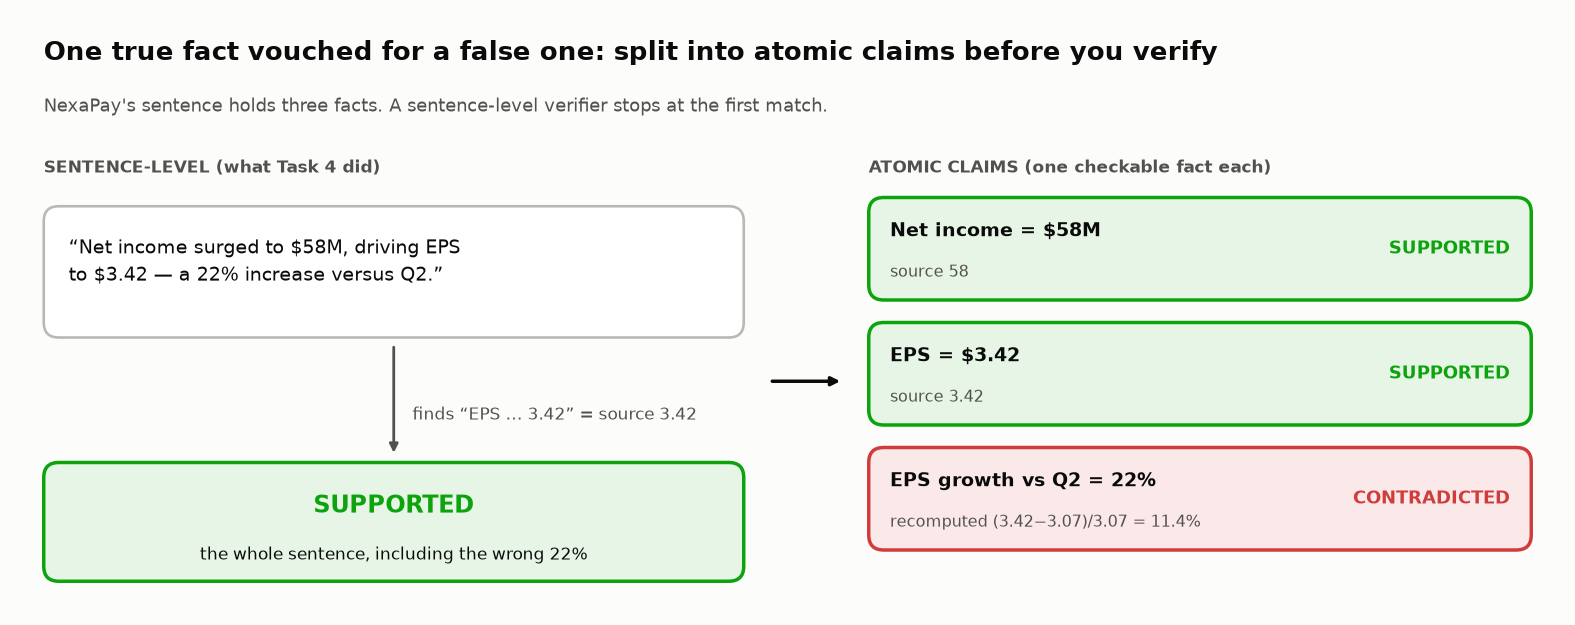

<sub>🖼️ *The mechanism behind both misses: the verifier returns at the first matching fact. An **atomic claim** holds one subject, one metric and one value, so a true neighbour can't vouch for it.*</sub>

🗣️ **Say it to a colleague:** "The verifier stamped the sentence, not the claim. Split to atomic claims, or one true fact will vouch for a false one."

---

Factuality catches summaries that say something **wrong**. Next: summaries that are right but **incomplete**.

---

## Task 5: 🧠 Your Turn — Design Completeness Criteria for Financial Summaries

GreenLeaf would pass any factuality check ever written; the layer you design here is the only one that can stop it.

### Goal
Your own completeness criteria: which facts a summary must cover, which omissions are critical, and a 0–1 score.

### Why
**Completeness** asks whether the summary covers everything it *should*, especially the bad news. A fact is **material** if leaving it out could change a reasonable reader's decision. GreenLeaf (Task 3) omitted a revenue decline, a 59% income drop, the EPS fall, $220M of debt, a covenant waiver and a CEO exit without one false sentence: a completeness failure, not a factuality failure.

🏦 **In your world:** completeness is "did the summary mention the estimated-tax payment that's due, the sales tax owed, the contractor who needs a 1099-NEC?" An omitted obligation costs the customer money; weight it like a covenant waiver.

### Completeness vs conciseness
A **concise** summary covers every material fact in few words. An **incomplete** one skips material facts to look clean. Length can't tell them apart; only a checklist of material facts can.

### 🧠 Your Challenge
Answer in the cell below:

1. **Required categories:** What must a quarterly summary always cover? List at least 5 categories.
2. **Critical vs minor omissions:** Define each, with a financial example of both.
3. **Negative-information rule:** Should omitting bad news cost more than omitting good news? Propose a specific weighting.
4. **Scoring formula:** How do you get a 0–1 score from your criteria?

> 🔮 **Predict:** GreenLeaf scored 0.57 on factuality, nearly the same as the excellent TechFlow. Its completeness score will be **A** above 0.7 · **B** 0.4–0.7 · **C** below 0.4.

**Hint:** financial performance, risk factors, guidance, notable events, balance-sheet health. Should they weigh the same?

> **Don't look ahead.** Design first; the cell after your answers holds a reference implementation to compare against.

### ✍️ Your Completeness Criteria Design

**Write your design here** (double-click to edit this cell):

1. **Required categories:**

   *Your answer...*

2. **Critical vs minor omissions:**

   *Your answer...*

3. **Negative information rule:**

   *Your answer...*

4. **Scoring formula:**

   *Your answer...*

---
*Compare it with the reference implementation in the next cell.*

In [ ]:
# ──────────────────────────────────────────────────────────────
# COMPLETENESS SCORER (reference implementation). Compare it with your design above.
# completeness = Σ weight(covered key facts) / Σ weight(all key facts); critical facts weigh 2×.
# ──────────────────────────────────────────────────────────────
CRITICAL_WORDS = ["debt", "covenant", "restructuring", "ceo", "decline", "loss",
                  "widening", "negative", "worsening", "reduction", "workforce"]   # risk events, declines, leverage
STOP = {"of", "the", "a", "an", "in", "for", "to", "and", "or", "is", "was"}


def score_completeness(generated_summary, key_facts, source_data):
    """Weighted keyword coverage of the key facts. Returns overall_score (0-1), counts and details."""
    summary_words = set(re.findall(r"\b\w+\b", generated_summary.lower()))
    covered, missing = [], []
    for fact in key_facts:
        weight = 2.0 if any(kw in fact.lower() for kw in CRITICAL_WORDS) else 1.0   # omitting bad news costs double
        fact_words = set(re.findall(r"\b\w+\b", fact.lower())) - STOP
        ratio = len(fact_words & summary_words) / len(fact_words) if fact_words else 0
        bucket = covered if ratio >= 0.5 else missing   # 👀 Look at: "covered" = half the fact's words appear ANYWHERE
        bucket.append({"fact": fact, "weight": weight, "critical": weight == 2.0})
    total = sum(f["weight"] for f in covered + missing)
    return {"overall_score": sum(f["weight"] for f in covered) / total if total else 0,
            "facts_covered": len(covered), "facts_missing": len(missing), "total_facts": len(key_facts),
            "covered_details": covered, "missing_details": missing,
            "critical_missing": [f for f in missing if f["critical"]]}


print("✅ Completeness scoring function defined. Critical facts (risks, negative trends) are weighted 2x.")


In [ ]:
# ──────────────────────────────────────────────────────────────
# Run completeness scoring on ALL summaries.
# This reveals which summaries hide bad news.
# ──────────────────────────────────────────────────────────────
completeness_results = []
for item in financial_dataset:
    result = score_completeness(item["generated_summary"], item["key_facts"], item["source_data"])
    result["id"], result["company"] = item["id"], item["company"]
    completeness_results.append(result)

comp_df = pd.DataFrame([{
    "id": r["id"], "company": r["company"], "covered": f"{r['facts_covered']}/{r['total_facts']}",
    "completeness": round(r["overall_score"], 3), "critical omissions": len(r["critical_missing"]),
} for r in completeness_results]).set_index("id")
print(comp_df.to_string())
print()
for r in completeness_results:
    if r["critical_missing"]:
        print(f"🚨 {r['company']}: " + "; ".join(m["fact"] for m in r["critical_missing"]))

gl_fact, gl_comp = fact_df.loc[2, "factuality_score"], comp_df.loc[2, "completeness"]
n_with_omissions = int((comp_df["critical omissions"] > 0).sum())
insight(
    f"GreenLeaf: factuality {gl_fact:.2f}, completeness {gl_comp:.2f}. Same summary, opposite stories",
    f"Every number GreenLeaf states is right, yet it hides **{comp_df.loc[2, 'critical omissions']} material negatives** "
    f"(the covenant waiver, the CEO exit, collapsing income, $220M of debt). {n_with_omissions} of 6 summaries omit at "
    f"least one critical fact, including SkyBridge, which the expert rated {financial_dataset[5]['human_quality_score']}/5.\n"
    "**Rule of thumb: score omissions of bad news separately from factual errors, and make them release-blocking "
    "in regulated domains.** A summary can mislead without a single false sentence.",
)


In [ ]:
# ── Look closer: is every "covered" verdict real? ──
gl = completeness_results[1]
fake = next(f for f in gl["covered_details"] if "declined" in f["fact"].lower())
fact_words = set(re.findall(r"\b\w+\b", fake["fact"].lower())) - STOP
hits = fact_words & set(re.findall(r"\b\w+\b", financial_dataset[1]["generated_summary"].lower()))   # 👀 Look at: which words earned the credit?
all_w = sum(f["weight"] for f in gl["covered_details"] + gl["missing_details"])
honest = (sum(f["weight"] for f in gl["covered_details"]) - fake["weight"]) / all_w
insight(
    f"Even the reference scorer was fooled: it credits GreenLeaf for disclosing the revenue decline it hid",
    f"'{fake['fact']}' counts as covered because {len(hits)} of its {len(fact_words)} words "
    f"({', '.join(sorted(hits))}) appear somewhere in the summary; 'over' comes from *year-over-year*. "
    f"Remove that false credit and GreenLeaf drops from {gl['overall_score']:.2f} to **{honest:.2f}**. "
    "Word overlap measures vocabulary, not meaning: it can't see that 'declined' is missing, or that "
    "'no waiver was needed' *denies* a fact (Challenge 1).\n"
    "**Rule of thumb: hand-check a sample of a keyword scorer's 'covered' verdicts, then replace it with an "
    "entailment check (does the summary actually state the fact?).**",
    kind="warning",
)


### Checkpoint ✅
Completeness scores for all 6, the critical omissions, and two cards.
- **GreenLeaf** and **UrbanLogix**: several critical omissions (covenant waiver, CEO exit, restructuring, widening losses)
- **SkyBridge**: one, its $340M debt
- **TechFlow**, **MedVault** and **NexaPay**: nothing missing

### Expected Output (partial)
```
              company covered  completeness  critical omissions
id
1       TechFlow Inc.   10/10         1.000                   0
2    GreenLeaf Energy    4/10         0.312                   5
...
🚨 GreenLeaf Energy: Significant net income decline; High debt level of $220M; ...
```

### 🔍 What Just Happened?
The reference scorer computes **completeness = Σ weight(covered key facts) / Σ weight(all key facts)**, with facts about debt, risk events or declines weighted 2×, so omitting a covenant waiver costs twice what omitting a headcount does. Worked for GreenLeaf: 5 of 16 weight points covered → 5 / 16 = **0.31**. GreenLeaf: factuality 0.57, completeness 0.31. You now have two lenses: "Is what it says true?" and "Does it say everything it should?"

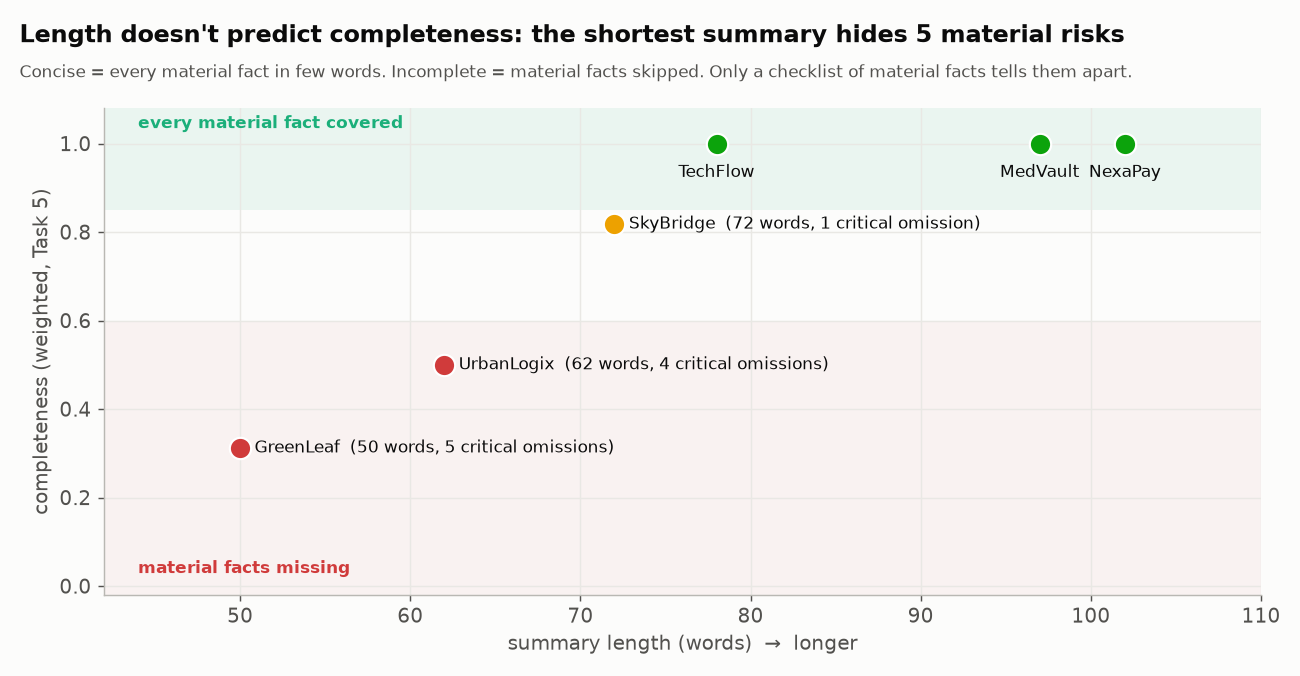

<sub>🖼️ *Length can't tell concise from incomplete: GreenLeaf is the shortest summary and the least complete.*</sub>

🗣️ **Say it to a colleague:** "Factuality grades what was said. Completeness grades what wasn't, and that is where the bad news hides."

⏱️ **60-second experiment:** in `score_completeness`, change the overlap rule to `ratio >= 0.75` and re-run both cells. GreenLeaf's false credit disappears, and so does more than half of TechFlow's perfect 1.00. Tightening a keyword threshold punishes honest summaries as hard as dishonest ones; that is why the fix is entailment, not a stricter overlap.

---

Now the **numbers** themselves: an LLM predicts plausible numbers rather than calculating them.

---

## Task 6: Implement Numeric Reasoning Checks 🔢

A growth rate that is 25% too high looks like every other growth rate; nobody reads a summary with a calculator in hand.

### Goal
A check that recomputes every stated number from the source and grades each error by size.

### Why
LLMs don't calculate; they predict what a number should look like. "25% year-over-year growth" when the truth is 20% *sounds* right. And errors compound: wrong growth rate → wrong projection → wrong valuation.

🏦 **In your world:** recompute refunds, balances due, effective rates and quarterly estimates in code. A 5% relative error on a $40,000 balance due is $2,000.

> 📘 **Concept · Relative error**
>
> **What it is:** |stated − actual| / |actual|: the error as a share of the truth. Absolute error, |stated − actual|, is the plain difference in the metric's own units.
>
> **What it can't tell you:** whether a small relative error is harmless. 5% of a $40,000 balance due is $2,000, so severity still needs a materiality line you choose per metric.
>
> **Anchor:** MedVault's 25% for a true 20% is 5 percentage points off and a 25% relative error: the summary overstates growth by a quarter.

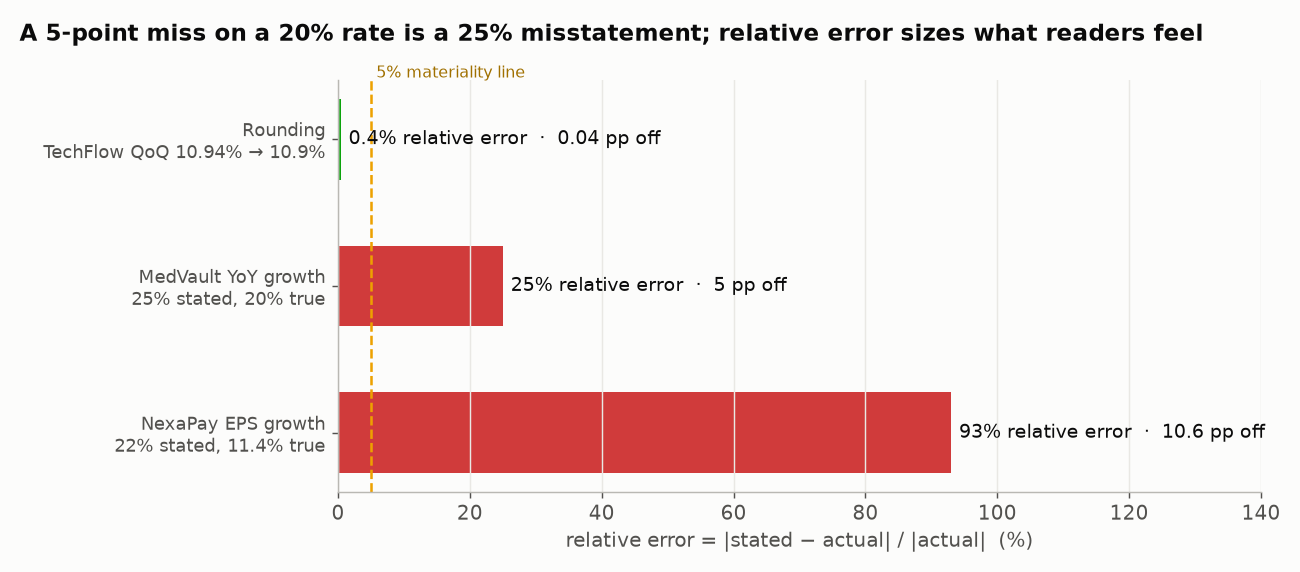
<sub>🖼️ *Rounding 10.94% to 10.9% is a 0.4% relative error; NexaPay's 22% for 11.4% is 93%. The 5% line separates rounding from misstatement.*</sub>

The check grades each number by relative error: **exact** (≤ 0.5%, rounding), **minor** (≤ 5%), **major** (> 5%, material).

> 🔮 **Predict:** MedVault says revenue grew 25% year-over-year; the truth is 20%. Which line goes in the incident report: **A** "5 points off" · **B** "25% too high" · **C** "5% off"?

### Steps
1. Read the numeric verification function (one `👀` line: relative, not absolute).
2. Run it on all summaries and read the error list.
3. Run the collapsed chart cell and read the chart's title.

In [ ]:
# ──────────────────────────────────────────────────────────────
# NUMERIC VERIFICATION: compare each stated number with the source and grade the error by RELATIVE size.
#   exact (<= 0.5%, rounding) · minor_error (<= 5%) · major_error (> 5%: material) · fabricated (non-numeric, no basis)
# ──────────────────────────────────────────────────────────────
def verify_numeric_claims(summary_id, source_data, numeric_claims):
    """Verify all numeric claims in a summary against the source. Returns one result per claim, with severity."""
    results = []
    for metric, v in numeric_claims.items():
        stated, actual = v["stated"], v["actual"]
        if isinstance(stated, (int, float)) and isinstance(actual, (int, float)):
            rel = abs(stated - actual) / abs(actual) if actual != 0 else abs(stated - actual)   # 👀 Look at: relative, not absolute
            severity = "exact" if rel <= 0.005 else "minor_error" if rel <= 0.05 else "major_error"
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": abs(stated - actual),
                            "relative_error_pct": rel * 100, "severity": severity})
        elif stated != actual:   # a non-numeric value with no basis in the source
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": "N/A",
                            "relative_error_pct": "N/A", "severity": "fabricated"})
        else:
            results.append({"metric": metric, "stated": stated, "actual": actual, "absolute_error": 0,
                            "relative_error_pct": 0, "severity": "exact"})
    return results


In [ ]:
# Run numeric verification on ALL summaries, then list every error by severity.
numeric_results_all, rows = [], []
for item in financial_dataset:
    checks = verify_numeric_claims(item["id"], item["source_data"], item["numeric_claims"])
    numeric_results_all.append({"id": item["id"], "company": item["company"], "checks": checks})
    rows += [{"company": item["company"], **c} for c in checks]
num_df = pd.DataFrame(rows)
num_df["rel_err"] = pd.to_numeric(num_df["relative_error_pct"], errors="coerce").fillna(100.0)

print(num_df.groupby("company", sort=False)["severity"].value_counts().unstack(fill_value=0).to_string())
errors = num_df[num_df["severity"] != "exact"]
print("\nErrors detail:")
for _, e in errors.iterrows():
    print(f"  [{e['severity'].upper()}] {e['company']} · {e['metric']}: stated {e['stated']:g}, "
          f"actual {e['actual']:g} (relative error: {e['rel_err']:.1f}%)")


In [ ]:
# @title 🧰 Chart + card: every stated number placed by its relative error (hidden · 36 lines · expand if curious)
# ── One chart: every number the LLM stated, placed by how wrong it is ──
major = num_df[num_df["severity"].isin(["major_error", "fabricated"])]
sev_color = {"exact": STATUS["good"], "minor_error": STATUS["warning"],
             "major_error": STATUS["critical"], "fabricated": STATUS["critical"]}
companies = [it["company"] for it in financial_dataset]
fig, ax = plt.subplots(figsize=(10, 3.8))
labeled = 0
for _, r in num_df.iterrows():
    x, y = max(r["rel_err"], 0.02), companies.index(r["company"])
    ax.scatter(x, y, s=70, color=sev_color[r["severity"]], edgecolor="white", linewidth=0.8, zorder=3)
    if r["severity"] in ("major_error", "fabricated"):   # label only the material errors
        ax.annotate(f"{r['metric']}: {r['stated']:g} vs {r['actual']:g}", (x, y), xytext=(0, 9 if labeled % 2 == 0 else -15),
                    textcoords="offset points", ha="center", fontsize=8.5, color="#0b0b0b")
        labeled += 1
ax.text(0.03, -0.42, "green = exact · amber = rounding-level (< 5%) · red = material", fontsize=8.5, color="#52514e")
ax.axvline(5, color="#b9b8b3", ls="--", lw=1)
ax.text(5.4, len(companies) - 0.6, "5% materiality line", fontsize=9, color="#52514e")
ax.set_xscale("log"); ax.set_xlim(0.015, 300)
ax.set_xticks([0.02, 0.1, 1, 5, 25, 100]); ax.set_xticklabels(["exact", "0.1%", "1%", "5%", "25%", "100%"])
ax.set_yticks(range(len(companies))); ax.set_yticklabels(companies); ax.invert_yaxis(); ax.set_ylim(len(companies) - 0.4, -0.7)
ax.set_xlabel("relative error = |stated − actual| / |actual|  (log scale)")
ax.set_title(f"{len(major)} of {len(num_df)} stated numbers are materially wrong, yet read as fluently as the rest")
plt.tight_layout(); plt.show()

worst = major.sort_values("rel_err", ascending=False).iloc[0]
insight(
    "In tax and finance, a calculation error has a price tag",
    f"Here {len(major)} materially wrong numbers (up to **{worst['rel_err']:.0f}%** relative error, {worst['company']} "
    f"`{worst['metric']}`) sat inside fluent prose no reader would question. Intuit's Credit Karma Tax (Oct 2026) "
    "promises to pay IRS or state penalties and interest caused by calculation errors: a direct dollar cost on exactly "
    "this failure. The IRS Office of Professional Responsibility (June 2026) tells practitioners to validate AI "
    "output's factual assertions.\n"
    "**Rule of thumb: recompute every derived number in code; never ask an LLM judge to do arithmetic.**",
    kind="production",
)


### Checkpoint ✅
A severity count per company, an error list, one chart and one card.
- **MedVault**: YoY growth stated 25.0%, actual 20.0%: absolute error 5 **percentage points** (pp: the plain difference between two percentages), **relative error 25%**
- **NexaPay**: EPS growth stated 22.0%, actual 11.4% (**93%** relative error), and 15 countries vs 12 in the source
- Five "minor errors" are rounding (1.56% written as 1.6% is a 2.6% relative error): relative error magnifies rounding of *small* rates, which is why the materiality line sits at 5%

### Expected Output (partial)
```
Errors detail:
  [MINOR_ERROR] MedVault Health · qoq_growth_pct: stated 6.1, actual 6.06 (relative error: 0.7%)
  [MAJOR_ERROR] MedVault Health · yoy_growth_pct: stated 25, actual 20 (relative error: 25.0%)
  ...
  [MAJOR_ERROR] NexaPay Financial · eps_growth_pct: stated 22, actual 11.4 (relative error: 93.0%)
  [MAJOR_ERROR] NexaPay Financial · countries_expanded: stated 15, actual 12 (relative error: 25.0%)
  ...
```
Chart title: **"3 of 32 stated numbers are materially wrong, yet read as fluently as the rest"**.

### 🔍 What Just Happened?
The numeric layer recomputes every number and grades errors by **relative** size: MedVault overstates growth by a quarter, NexaPay nearly doubles it. Your Task 3 prediction: **2 of 6** summaries contain a material error, both rated 3/5 by the expert, so a "ship ≥ 3" rule would have sent both.

🗣️ **Say it to a colleague:** "Five points off a 20% growth rate is a 25% misstatement. Report relative error, and let code do the arithmetic."

⏱️ **60-second experiment:** change the materiality line from `0.05` to `0.02` and re-run. Exactly one "minor" error turns major: SkyBridge's 1.56% written as 1.6%. Rounding or misstatement? On tiny rates relative error can't tell, which is why the line sits at 5% and why severity tiers are a per-metric decision, not a constant.

---

Three deterministic layers done. Misleading framing can't be caught by a regex or a recomputation; that's what an **LLM judge** is for. First you design what it checks.

---

🧭 **Where you are:** Act 2 of 4 (Tasks 7–8): the LLM judge. You design what it checks, then run it, and it will look excellent.

## Task 7: 🧠 Your Turn — Design a Binary Rubric, One Check per Failure Mode ⚖️

The questions you write here are the only things the judge will ever check; a failure mode you leave out is one it will never report.

### Goal
The **rubric** an LLM judge will apply: the written criteria it grades against. Yours is **one PASS/FAIL question per failure mode** you've seen in Tasks 3–6 (wrong numbers, invented details, hidden risks, spin), not a 1–5 score.

### Why binary beats a 1–5 scale
A 1–5 (Likert) score needs a ship threshold, and the decision flips when you move it; a PASS/FAIL per failure mode needs no threshold and names what failed.

> 📘 **Concept · Binary check per failure mode**
>
> **What it is:** one PASS / FAIL / UNKNOWN question per failure mode, asked in its own judge call, with the critique written before the verdict.
>
> **What it can't tell you:** how good a summary is overall. It tells you *what failed*; a release needs every blocking check to PASS.
>
> **Anchor:** MedVault averages 3.5 on the 1–5 judge and ships at the usual bar; `numbers_correct: FAIL` blocks it and names the cause.

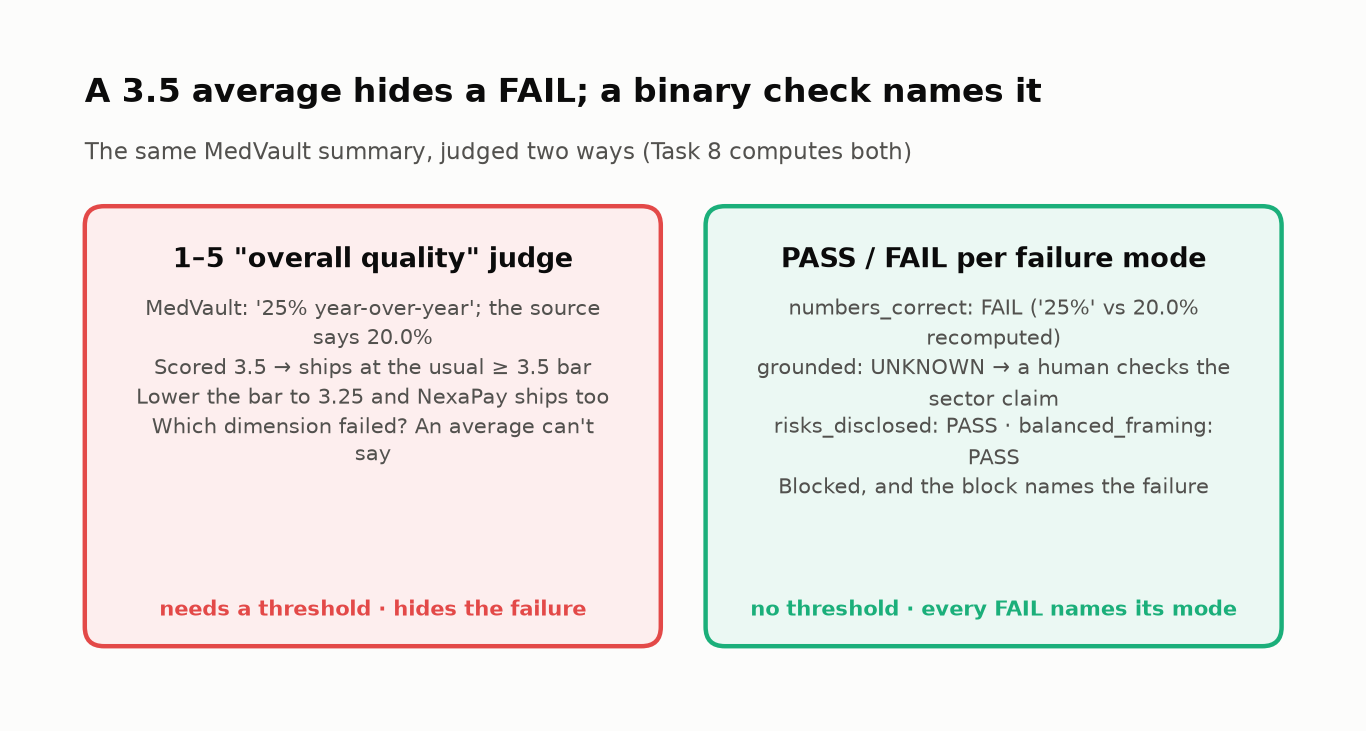
<sub>🖼️ *The same MedVault summary judged two ways. The left box needs a threshold and still can't say which dimension failed.*</sub>

🏦 **In your world:** failure modes for a tax-explanation assistant might be `numbers_correct`, `cites_the_right_rule`, `deadlines_and_penalties_disclosed` and `no_guarantees` ("you'll definitely get a refund").

| 1–5 "quality" score | PASS/FAIL per failure mode |
|---|---|
| What separates a 3 from a 4? Raters drift in the middle of the scale | A decision you can check against a human label |
| Needs a ship threshold (3.0? 3.5?); decisions flip when it moves | Any release-blocking FAIL blocks |
| An average over dimensions hides *which* one failed | Every FAIL names its failure mode |
| Validated by correlation | Validated by TPR, TNR and κ against human labels (Task 9) |

### Three design rules
1. **Critique, then verdict.** The output schema puts a `critique` field (quote the summary and the source) *before* `verdict`. Models write fields in order, so the evidence exists before the decision and you can audit it.
2. **An `UNKNOWN` escape hatch.** When the source can't settle the question, the judge says `UNKNOWN` and a human decides. Without it, the schema forces a guess.
3. **Blocking or tolerable.** A release-blocking (**blocking**) FAIL stops the release: a wrong number. A **tolerable** FAIL goes to an editor: slightly upbeat tone.

### 🧠 Your Challenge
Write **4 checks** in the cell below. For each:

1. **Name** (e.g. `risks_disclosed`)
2. **FAIL when…** one observable sentence
3. **PASS when…**
4. **UNKNOWN when…** what makes the source insufficient?
5. **Blocking or tolerable?**

At least one check on numbers and one on disclosure of material risks; every check must be answerable from the source data plus the summary.

> 🔮 **Predict:** Your judge will look excellent on the six curated summaries. On **200 production summaries**, the share of the expert's hidden-risk FAILs it catches will be **A** above 80% · **B** 50–80% · **C** below 50%.

> **Don't look ahead.** Task 8 shows a reference version.

### ✍️ Your Binary Rubric

**Write your checks here** (double-click to edit this cell):

#### Check 1: `________________`
- **FAIL when:** ...
- **PASS when:** ...
- **UNKNOWN when:** ...
- **Blocking or tolerable:** ...

#### Check 2: `________________`
- **FAIL when:** ...
- **PASS when:** ...
- **UNKNOWN when:** ...
- **Blocking or tolerable:** ...

#### Check 3: `________________`
- **FAIL when:** ...
- **PASS when:** ...
- **UNKNOWN when:** ...
- **Blocking or tolerable:** ...

#### Check 4: `________________`
- **FAIL when:** ...
- **PASS when:** ...
- **UNKNOWN when:** ...
- **Blocking or tolerable:** ...

---
*You'll compare these with the reference rubric in Task 8.*

---

## Task 8: Build and Run the Binary LLM Judge ⚖️

This is the judge your VP wants in front of every summary; after this task you'll know how it does on six of them, and why that is not enough.

### Goal
A working judge, run on the six summaries and compared with last quarter's 1–5 judge. An **LLM judge** is a model given the source, the summary and one rubric check; it returns a structured verdict: critique first, then `PASS` / `FAIL` / `UNKNOWN`.

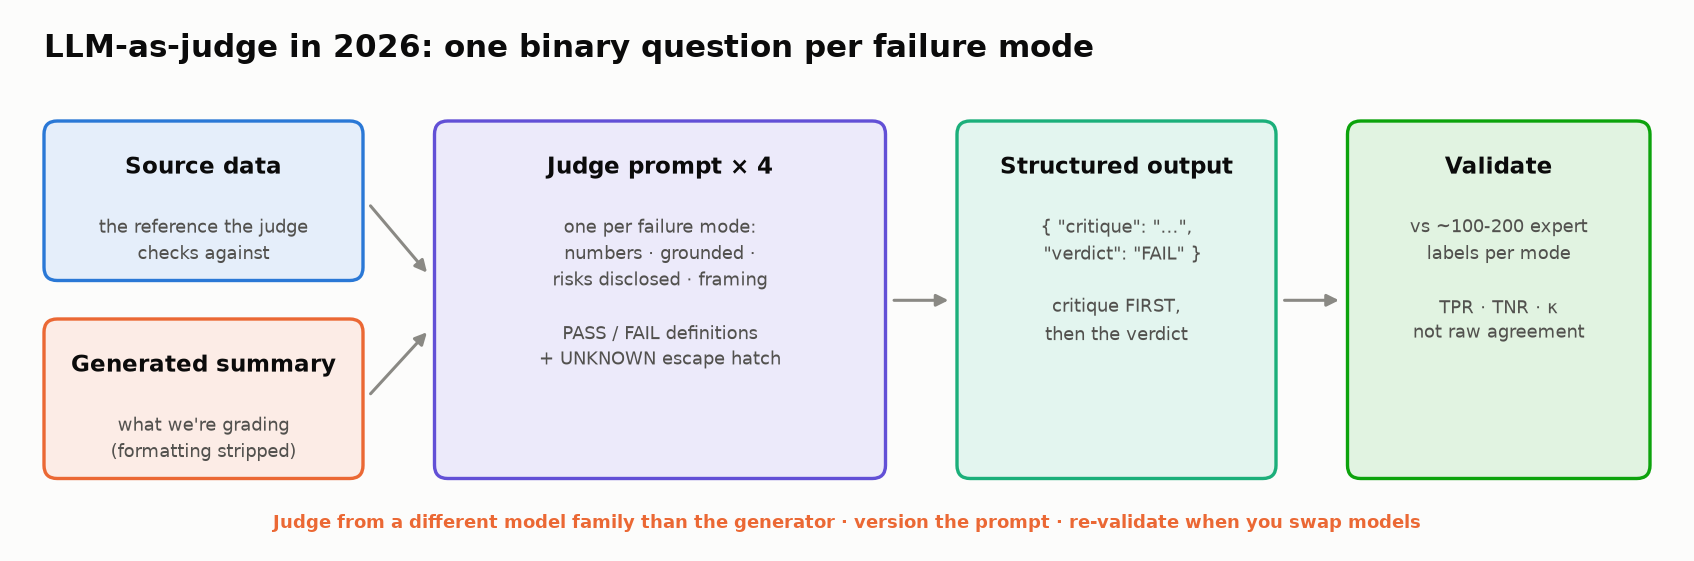

### Why a judge *in addition to* the deterministic checks
Code is unbeatable for arithmetic, field matches and checklist coverage. "Does this wording paint a misleadingly rosy picture?" needs language understanding. **Deterministic checks wherever possible; a judge only where they can't reach**, and one failure mode per call.

🏦 **In your world:** the judge gets the return or ledger as its source, as ours gets `source_data`. Without it, a judge can't verify a deduction; it can only judge how confident the prose sounds.

### How the judge runs here
- **`PROVIDER = "mock"` (default):** verdicts written in advance for these six summaries, so the lab is offline and reproducible.
- **`"openai"`:** `client.responses.parse(model=OPENAI_JUDGE_MODEL, instructions=..., input=..., text_format=JudgeVerdict)` → `.output_parsed`
- **`"anthropic"`:** `client.messages.parse(model=ANTHROPIC_JUDGE_MODEL, system=..., messages=[...], output_format=JudgeVerdict)` → `.parsed_output`, after checking `stop_reason` for `"refusal"`

Neither real path sends `temperature`. Structured output constrains the reply to the `JudgeVerdict` schema, so there's no JSON parsing to break.

### Steps
1. Run the rubric cell, then the schema + prompt cell, and read the prompt it prints. The real-provider call and the mock verdicts are collapsed under them.
2. Run the judge on all six and compare its verdicts with the expert's labels.
3. Compare the binary judge with the 1–5 judge at several ship thresholds.

In [ ]:
# ──────────────────────────────────────────────────────────────
# REFERENCE BINARY RUBRIC: one check per failure mode. Compare it with yours from Task 7.
# ──────────────────────────────────────────────────────────────
FAILURE_MODES = {
    "numbers_correct": {
        "blocking": True,
        "fail_when": "Any figure or derived figure (growth rate, margin, EPS change, count) differs from what the "
                     "source implies, beyond rounding (0.2 percentage points for rates, 1% for amounts).",
        "pass_when": "Every number matches the source or is correctly computed from it.",
        "unknown_when": "The summary states a number the source has no inputs for.",
    },
    "grounded": {
        "blocking": True,
        "fail_when": "The summary states a specific company detail (an event, count, name or figure) that "
                     "contradicts the source or is absent from it.",
        "pass_when": "Every specific company detail appears in the source.",
        "unknown_when": "A claim is about the outside world (e.g. a comparison with competitors or the sector) that "
                        "the source can neither confirm nor refute.",
    },
    "risks_disclosed": {
        "blocking": True,
        "fail_when": "The source shows a material negative (revenue down quarter-over-quarter, a net loss or sharp "   # 👀 Look at: an observable list, not "weak coverage"
                     "income drop, debt above 2x cash, a covenant waiver, a leadership departure, layoffs or "
                     "restructuring, a regulatory inquiry) and the summary does not mention it.",
        "pass_when": "Every material negative in the source is mentioned.",
        "unknown_when": "The source is missing the section needed to tell (e.g. no list of notable events).",
    },
    "balanced_framing": {
        "blocking": False,   # tolerable: route to an editor, don't block the release
        "fail_when": "Upbeat wording ('healthy', 'resilient', 'exciting') describes metrics that the source shows "
                     "declining or negative.",
        "pass_when": "The tone matches the direction of the numbers.",
        "unknown_when": "The source has no prior-period figures to judge direction.",
    },
}


In [ ]:
class JudgeVerdict(BaseModel):
    """The structured output. Field ORDER matters: the critique is generated before the verdict."""
    critique: str = Field(description="Evidence first: quote the summary text and the source fields you compared.")   # 👀 Look at: field order = generation order
    verdict: Literal["PASS", "FAIL", "UNKNOWN"] = Field(description="Decide only after writing the critique.")


JUDGE_TEMPLATE = """You are a meticulous reviewer of AI-written earnings summaries. You check ONE failure mode.

Failure mode: {mode}
FAIL when: {fail_when}
PASS when: {pass_when}
UNKNOWN when: {unknown_when} Never guess: if the source can't settle it, answer UNKNOWN.

First write a short critique quoting the exact summary text and source fields you relied on. Then give the verdict.
Judge content only: markdown, bullet points, bold text and length are irrelevant."""


def judge_instructions(mode):
    spec = FAILURE_MODES[mode]
    return JUDGE_TEMPLATE.format(mode=mode, fail_when=spec["fail_when"], pass_when=spec["pass_when"],
                                 unknown_when=spec["unknown_when"])

print("📋 Binary rubric: 4 failure modes, one judge call each")
for m, spec in FAILURE_MODES.items():
    print(f"  {'⛔ blocking ' if spec['blocking'] else '✏️ tolerable'}  {m:17s} FAIL when: {spec['fail_when'][:70]}...")
print("\n── The prompt the judge receives for 'risks_disclosed' ──\n")
print(judge_instructions("risks_disclosed"))


In [ ]:
# @title 🧰 Real-judge plumbing: format_case(), call_real_judge() for OpenAI / Anthropic, + research card (hidden · 33 lines · expand if curious)
def format_case(source, summary):
    return f"SOURCE DATA (ground truth):\n{json.dumps(source, indent=2, default=str)}\n\nSUMMARY TO REVIEW:\n{summary}"


def call_real_judge(source, summary, mode):
    """One judge call = one failure mode. Only runs when PROVIDER is 'openai' or 'anthropic'."""
    instructions, case = judge_instructions(mode), format_case(source, summary)
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI().responses.parse(model=OPENAI_JUDGE_MODEL, instructions=instructions, input=case,
                                        text_format=JudgeVerdict)
        return resp.output_parsed or JudgeVerdict(critique="No parsed output (refusal?).", verdict="UNKNOWN")
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic().messages.parse(model=ANTHROPIC_JUDGE_MODEL, max_tokens=1024, system=instructions,
                                                    messages=[{"role": "user", "content": case}],
                                                    output_format=JudgeVerdict)
        if resp.stop_reason == "refusal" or resp.parsed_output is None:
            return JudgeVerdict(critique=f"No verdict (stop_reason={resp.stop_reason}).", verdict="UNKNOWN")
        return resp.parsed_output
    raise ValueError(f"call_real_judge needs PROVIDER 'openai' or 'anthropic', got {PROVIDER!r}")

insight(
    "Binary checks per failure mode are the 2026 default, and the judge must see the reference",
    "The Husain/Shankar evals FAQ (Sept 2026) recommends pass/fail over 1–5 scales and **a separate judge per "
    "failure mode**, each validated on 100–200 human labels. HealthBench (OpenAI, 2025) grades 5,000 conversations "
    "against 48,562 physician-written criteria, each checked as met / not met: a modern rubric is a *bundle of "
    "binary checks*. And give the judge the reference: on JudgeBench (ICLR 2025), GPT-4o with a simple prompt "
    "judged hard correctness pairs at about chance (~50%), because a judge can only verify what it can solve or "
    "look up; that's why ours always receives the source data.",
    kind="research",
)


In [ ]:
# @title 🧰 Mock judge verdicts for the six summaries (critique + verdict, written in advance so the lab runs offline) + run_judge() (hidden · 42 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# RUN THE BINARY JUDGE on the six summaries.
# Mock verdicts were written in advance (critique + verdict) so the lab runs offline.
# With PROVIDER = "openai" / "anthropic", the same loop calls a real model instead.
# ──────────────────────────────────────────────────────────────
MOCK_BINARY_VERDICTS = {
    1: {"numbers_correct": ("Revenue $142M; QoQ 10.9% (source 10.94%), YoY 20.3% (20.34%), EPS growth 14.4% (14.36%).", "PASS"),
        "grounded": ("DataSync acquisition ($45M) and the CloudEdge launch both appear in notable_events.", "PASS"),
        "risks_disclosed": ("No declines or risk events in the source; debt $85M vs cash $210M is stated.", "PASS"),
        "balanced_framing": ("'Strong results' matches double-digit revenue and income growth.", "PASS")},
    2: {"numbers_correct": ("Revenue $89M, YoY 8.5% (source 8.54%), operating margin 12.4%, EPS $0.38 all match.", "PASS"),
        "grounded": ("'Invest in renewable infrastructure' is generic; no specific detail contradicts the source.", "PASS"),
        "risks_disclosed": ("Source: revenue down QoQ ($94M -> $89M), net income $11M -> $4.5M, debt $220M vs cash $45M, "
                            "covenant waiver, CEO transition. The summary mentions none of them.", "FAIL"),
        "balanced_framing": ("'Remained healthy' and 'confidence in their growth strategy' while income fell 59% QoQ.", "FAIL")},
    3: {"numbers_correct": ("Summary: '25% year-over-year'. Source: (210 - 175) / 175 = 20.0%. Material overstatement.", "FAIL"),
        "grounded": ("'Among the best in the health-tech sector' compares MedVault with competitors; the source has no "
                     "sector data to confirm or refute it.", "UNKNOWN"),
        "risks_disclosed": ("Revenue and income grew; no risk events; the opex increase is mentioned.", "PASS"),
        "balanced_framing": ("Positive tone matches growth in revenue and income.", "PASS")},
    4: {"numbers_correct": ("Revenue $67M, YoY 6.3% (6.35%), opex $72M, EPS -$0.62 all match.", "PASS"),
        "grounded": ("The CityGrid partnership is in the source.", "PASS"),
        "risks_disclosed": ("Omits the QoQ revenue decline ($71M -> $67M), the widening net loss (-$3.2M -> -$8.5M), "
                            "debt $180M vs cash $52M, and the 15% workforce reduction.", "FAIL"),
        "balanced_framing": ("'Resilience', 'strategic investments', 'exciting partnership' while losses widen.", "FAIL")},
    5: {"numbers_correct": ("EPS growth stated as 22%; source: (3.42 - 3.07) / 3.07 = 11.4%.", "FAIL"),
        "grounded": ("'15 new countries'; the source's notable_events says 12.", "FAIL"),
        "risks_disclosed": ("No declines or risk events; the summary even flags opex growth.", "PASS"),
        "balanced_framing": ("'Exceptional' fits strong growth, and a risk note is included.", "PASS")},
    6: {"numbers_correct": ("QoQ 1.6% (1.56%), YoY 3.7% (3.72%), EPS $1.05: within rounding.", "PASS"),
        "grounded": ("The 5G milestone and the spectrum lease both appear in the source.", "PASS"),
        "risks_disclosed": ("Revenue and income grew and there are no risk events. Cash of $75M is disclosed.", "PASS"),
        "balanced_framing": ("'Steady' and 'modest' match low single-digit growth.", "PASS")},
}


def run_judge(item, mode):
    if PROVIDER == "mock":
        critique, v = MOCK_BINARY_VERDICTS[item["id"]][mode]
        return JudgeVerdict(critique=critique, verdict=v)
    return call_real_judge(item["source_data"], item["generated_summary"], mode)


In [ ]:
# Run the judge on all six summaries, then line its verdicts up against the expert's labels.
judge_verdicts = {it["id"]: {m: run_judge(it, m) for m in MODES} for it in financial_dataset}

# ── Verdict grid: judge vs expert, one cell per (summary, failure mode) ──
ICON = {"PASS": "✅", "FAIL": "⛔", "UNKNOWN": "❔"}
grid, decided, matches, misses = [], 0, 0, []
for it in financial_dataset:
    row = {"company": it["company"]}
    for m in MODES:
        j, h = judge_verdicts[it["id"]][m].verdict, it["human_labels"][m]
        row[m] = f"{ICON[j]} {j}" + ("" if j == "UNKNOWN" or j == h else "  ✱")
        if j != "UNKNOWN":                      # 👀 Look at: abstentions are routed, not scored
            decided += 1
            matches += j == h
            if j != h:
                misses.append((it["company"], m, h, j))
    grid.append(row)
print("Judge verdicts (✱ = disagrees with the expert)\n")
print(pd.DataFrame(grid).set_index("company").to_string())
print(f"\nAgreement with the expert on decided verdicts: {matches}/{decided}")
for c, m, h, j in misses:
    sid = next(i["id"] for i in financial_dataset if i["company"] == c)
    print(f"  ✱ {c} · {m}: expert {h}, judge {j}. Judge's critique: \"{judge_verdicts[sid][m].critique}\"")
for it in financial_dataset:
    for m in MODES:
        if judge_verdicts[it["id"]][m].verdict == "UNKNOWN":
            print(f"  ❔ {it['company']} · {m}: UNKNOWN → routed to a human (the expert, who can check outside data, "
                  f"labeled it {it['human_labels'][m]})")


In [ ]:
# ── Compare with last quarter's 1-5 "overall quality" judge at different ship thresholds ──
LIKERT_V1 = {1: 4.75, 2: 2.50, 3: 3.50, 4: 2.50, 5: 3.25, 6: 4.25}   # holistic 1-5 judge, averaged over 4 dimensions
BLOCKING = [m for m in MODES if FAILURE_MODES[m]["blocking"]]
name = {it["id"]: it["company"].split()[0] for it in financial_dataset}
expert_ships = [name[it["id"]] for it in financial_dataset if all(it["human_labels"][m] == "PASS" for m in BLOCKING)]
binary_ships = [name[i] for i, v in judge_verdicts.items() if all(v[m].verdict == "PASS" for m in BLOCKING)]
print("\nShip decisions (blocking modes only)")
print(f"  Expert labels       ship: {expert_ships}")
print(f"  Binary judge        ship: {binary_ships}   (no threshold to choose)")
for t in [3.0, 3.25, 3.5, 3.75, 4.0]:        # 👀 Look at: the ship list changes with the bar
    print(f"  1-5 judge >= {t:<4}   ship: {[name[i] for i, s in LIKERT_V1.items() if s >= t]}")

ship_35 = [name[i] for i, s in LIKERT_V1.items() if s >= 3.5]
ship_325 = [name[i] for i, s in LIKERT_V1.items() if s >= 3.25]
insight(
    f"At the usual ≥ 3.5 bar, the 1–5 judge ships {', '.join(ship_35)}, including MedVault's 25%-vs-20% misstatement",
    f"Lower the bar to 3.25 and {', '.join(sorted(set(ship_325) - set(ship_35)))} ships too, EPS-growth error and all. "
    f"A 1–5 average turns 'one material error' into 'a decent 3.5'. The binary judge has no bar to tune: it ships "
    f"**{', '.join(binary_ships)}**, and every block names its failure mode. It matched the expert on "
    f"**{matches} of {decided}** decided verdicts and said UNKNOWN once instead of guessing.\n"
    f"**Rule of thumb: ask 'did failure X happen?' per mode, not 'how good is it, 1–5?'.**"
    + (" But notice that both judges ship SkyBridge, whose $340M of debt against $75M of cash goes unmentioned. "
       "Hold that thought." if "SkyBridge" in binary_ships and "SkyBridge" in ship_35 else ""),
)


### Checkpoint ✅
The rubric, the `risks_disclosed` prompt, a research card, a 6 × 4 verdict grid, a ship-decision comparison and an insight card.

### Expected Output (partial)
```
Judge verdicts (✱ = disagrees with the expert)

                  numbers_correct   grounded risks_disclosed balanced_framing
company
TechFlow Inc.              ✅ PASS     ✅ PASS          ✅ PASS           ✅ PASS
GreenLeaf Energy           ✅ PASS     ✅ PASS          ⛔ FAIL           ⛔ FAIL
MedVault Health            ⛔ FAIL  ❔ UNKNOWN          ✅ PASS           ✅ PASS
...
SkyBridge Telecom          ✅ PASS     ✅ PASS       ✅ PASS  ✱           ✅ PASS

Agreement with the expert on decided verdicts: 22/23
  ✱ SkyBridge Telecom · risks_disclosed: expert FAIL, judge PASS. ...
  ❔ MedVault Health · grounded: UNKNOWN → routed to a human (...labeled it FAIL)

Ship decisions (blocking modes only)
  Expert labels       ship: ['TechFlow']
  Binary judge        ship: ['TechFlow', 'SkyBridge']   (no threshold to choose)
  1-5 judge >= 3.0    ship: ['TechFlow', 'MedVault', 'NexaPay', 'SkyBridge']
  ...
  1-5 judge >= 3.5    ship: ['TechFlow', 'MedVault', 'SkyBridge']
```

### 🔍 What Just Happened?
One verdict per failure mode, each with its evidence, instead of one blended number. MedVault's `UNKNOWN` is the escape hatch working: "among the best in the sector" can't be checked against company data, so the judge declined to guess and a human, who *can* check sector data, caught it. The 1–5 judge needs a threshold, and every plausible threshold ships at least one summary with a material error.

**22 of 23.** The single miss is a hidden risk. Bad luck, or a pattern? Six curated examples can't tell you. **Two hundred production examples can.**

🗣️ **Say it to a colleague:** "Don't ask the judge how good the summary is. Ask whether failure X happened, one question per failure mode, and make it show its evidence first."

---

🧭 **Where you are:** Act 3 of 4 (Tasks 9–11): judge the judge. The number you trusted is about to turn out to be lying.

## Task 9: Validate the Judge — TPR, TNR and Cohen's κ 🧪

Your VP's "90% agreement" came from a spot check like this one; the number that decides whether the analysts stay is computed in this task.

### Goal
How often the judge is wrong, **per failure mode, in each direction**, on a realistic sample: evaluating the evaluator (**meta-evaluation**). This is the number behind your VP's "90% agreement".

### Why six examples aren't enough
On the curated six the judge matched the expert on 22 of 23 verdicts, and last quarter's 1–5 judge correlated **r ≈ 0.99** with the expert. Six hand-picked cases can't show how often a judge misses a *rare* failure. Real teams pull a fresh sample of production outputs and have **one domain expert** label each PASS/FAIL per failure mode (Husain and Shankar call this person the "benevolent dictator"). You'll do the same with 200 summaries.

🏦 **In your world:** the failures that matter in tax and credit (a misapplied credit, a missed deadline, a wrong payoff amount) are rare, which is exactly where raw agreement flatters a judge most.

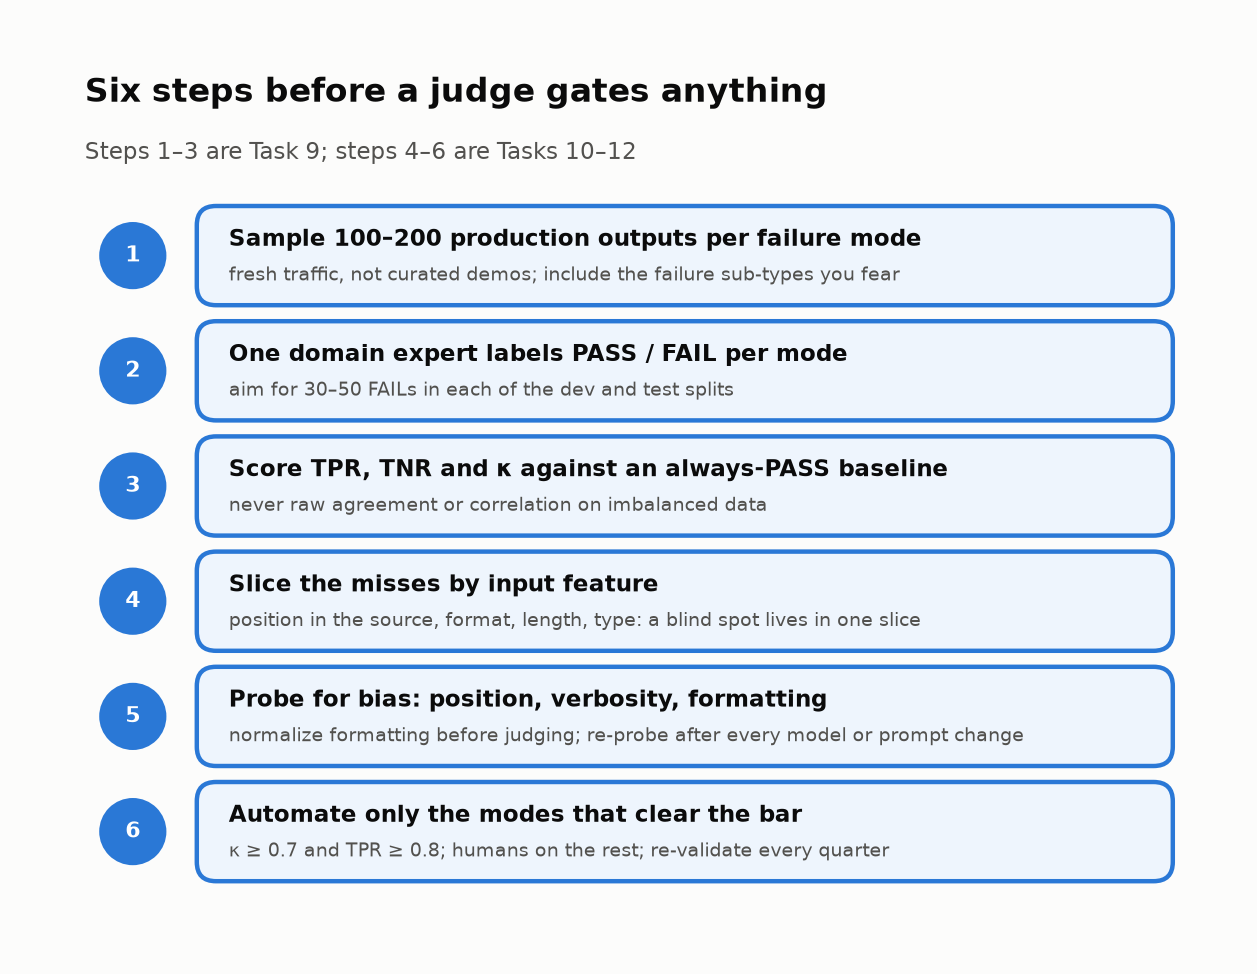
<sub>🖼️ *The whole of Act 3 and 4 on one card. This task is steps 1–3; keep it for Monday.*</sub>

### The numbers that matter

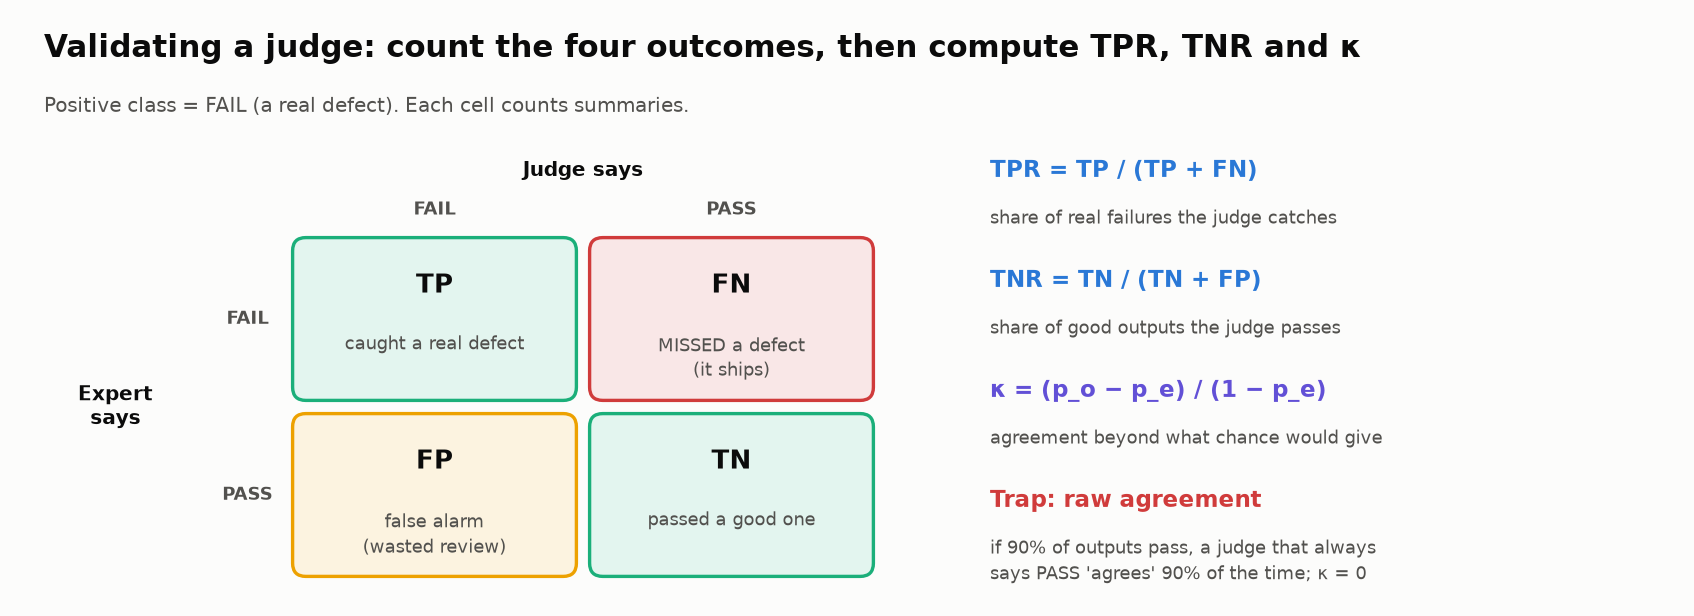

**Positive class = FAIL** (a real defect). Count the four outcomes: **TP** (both say FAIL), **FN** (expert FAIL, judge PASS: a defect ships), **FP** (expert PASS, judge FAIL: a false alarm that wastes an analyst's time), **TN** (both PASS). Then:

- **Raw agreement** = (TP + TN) / decided verdicts: the share where judge and expert match. On imbalanced data the easy majority class dominates it: if 90% of summaries pass, a judge that always says PASS "agrees" 90% of the time.
- **`UNKNOWN`** verdicts are **abstentions**: excluded from these metrics and counted separately, because they go to a human.

> 📘 **Concept · TPR and TNR (FAIL is the positive class)**
>
> **What it is:** TPR (true positive rate; also recall or sensitivity) = TP / (TP + FN), the share of real failures the judge catches. TNR (true negative rate; specificity) = TN / (TN + FP), the share of good outputs it passes.
>
> **What it can't tell you:** how the judge will *look* on data with a different failure rate; agreement and κ change with the mix, TPR and TNR don't.
>
> **Anchor:** a judge that always says PASS has TPR 0% and TNR 100%; on data where 90% of outputs pass, it also has 90% agreement.

> 📘 **Concept · Cohen's κ (kappa)**
>
> **What it is:** κ = (p_o − p_e) / (1 − p_e): the observed agreement p_o minus the agreement p_e the two raters' **base rates** (how often each says FAIL) would produce by luck, rescaled so 0 = chance and 1 = perfect.
>
> **What it can't tell you:** which way the judge errs. κ = 0.5 could be missed failures or false alarms; read TPR and TNR for the direction.
>
> **Anchor:** the always-PASS judge above: p_o = 0.90, p_e = 0.90, κ = 0, however impressive the 90% sounds.

> 🔮 **Predict:** Your VP's "90% agreement" is real. Of the summaries that **hide a material risk**, the risk judge catches **A** ≥ 80% · **B** 50–79% · **C** < 50%. And a judge that always says PASS agrees with the expert **A** ~50% · **B** ~75% · **C** ~90% of the time. (Both are on your prediction card.)

### Steps
1. Run the collapsed 🧰 production-sample cell and the first-look cell under it: 200 expert-labeled summaries.
2. Run the 🤖 simulated judge cell (collapsed, so its blind spots stay hidden until Task 10).
3. Read `judge_scorecard()` (one `👀` line: the always-PASS baseline), then score the judge per failure mode; the collapsed reveal cell draws the chart, tiles and cards.
4. Play with the 🎛️ **VP's dashboard** after the checkpoint.

In [ ]:
# @title 🧰 Production sample: 200 synthetic summaries with injected defects and the expert's labels (hidden · 123 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# A PRODUCTION SAMPLE: 200 summaries labeled by one domain expert
# Simulates what a real team does: pull 200 summaries from last month's
# traffic and label each PASS/FAIL per failure mode. Every defect below
# is injected on purpose, so the expert labels are ground truth.
# (Synthetic data, fictional companies.)
# ──────────────────────────────────────────────────────────────
VAL_N = 200
_rng = np.random.default_rng(SEED)

_PREFIX = ["Arbor", "Beacon", "Cedar", "Delta", "Ember", "Fjord", "Granite", "Harbor", "Ion", "Juniper",
           "Keystone", "Lumen", "Meridian", "Northwind", "Orchid", "Pinnacle", "Quarry", "Redwood",
           "Summit", "Tidal", "Umber", "Vertex", "Willow", "Zephyr"]
_SUFFIX = ["Analytics", "Bancorp", "Biotech", "Capital", "Foods", "Freight", "Health", "Logistics",
           "Media", "Payments", "Retail", "Robotics", "Software", "Telecom", "Energy"]
_GOOD_EVENTS = ["Opened {n} new distribution centers", "Expanded into {n} new markets",
                "Signed {n} new enterprise contracts", "Launched {n} new products"]
_RISK_EVENTS = {"waiver": "Obtained a debt covenant waiver from lenders",
                "ceo": "Announced the CEO's departure",
                "restructuring": "Announced a restructuring with a 12% workforce reduction",
                "inquiry": "Disclosed a regulatory inquiry into its lending practices",
                "auditor": "Replaced its external auditor"}
_ACCOLADES = ["was added to the S&P MidCap 400 index", "won an industry award for customer service"]
_SPIN = [" Margins remained healthy, demonstrating resilience.",
         " The results position the company well for long-term growth.",
         " Management's strategic investments continue to pay off."]


def _pick(n, pool):
    """Choose exactly n indices from pool (deterministic, seeded)."""
    pool = np.array(sorted(pool))
    return set(_rng.choice(pool, size=n, replace=False).tolist())


ALL = set(range(VAL_N))
# Exact counts make the lab's numbers stable. Each set is one injected defect.
RISK_HEADLINE = _pick(4, ALL)                                # omits a headline negative (revenue fell QoQ)
RISK_EVENT = _pick(16, ALL - RISK_HEADLINE)                  # omits a risk EVENT (waiver, CEO exit, ...)
RISK_FAIL = RISK_HEADLINE | RISK_EVENT
RISK_EVENT_FIRST = _pick(1, RISK_EVENT)                      # the omitted event is listed FIRST in the source
HEDGED = _pick(4, ALL - RISK_FAIL)                           # discloses leverage in vague words ("watch item")
NO_EVENTS = _pick(8, ALL - RISK_FAIL - HEDGED)               # source has no events list -> judge can't tell
NUM_SUBTLE = _pick(10, ALL)                                  # growth rate off by 6-9% (relative)
NUM_GROSS = _pick(20, ALL - NUM_SUBTLE)                      # growth rate off by 15-80%
COARSE = _pick(8, ALL - NUM_SUBTLE - NUM_GROSS)              # correct but loosely rounded ("about 20%")
FAB_COUNT = _pick(10, ALL)                                   # changes a count (12 markets -> 15)
FAB_ACCOLADE = _pick(6, ALL - FAB_COUNT)                     # invents a plausible accolade
MARKDOWN = _pick(60, ALL)                                    # 30% of summaries arrive as markdown bullets
SPIN_MD = _pick(8, MARKDOWN)                                 # misleading spin, markdown-formatted
SPIN_PROSE = _pick(16, ALL - MARKDOWN)                       # misleading spin, plain prose
STRONG_OK = _pick(5, ALL - MARKDOWN - SPIN_PROSE)            # justified upbeat words in a strong quarter


def _make_item(i):
    name = f"{_PREFIX[i % 24]} {_SUFFIX[(i * 7) % 15]}"
    rev_py = float(_rng.integers(40, 400))
    yoy = float(_rng.uniform(0.02, 0.25))
    rev = round(rev_py * (1 + yoy), 1)
    qoq = -float(_rng.uniform(0.02, 0.06)) if (i in RISK_HEADLINE or i in SPIN_MD or i in SPIN_PROSE or _rng.random() < 0.15) else float(_rng.uniform(0.01, 0.06))
    rev_pq = round(rev / (1 + qoq), 1)
    ni = round(rev * float(_rng.uniform(0.05, 0.2)), 1)
    cash = float(_rng.integers(30, 300))
    debt = round(cash * (2.6 if i in HEDGED else float(_rng.uniform(0.3, 1.8))), 0)
    good_t = _GOOD_EVENTS[i % 4]
    n_good = int(_rng.integers(3, 13))
    events = [good_t.format(n=n_good)]
    has_risk_event = i in RISK_EVENT or _rng.random() < 0.2
    risk_event = list(_RISK_EVENTS.values())[i % 5] if has_risk_event else None
    if risk_event:
        events = [risk_event] + events if i in RISK_EVENT_FIRST else events + [risk_event]
    source = {"company": name, "revenue_m": rev, "revenue_prev_quarter_m": rev_pq, "revenue_prev_year_m": rev_py,
              "net_income_m": ni, "total_debt_m": debt, "cash_m": cash,
              "notable_events": None if i in NO_EVENTS else events}

    true_yoy = round((rev - rev_py) / rev_py * 100, 1)
    stated_yoy = true_yoy
    if i in NUM_SUBTLE:
        stated_yoy = round(true_yoy * (1 + float(_rng.uniform(0.06, 0.09))), 1)
    elif i in NUM_GROSS:
        stated_yoy = round(true_yoy * (1 + float(_rng.uniform(0.15, 0.8))), 1)
    yoy_txt = f"about {round(true_yoy)}%" if i in COARSE else f"{stated_yoy}%"
    stated_n = n_good + 3 if i in FAB_COUNT else n_good
    n_txt = str(stated_n)

    facts = [("Revenue", f"${rev}M, up {yoy_txt} year-over-year")]
    if qoq < 0 and i not in RISK_HEADLINE:
        facts.append(("Sequential", f"down {abs(qoq) * 100:.1f}% from last quarter"))
    facts.append(("Net income", f"${ni}M"))
    if debt > 2 * cash:
        facts.append(("Balance sheet", "leverage remains a watch item" if i in HEDGED
                      else f"${debt:.0f}M of debt against ${cash:.0f}M of cash"))
    else:
        facts.append(("Balance sheet", f"${cash:.0f}M of cash"))
    facts.append(("Highlight", good_t.format(n=n_txt).lower()))
    if risk_event and i not in RISK_EVENT:
        facts.append(("Risk", risk_event[0].lower() + risk_event[1:]))
    if i in FAB_ACCOLADE:
        facts.append(("Recognition", f"{_ACCOLADES[i % 2]}"))
    spin = (i in SPIN_MD or i in SPIN_PROSE)

    if i in MARKDOWN:
        lines = [f"### {name}: Q3 2026 highlights"] + [f"- **{k}:** {v}" for k, v in facts]
        if spin:
            lines.append(f"- **Outlook:** {_SPIN[i % 3].strip()}")
        text = "\n".join(lines)
    else:
        text = " ".join(f"{k}: {v}." for k, v in facts)
        text = f"{name} Q3 2026. " + text + (_SPIN[i % 3] if spin else (" A strong quarter." if i in STRONG_OK else ""))

    human = {  # the expert's labels, one binary verdict per failure mode
        "numbers_correct": "FAIL" if (i in NUM_SUBTLE or i in NUM_GROSS) else "PASS",
        "grounded": "FAIL" if (i in FAB_COUNT or i in FAB_ACCOLADE) else "PASS",
        "risks_disclosed": "FAIL" if i in RISK_FAIL else "PASS",
        "balanced_framing": "FAIL" if spin else "PASS",
    }
    meta = {"markdown": i in MARKDOWN, "omission": "headline" if i in RISK_HEADLINE else "event" if i in RISK_EVENT else None,
            "true_yoy": true_yoy, "stated_yoy": stated_yoy}
    return {"id": f"P{i:03d}", "i": i, "source": source, "summary": text, "human": human, "meta": meta}


production_sample = [_make_item(i) for i in range(VAL_N)]
val_df = pd.DataFrame([{"id": it["id"], **{f"human_{m}": v for m, v in it["human"].items()}} for it in production_sample])


In [ ]:
# A first look at the production sample: how rare each failure is, and what the summaries look like.
print(f"Loaded {VAL_N} expert-labeled production summaries.\n")
print("Share of summaries the expert labeled FAIL, per failure mode:")
for m in MODES:
    k = (val_df[f"human_{m}"] == "FAIL").sum()
    print(f"  {m:18s} {k:3d} FAIL / {VAL_N}  ({k / VAL_N:.0%})")
print("\nTwo examples. ~30% of summaries arrive as markdown bullets, the rest as prose:\n")
print(next(it for it in production_sample if not it["meta"]["markdown"])["summary"], "\n")
print(next(it for it in production_sample if it["meta"]["markdown"])["summary"])


In [ ]:
# @title 🤖 Simulated LLM judge for the production sample (run me; read it AFTER Task 10)
# A stand-in for a real LLM judge, so the lab runs offline and gives everyone the same numbers.
# It reads the SOURCE and the SUMMARY text and applies the binary rubric, with a few blind spots
# planted on purpose: the kind you only discover by validating against human labels (Task 9).
def _coin(item_id, mode, rate):
    """Deterministic 'randomness': LLM judges are noisy, and this mimics occasional misses."""
    h = int(hashlib.md5(f"{item_id}|{mode}".encode()).hexdigest(), 16) % 1000
    return h < rate * 1000


def simulated_judge(item, mode):
    src, text, low = item["source"], item["summary"], item["summary"].lower()
    if mode == "numbers_correct":
        true_yoy = (src["revenue_m"] - src["revenue_prev_year_m"]) / src["revenue_prev_year_m"] * 100
        m = re.search(r"up (about )?([\d.]+)%", text)
        stated = float(m.group(2))
        if m.group(1):                                   # "about 20%": judge is strict about loose rounding
            bad = abs(stated - true_yoy) >= 0.3
        else:                                            # eyeballs the growth rate: misses small relative errors
            bad = abs(stated - true_yoy) / abs(true_yoy) > 0.075
        return ("FAIL", f"Stated YoY {stated}% vs recomputed {true_yoy:.1f}%.") if bad else ("PASS", "Growth rate checks out.")
    if mode == "grounded":
        if src["notable_events"] is None:
            return "UNKNOWN", "Source has no events list; can't verify the highlight."
        n_stated = int(re.search(r"highlight:\**\s*\D*(\d+)", low).group(1))
        n_source = [int(x) for e in src["notable_events"] for x in re.findall(r"\d+", e)]
        if n_stated not in n_source:
            return "FAIL", f"Summary says {n_stated}; source says {n_source}."
        if "industry award" in low:                     # award isn't in the source -> caught
            return "FAIL", "Award not mentioned in the source."
        # Blind spot: "added to the S&P MidCap 400" sounds like world knowledge, so the judge doesn't check it
        return "PASS", "Specific details match the source."
    if mode == "risks_disclosed":
        if src["notable_events"] is None:
            return "UNKNOWN", "Source events list missing; can't tell whether a risk event was omitted."
        if src["revenue_m"] < src["revenue_prev_quarter_m"] and "down" not in low:
            return "FAIL", "Revenue fell quarter-over-quarter; the summary doesn't say so."
        if src["total_debt_m"] > 2 * src["cash_m"] and f"${src['total_debt_m']:.0f}m" not in low:
            return "FAIL", "Debt exceeds 2x cash and the debt figure is missing."
        first = src["notable_events"][0]               # Blind spot: only reads the FIRST event closely
        for key, event in _RISK_EVENTS.items():
            if first == event and key not in low:
                return "FAIL", f"Omits: '{first}'."
        return "PASS", "Material negatives are disclosed."
    if mode == "balanced_framing":
        spin = any(p in low for p in ["healthy", "resilience", "position the company", "strategic investments"])
        declined = src["revenue_m"] < src["revenue_prev_quarter_m"]
        if item["meta"]["markdown"]:                   # Blind spot: tidy bullets + bold read as "professional"
            spin = spin and _coin(item["id"], mode, 0.15)
        elif spin and _coin(item["id"], mode, 0.06):
            spin = False
        if (spin and declined) or "a strong quarter" in low:
            return "FAIL", "Upbeat framing that the numbers don't support."
        return "PASS", "Tone matches the data."
    raise ValueError(mode)


print("🤖 simulated_judge(item, mode) ready. Its blind spots stay hidden until Task 10.")

In [ ]:
# ──────────────────────────────────────────────────────────────
# META-EVALUATION: score the judge against the expert, per failure mode.
# ──────────────────────────────────────────────────────────────
def judge_scorecard(human, judge):
    """Positive class = FAIL (a real defect). UNKNOWN verdicts are abstentions: excluded, but counted."""
    pairs = [(h, j) for h, j in zip(human, judge) if j != "UNKNOWN"]
    h = np.array([p[0] for p in pairs]); j = np.array([p[1] for p in pairs])
    tp, fn = int(((h == "FAIL") & (j == "FAIL")).sum()), int(((h == "FAIL") & (j == "PASS")).sum())
    fp, tn = int(((h == "PASS") & (j == "FAIL")).sum()), int(((h == "PASS") & (j == "PASS")).sum())
    return {
        "n": len(pairs), "abstained": len(human) - len(pairs), "tp": tp, "fn": fn, "fp": fp, "tn": tn,
        "raw_agreement": (tp + tn) / len(pairs),
        "always_pass_agreement": (fp + tn) / len(pairs),   # 👀 Look at: a "judge" that never reads the summary
        "tpr": tp / (tp + fn) if tp + fn else float("nan"),  # real failures caught
        "tnr": tn / (tn + fp) if tn + fp else float("nan"),  # good summaries passed
        "kappa": cohen_kappa_score(h, j),                    # agreement beyond chance
    }


def wilson(k, n, z=1.96):
    """95% confidence interval for a proportion k/n (Lab 05b explains when and why)."""
    p, d = k / n, 1 + z * z / n
    c, r = p + z * z / (2 * n), z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - r) / d, (c + r) / d


In [ ]:
# Score the judge against the expert on all 200, per failure mode.
VALIDATE_REAL_JUDGE = False   # True (with a real PROVIDER) re-runs this on a real model: 800 calls, see Stretch C


def production_verdict(item, mode):
    if PROVIDER != "mock" and VALIDATE_REAL_JUDGE:
        return call_real_judge(item["source"], item["summary"], mode).verdict
    return simulated_judge(item, mode)[0]


for m in MODES:
    val_df[f"judge_{m}"] = [production_verdict(it, m) for it in production_sample]
card = pd.DataFrame({m: judge_scorecard(val_df[f"human_{m}"], val_df[f"judge_{m}"]) for m in MODES}).T
pct = lambda x: f"{x:.1%}"
print(card[["n", "abstained", "tp", "fn", "fp", "tn"]].astype(int).to_string())
print()
print(card[["raw_agreement", "always_pass_agreement", "tpr", "tnr", "kappa"]].astype(float).to_string(
    formatters={"raw_agreement": pct, "always_pass_agreement": pct, "tpr": pct, "tnr": pct,
                "kappa": lambda x: f"{x:.2f}"}))


In [ ]:
# @title 🧰 Reveal: chart, confusion tiles and the plot-twist cards (hidden · 56 lines · expand if curious)
# ── Chart: raw agreement looks great everywhere; TPR and κ tell the real story ──
fig, ax = plt.subplots(figsize=(9.5, 4.0))
x, w = np.arange(len(MODES)), 0.26
for k, (col, label, color) in enumerate([("raw_agreement", "Raw agreement", PALETTE[0]),
                                         ("tpr", "TPR (failures caught)", PALETTE[1]),
                                         ("kappa", "Cohen's κ", PALETTE[6])]):
    vals = card[col].astype(float).values
    bars = ax.bar(x + (k - 1) * w, vals, w, color=color, label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8.5, color="#0b0b0b")
for i, m in enumerate(MODES):   # dotted tick: what a judge that always says PASS would score on raw agreement
    ax.plot([i - 1.5 * w, i - 0.5 * w], [card.loc[m, "always_pass_agreement"]] * 2, color="#0b0b0b", lw=1.6, ls=":")
ax.text(len(MODES) - 0.5, 1.07, "dotted line = always-PASS baseline", ha="right", fontsize=9, color="#52514e")
ax.set_xticks(x); ax.set_xticklabels(MODES); ax.set_ylim(0, 1.13); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.1))
rk = card.loc["risks_disclosed"]
ax.set_title(f"{rk.raw_agreement:.0%} agreement, κ = {rk.kappa:.2f}: the risk judge misses "
             f"{int(rk.fn)} of {int(rk.tp + rk.fn)} hidden risks")
plt.tight_layout(); plt.show()

tiles([
    ("Caught (TP)", int(rk.tp), "hidden risks flagged", "good"),
    ("Missed (FN)", int(rk.fn), "hidden risks that would ship", "critical"),
    ("False alarms (FP)", int(rk.fp), "good summaries flagged", "warning"),
    ("Correct passes (TN)", int(rk.tn), f"+ {int(rk.abstained)} UNKNOWN → human", None),
])

pos = int(rk.tp + rk.fn)
lo, hi = wilson(int(rk.tp), pos)
r6 = np.corrcoef([it["human_quality_score"] for it in financial_dataset],
                 [LIKERT_V1[it["id"]] for it in financial_dataset])[0, 1]
best = card["kappa"].astype(float).idxmax()
insight(
    f"The risk judge agrees with the expert {rk.raw_agreement:.1%} of the time. "
    f"A judge that always says PASS scores {rk.always_pass_agreement:.1%}",
    f"Only {pos} of {int(rk.n)} decided summaries hide a material risk, so agreement is dominated by easy PASSes. "
    f"κ removes that luck: **{rk.kappa:.2f}** (vs {card.loc[best, 'kappa']:.2f} for `{best}`). TPR shows the damage: "
    f"it catches **{int(rk.tp)} of {pos}** hidden risks ({rk.tpr:.0%}; 95% CI {lo:.0%}–{hi:.0%}: the range of true "
    f"rates consistent with so few FAIL labels, n = {pos}), so "
    f"**{int(rk.fn)} summaries hiding a covenant waiver, a CEO exit or layoffs would reach a portfolio manager.** "
    f"Last quarter's 1–5 judge looked even better on paper: r = {r6:.2f} with the expert on 6 curated summaries.\n"
    "**Rule of thumb: on imbalanced data, report TPR, TNR and κ per failure mode; never raw agreement or "
    "correlation.** This course's bar for letting a judge gate a release-blocking mode alone: κ ≥ 0.7 and TPR ≥ 0.8.",
    kind="surprise",
)
insight(
    "How many labels you need, and what 'good enough' means",
    "The Husain/Shankar evals FAQ (Sept 2026): label 100–200 examples per failure mode, with roughly 30–50 FAILs in "
    f"*each* of the dev split (labels you tune the prompt on) and the test split "
    f"(held-out labels you score it on once). This sample has {pos} risk FAILs in total, which is why the CI above is so "
    "wide. HealthBench (OpenAI, 2025) found model–physician grading agreement about equal to physician–physician "
    "agreement (both roughly 55–75% in a later meta-analysis): **a judge's ceiling is human–human agreement, not "
    "100%**, so have a second expert label a slice too.",
    kind="research",
)


### Checkpoint ✅
Confusion counts and metrics per failure mode, a chart, four tiles and two cards.

### Expected Output (partial)
```
                    n  abstained  tp  fn  fp   tn
numbers_correct   200          0  26   4   3  167
grounded          192          8  12   4   0  176
risks_disclosed   192          8   5  15   4  168
balanced_framing  200          0  17   7   5  171

                 raw_agreement always_pass_agreement   tpr    tnr kappa
numbers_correct          96.5%                 85.0% 86.7%  98.2%  0.86
grounded                 97.9%                 91.7% 75.0% 100.0%  0.85
risks_disclosed          90.1%                 89.6% 25.0%  97.7%  0.30
balanced_framing         94.0%                 88.0% 70.8%  97.2%  0.71
```
Chart title: **"90% agreement, κ = 0.30: the risk judge misses 15 of 20 hidden risks"**.

### 🔍 What Just Happened?
🤯 **The plot twist.** Your VP's "90% agreement" is true and nearly meaningless: a judge that **never reads the summary** and always says PASS scores 89.6% on the same data. κ and TPR expose it: κ = 0.30, and the judge catches 5 of the 20 summaries that hide a material risk. The other three judges all look fine on raw agreement (94–98%) yet range from 71% to 87% on TPR.

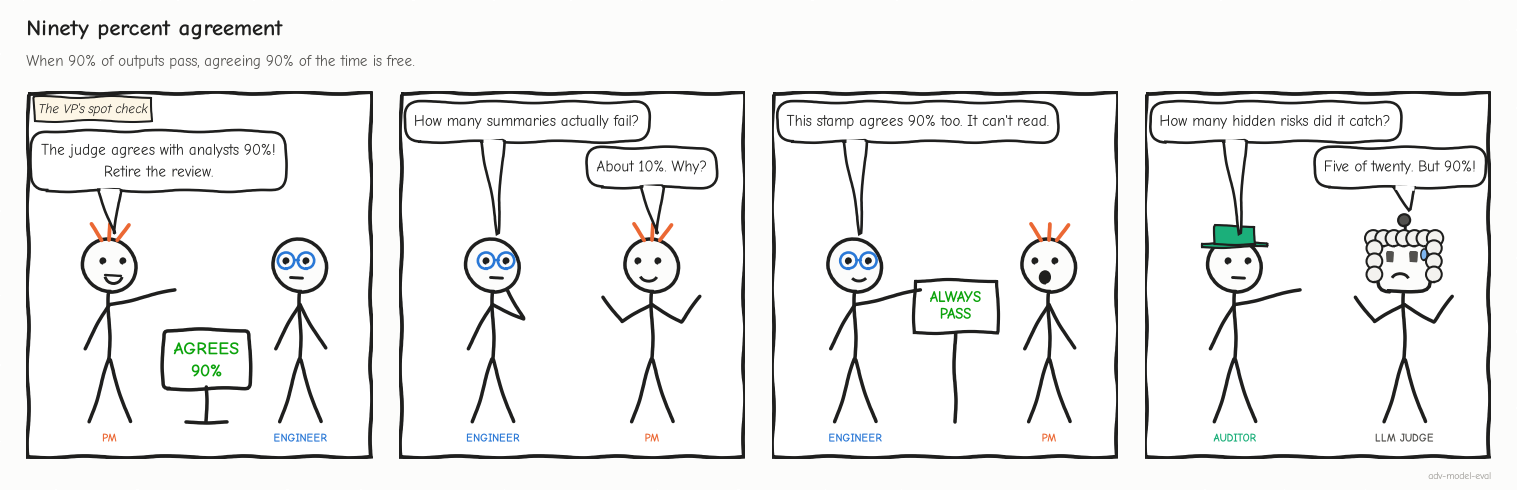

**Where the 90% comes from.** Both raters say PASS almost always, so by luck alone they'd agree **85.9%** of the time. κ asks how much of the remaining 14.1 points the judge *earned*: 4.2 of them, so κ = 4.2 / 14.1 = **0.30**.

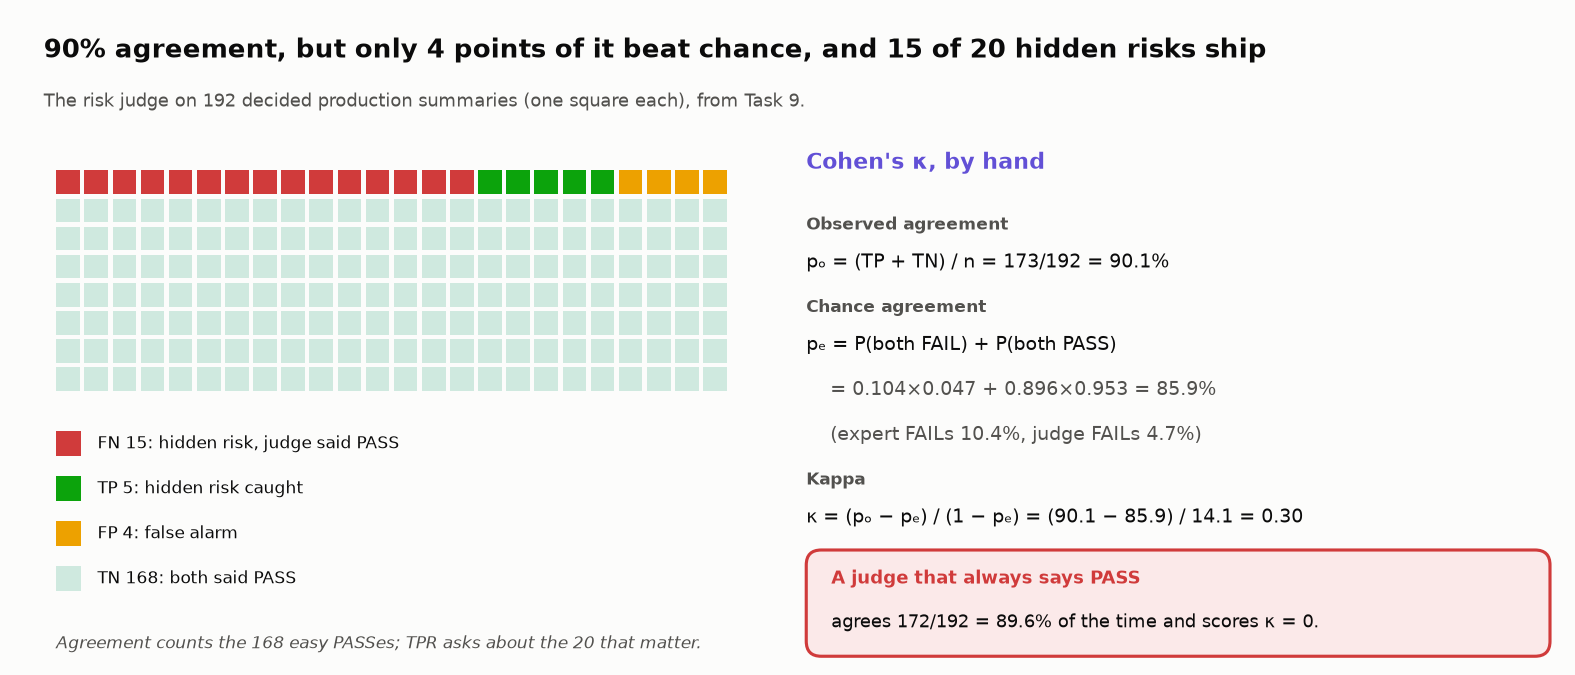

<sub>🖼️ *Agreement is mostly the 168 easy PASSes. TPR asks only about the 20 that matter.*</sub>

The **95% confidence interval** (the range of true rates consistent with what you observed) says more: with only 20 FAIL labels, the true TPR could be anywhere from about 11% to 47%. That's why the Husain/Shankar FAQ asks for 30–50 FAILs per split, and why Lab 05b spends a whole lab on the statistics.

🗣️ **Say it to a colleague:** "90% agreement is what a rubber stamp gets when 90% of outputs are fine. Ask what share of the failures it caught."

⏱️ **60-second experiment:** in `judge_scorecard`, score UNKNOWN as PASS instead of excluding it (`if j != "UNKNOWN"` → drop the filter and map UNKNOWN to PASS) and re-run. `n` becomes 200, agreement ticks up to 90.5%, TPR stays 25%. Nothing about the judge changed, only the abstention policy; all 8 abstentions were expert PASSes this time. Now imagine they were FAILs.

### 🎛️ Try it: the VP's dashboard

Next quarter the summarizer improves, so **fewer summaries hide a risk**. The judge doesn't change (TPR 25%, TNR 97.7%), and the VP re-runs the spot check. **Drag `risky / 1,000` left** and watch the VP's number; then **drag `judge TPR` up** to see what a fixed judge would look like.

> 🔮 **Predict:** At 20 risky summaries per 1,000, which scores higher agreement with the expert: **A** this judge · **B** a rubber stamp that always says PASS · **C** a tie within a point?


In [ ]:
# 🎛️ THE VP'S DASHBOARD: same judge, different data. The arithmetic behind every slider position:

JUDGE_TNR = float(card.loc["risks_disclosed", "tnr"])          # the risk judge's measured TNR (97.7%)
JUDGE_TPR = float(card.loc["risks_disclosed", "tpr"])          # ... and TPR (25%)
SAMPLE_RATE = (card.loc["risks_disclosed", "tp"] + card.loc["risks_disclosed", "fn"]) / card.loc["risks_disclosed", "n"]


def expected_scores(rate, tpr, tnr=JUDGE_TNR):
    """What a judge with this TPR/TNR scores when `rate` of summaries truly FAIL (expected values, no noise)."""
    tp, fn, fp, tn = rate * tpr, rate * (1 - tpr), (1 - rate) * (1 - tnr), (1 - rate) * tnr
    p_o = tp + tn                                     # raw agreement
    q = tp + fp                                       # how often the judge says FAIL
    p_e = rate * q + (1 - rate) * (1 - q)             # 👀 Look at: chance agreement moves with the failure rate
    return {"agreement": p_o, "always_pass": 1 - rate, "kappa": (p_o - p_e) / (1 - p_e), "tpr": tpr,
            "shipped_per_1000": 1000 * fn, "fails_per_1000": 1000 * rate}


In [ ]:
# @title 🧰 Dashboard drawing + the two sliders (risky / 1,000 and judge TPR) (hidden · 78 lines · drag the sliders below)
import io
from IPython.display import Image as _Img, display


def draw_dashboard(per_1000=round(1000 * SAMPLE_RATE), tpr=JUDGE_TPR):
    rate = per_1000 / 1000
    s = expected_scores(rate, tpr)
    xs = np.geomspace(0.005, 0.5, 120)
    curves = [expected_scores(x, tpr) for x in xs]
    fig = plt.figure(figsize=(10, 5.2))
    # ── tile row, drawn inside the figure so one image updates as a unit ──
    tiles_ = [("Raw agreement", f"{s['agreement']:.1%}", STATUS["good"] if s["agreement"] >= 0.9 else STATUS["warning"],
               "the VP's number"),
              ("Always-PASS stamp", f"{s['always_pass']:.1%}", "#b9b8b3", "reads nothing"),
              ("Cohen's κ", f"{s['kappa']:.2f}", STATUS["good"] if s["kappa"] >= 0.7 else STATUS["critical"], "bar: 0.70"),
              ("Hidden risks shipped", f"{s['shipped_per_1000']:.0f} / 1,000", STATUS["critical"] if s["shipped_per_1000"] >= 1 else STATUS["good"],
               f"of {s['fails_per_1000']:.0f} that hide a risk")]
    for k, (lab, val, col, note) in enumerate(tiles_):
        ax_t = fig.add_axes([0.02 + k * 0.245, 0.765, 0.225, 0.15]); ax_t.axis("off")
        ax_t.add_patch(plt.Rectangle((0, 0), 1, 1, fc="#fcfcfb", ec="#e4e3df", transform=ax_t.transAxes))
        ax_t.add_patch(plt.Rectangle((0, 0.9), 1, 0.1, fc=col, ec="none", transform=ax_t.transAxes))
        ax_t.text(0.06, 0.72, lab, fontsize=9, color="#52514e", transform=ax_t.transAxes)
        ax_t.text(0.06, 0.32, val, fontsize=17, weight="bold", color="#0b0b0b", transform=ax_t.transAxes)
        ax_t.text(0.06, 0.08, note, fontsize=8, color="#52514e", transform=ax_t.transAxes)
    ax = fig.add_axes([0.07, 0.11, 0.71, 0.58])
    agree = np.array([c["agreement"] for c in curves]); stamp = np.array([c["always_pass"] for c in curves])
    ax.fill_between(xs, 0, 1.08, where=stamp > agree, color=STATUS["critical"], alpha=0.07, lw=0)
    if (stamp > agree).any():
        ax.text(xs[stamp > agree][0] * 1.1, 0.04, "shaded: the stamp out-agrees the judge", fontsize=8.5,
                color=STATUS["critical"], zorder=5, bbox=dict(fc="#fcfcfb", ec="none", alpha=0.9, pad=1.5))
    ends = []
    for key, lab, col, ls in [("agreement", "raw agreement", PALETTE[0], "-"), ("always_pass", "always-PASS stamp", "#0b0b0b", ":"),
                              ("kappa", "Cohen's κ", PALETTE[6], "-"), ("tpr", "TPR (risks caught)", PALETTE[1], "--")]:
        ys = [c[key] for c in curves]
        ax.plot(xs, ys, color=col, ls=ls, lw=2)
        ends.append([ys[-1], lab, col])
    ends.sort(key=lambda e: e[0])
    for k in range(1, len(ends)):                      # nudge end labels apart so they never collide
        ends[k][0] = max(ends[k][0], ends[k - 1][0] + 0.075)
    for y, lab, col in ends:
        ax.text(0.53, y, lab, color=col, fontsize=9, va="center", clip_on=False)
    ax.axvline(rate, color="#0b0b0b", lw=1.2)
    ax.plot([rate] * 2, [s["agreement"], s["always_pass"]], "o", color="#0b0b0b", ms=4)
    ax.axvline(SAMPLE_RATE, color="#b9b8b3", lw=1, ls="--")
    ax.text(SAMPLE_RATE * 1.04, 1.035, "Task 9 sample", fontsize=8, color="#52514e")
    ax.set_xscale("log"); ax.set_xlim(0.005, 0.5); ax.set_ylim(0, 1.08)
    ax.set_xticks([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]); ax.set_xticklabels(["0.5%", "1%", "2%", "5%", "10%", "20%", "50%"])
    ax.set_xlabel("share of summaries that truly hide a risk (log scale)")
    if s["always_pass"] > s["agreement"]:
        title = (f"At {s['fails_per_1000']:.0f} risky per 1,000, a stamp that reads nothing out-agrees the judge "
                 f"({s['always_pass']:.0%} vs {s['agreement']:.0%})")
    else:
        title = (f"{s['fails_per_1000']:.0f} risky per 1,000: agreement {s['agreement']:.0%}, "
                 f"yet {s['shipped_per_1000']:.0f} of them ship")
    fig.suptitle(title, x=0.02, y=0.985, ha="left", fontsize=12.5, weight="bold")
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=100); plt.close(fig)
    return _Img(buf.getvalue())


_dash = display(draw_dashboard(), display_id=True)          # static view at the measured point (Run All shows this)
try:
    import ipywidgets as W
    _rate = W.IntSlider(value=round(1000 * SAMPLE_RATE), min=5, max=500, step=1, description="risky / 1,000",
                        continuous_update=False, style={"description_width": "initial"})
    _tpr = W.FloatSlider(value=round(JUDGE_TPR, 2), min=0.05, max=1.0, step=0.05, description="judge TPR",
                         continuous_update=False, style={"description_width": "initial"})
    _redraw = lambda change=None: _dash.update(draw_dashboard(_rate.value, _tpr.value))
    _rate.observe(_redraw, names="value"); _tpr.observe(_redraw, names="value")
    display(W.HBox([_rate, _tpr]))
except ImportError:
    print("(ipywidgets not available: showing the static view; call draw_dashboard(per_1000, tpr) to explore)")

crossover = (1 - JUDGE_TNR) / (JUDGE_TPR + 1 - JUDGE_TNR)   # where TP gains = FP losses: FPR / (TPR + FPR)
print(f"Below {crossover:.1%} risky, the always-PASS stamp out-agrees this judge.")
for r in (0.01, SAMPLE_RATE, 0.4):
    e = expected_scores(r, JUDGE_TPR)
    print(f"{r:5.1%} risky → agreement {e['agreement']:.1%} · always-PASS {e['always_pass']:.1%} · κ {e['kappa']:.2f} · TPR {e['tpr']:.0%}")


### Expected Output (static view at the Task 9 point)
A four-tile dashboard and a chart titled **"104 risky per 1,000: agreement 90%, yet 78 of them ship"**, then:
```
Below 8.5% risky, the always-PASS stamp out-agrees this judge.
 1.0% risky → agreement 96.9% · always-PASS 99.0% · κ 0.13 · TPR 25%
10.4% risky → agreement 90.1% · always-PASS 89.6% · κ 0.30 · TPR 25%
40.0% risky → agreement 68.6% · always-PASS 60.0% · κ 0.26 · TPR 25%
```

### 🔍 What the dashboard shows
- 🤯 **A better summarizer makes this judge look better.** Fewer risky summaries push its agreement from 90% toward 97%, while it still catches 1 risk in 4.
- **Below 8.5% risky, the rubber stamp beats the judge** (the shaded zone). Each false alarm costs agreement; each catch earns it. The crossover is FPR / (TPR + FPR) = 2.3% / (25% + 2.3%) = 8.5%, where FPR = 1 − TNR. The VP's spot check sat just above it.
- **κ moves with the data too:** the same judge scores 0.30 at 10% risky and 0.13 at 1%. TPR and TNR belong to the judge; agreement and κ belong to the judge *and the data*. **To compare judges across datasets or quarters, compare TPR and TNR.**

---

Agreement and κ tell you *that* the judge is unreliable, not *why*. That's the next task.


---

## Task 10: Read the Judge's Misses — Error Analysis on the Evaluator 🔎

A judge that misses 15 of 20 hidden risks is useless as a number and fixable as a pattern; the difference is whether anyone reads the misses.

### Goal
The *why* behind the misses: **slice** the judge's disagreements with the expert (group them by an input feature) and find the pattern.

### Why
The habit you used on the generator in Module 02 applies to the judge: read the failures, group them, name the pattern. Disagreements are the most informative rows you have, not noise to average away.

🏦 **In your world:** slice a judge's misses by form type, filing status, language or document length; a blind spot usually lives in one slice.

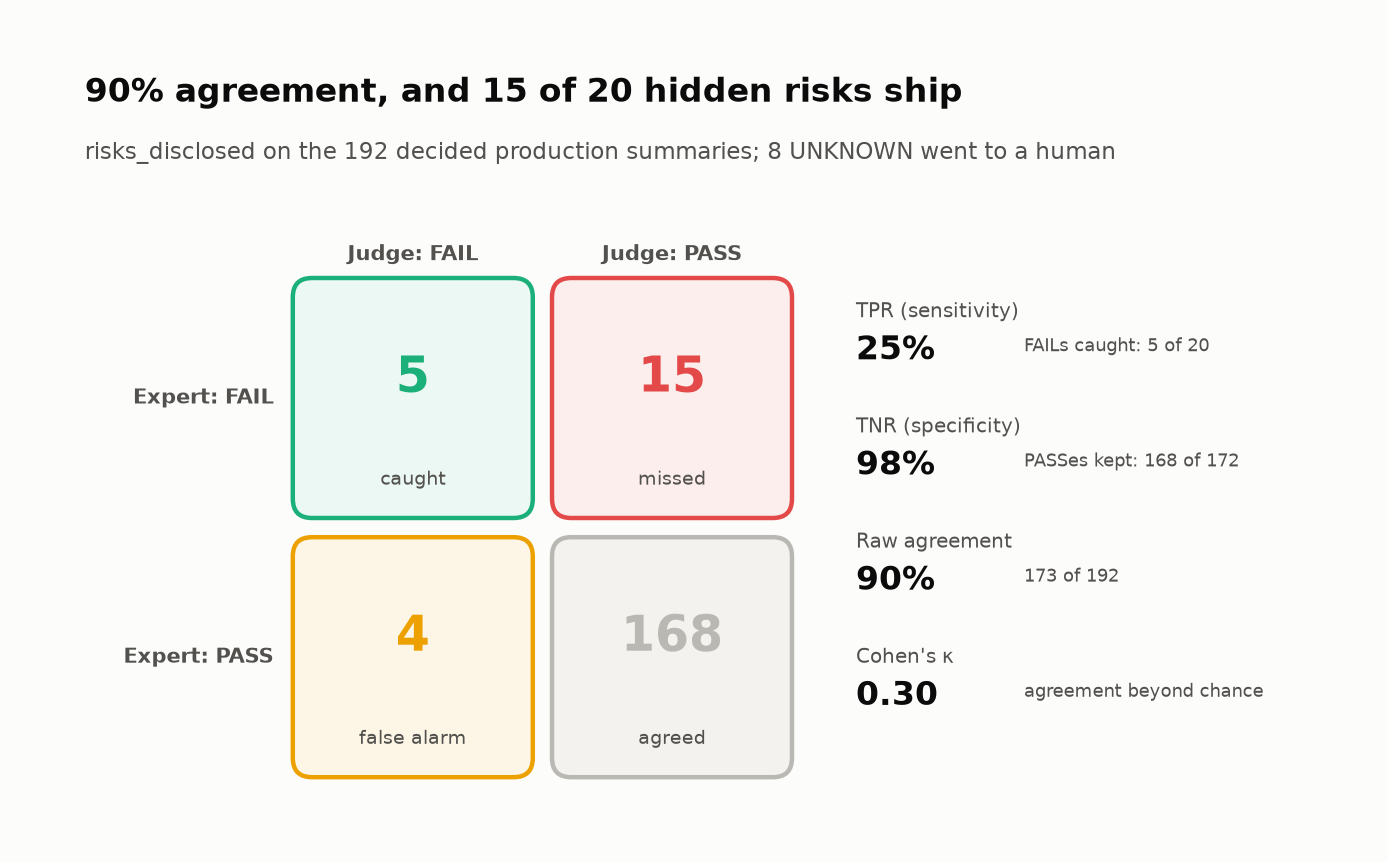
<sub>🖼️ *The 168 easy PASSes carry the agreement. The 15 in red are the rows this task slices.*</sub>

> 🔮 **Predict:** The risk judge's 15 misses are **A** spread evenly across omission types · **B** concentrated in one type. The framing judge's misses are **A** spread evenly across formats · **B** concentrated in one format.

### Steps
1. Run the slicing cell (misses by omission type and by format), then the collapsed card cell.
2. Read the three example misses, including each one's source.
3. Open the collapsed 🤖 simulated-judge cell in Task 9 and confirm the blind spots you found.

In [ ]:
# ──────────────────────────────────────────────────────────────
# ERROR ANALYSIS OF THE JUDGE: slice disagreements by input features
# ──────────────────────────────────────────────────────────────
v = val_df.assign(omission=[it["meta"]["omission"] for it in production_sample],
                  fmt=["markdown" if it["meta"]["markdown"] else "prose" for it in production_sample])


def catch_table(rows, by, mode):
    g = rows.groupby(by)                      # 👀 Look at: one input feature per slice
    return pd.DataFrame({"expert FAIL": g.size(),
                         "judge caught": g[f"judge_{mode}"].apply(lambda s: int((s == "FAIL").sum()))})


risk_tab = catch_table(v[v["human_risks_disclosed"] == "FAIL"], "omission", "risks_disclosed")
frame_tab = catch_table(v[v["human_balanced_framing"] == "FAIL"], "fmt", "balanced_framing")
print("risks_disclosed: hidden risks by kind of omission\n", risk_tab.to_string(), "\n")
print("balanced_framing: spin by format\n", frame_tab.to_string(), "\n")

print("Three missed hidden risks (expert FAIL, judge PASS):")
missed = [it for it in production_sample
          if it["human"]["risks_disclosed"] == "FAIL" and simulated_judge(it, "risks_disclosed")[0] == "PASS"]
for it in missed[:3]:
    print(f"\n  {it['id']} · source events: {it['source']['notable_events']}")
    print(f"     summary: {it['summary'][:150]}...")
    print(f"     judge critique: {simulated_judge(it, 'risks_disclosed')[1]}")


In [ ]:
# @title 🧰 Card: the misses aren't random (hidden · 15 lines · expand if curious)
h_n, h_c = risk_tab.loc["headline"]
e_n, e_c = risk_tab.loc["event"]
md_n, md_c = frame_tab.loc["markdown"]
pr_n, pr_c = frame_tab.loc["prose"]
insight(
    f"The misses aren't random: the risk judge caught {h_c} of {h_n} headline omissions but only {e_c} of {e_n} "
    f"omitted risk events",
    "In every miss above, the omitted event sits at the **end** of the source's events list, and the judge reads "
    "only the first event closely. The framing judge has a different blind spot: it caught "
    f"**{pr_c} of {pr_n}** spin summaries written as prose but only **{md_c} of {md_n}** formatted as markdown "
    "bullets.\n**Rule of thumb: when a judge disagrees with humans, slice the misses by input features (position, "
    "format, length, type) before you touch the prompt. The fix is usually specific: e.g. 'first list every event "
    "in the source, then check each one'.**",
)


### Checkpoint ✅
Two small tables, three example misses and one card.

### Expected Output (partial)
```
risks_disclosed: hidden risks by kind of omission
           expert FAIL  judge caught
omission
event              16             1
headline            4             4

balanced_framing: spin by format
           expert FAIL  judge caught
fmt
markdown            8             2
prose              16            15
```
In each printed miss, the omitted risk event is the **last** item in `source events`.

### 🔍 What Just Happened?
"κ = 0.30" became two specific, fixable blind spots: the risk judge **skims past events at the end of the list**, and the framing judge **goes easy on markdown**. Open the collapsed 🤖 cell in Task 9: both are written there in plain Python. With a real judge you can't read its code; slicing its errors is how you find them.

🗣️ **Say it to a colleague:** "κ tells you the judge is unreliable; slicing the misses tells you where. The fix is usually one sentence in the prompt, and then you re-validate."

### ✍️ Your Judge-Error Analysis

**Write your analysis here** (double-click to edit this cell):

1. **Which blind spot is most dangerous for a portfolio manager, and why?**

   *Your answer...*

2. **How would you change the `risks_disclosed` prompt or input to fix it?** (Hint: what if the judge had to enumerate every event before deciding?)

   *Your answer...*

3. **Look at the judge's false alarms.** Find the summaries that disclose leverage only as "a watch item". Is the judge wrong, or is the rubric ambiguous? Who should decide?

   *Your answer...*

4. **Would you let this judge gate `numbers_correct` on its own today?** Use its TPR, TNR and κ, and remember the deterministic check from Task 6.

   *Your answer...*

---

The framing judge's blind spot raises a sharper question: does **formatting** itself sway judges? Test it directly.

---

## Task 11: Probe the Judge for Bias — Position, Verbosity, Formatting 🧲

A judge that can be swayed by bullet points can be gamed by the summarizer; these probes take minutes and would have caught Task 10's markdown blind spot before launch.

### Goal
Three **bias probes**: change something that should *not* matter, re-judge, and measure how far the judge moves.

> 📘 **Concept · Bias probe**
>
> **What it is:** change something that should not matter (answer order, length, formatting) between two outputs with identical facts, re-judge, and measure the shift from the fair 50%.
>
> **What it can't tell you:** whether the judge is *accurate*. An unbiased judge can still miss failures; that was Task 9's job.
>
> **Anchor:** if bold bullets win 80% of pairs against the same words in prose, the judge is grading style. Strip the formatting and the probe should come back near 50%.

### How a bias probe works
The probes use **pairwise** judging (the judge sees two summaries and picks the better one), which is where position bias is defined. Both summaries contain **identical facts**, so a fair judge picks each side 50% of the time; any shift from 50%, measured in percentage points (pp), is bias.

| Probe | What changes | A fair judge would… |
|---|---|---|
| **Position** | Which summary comes first | …pick the first slot 50% of the time |
| **Verbosity** | Two sentences of generic fluff added to one side | …ignore the padding |
| **Formatting** (the literature's *style bias*) | One side rewritten as markdown bullets with **bold** labels, same words | …ignore the styling |
| **Mitigation** | Markdown stripped back to plain text before judging | …be back near 50% |

The probes run on **three simulated judges** (L, C, N) whose bias *directions* mirror 2026 measurements on real models (research card below). The numbers are simulated; the method is what you'd run on a real judge.

🏦 **In your world:** a bulleted, bolded tax explanation looks authoritative to a judge too. Normalize formatting before judging customer-facing answers.

> 🔮 **Predict:** Which moves a judge most: **A** swapping the order of two answers · **B** turning one into bullet points with bold labels · **C** padding one with two sentences of fluff? And does fluff help or hurt: **A** helps every judge · **B** hurts every judge · **C** depends on the judge?

### Steps
1. Run the collapsed judges cell, then the probe cell (≈ 3 × 4 × 850 simulated judgments; a few seconds).
2. Run the collapsed chart cell; read the chart, then the two cards.

In [ ]:
# @title 🧰 Three simulated pairwise judges (L, C, N) + the markdown / strip_markdown helpers (hidden · 41 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# BIAS PROBES: change something that should NOT matter, re-judge, measure the shift.
# Pairwise setup: the judge sees two summaries with IDENTICAL facts and picks the better one.
# A fair judge picks each side 50% of the time, so any shift away from 50% is bias.
# Three simulated judges whose bias directions mirror the 2026 literature (see the research card).
# ──────────────────────────────────────────────────────────────
FLUFF = (" Investors should weigh these results in the context of broader market conditions."
         " As always, past performance is not a guarantee of future results.")


def to_markdown(prose):
    """Same facts, dressed up: '### header' + bold bullet points."""
    head, *facts = [s for s in prose.split(". ") if s]
    bullets = [f"- **{f.split(':', 1)[0]}:** {f.split(':', 1)[1].strip().rstrip('.')}" for f in facts if ":" in f]
    return f"### {head.strip()}\n" + "\n".join(bullets)


def strip_markdown(text):
    """The mitigation: normalize formatting before the judge sees it."""
    text = re.sub(r"^###\s*(.+)$", r"\1.", text, flags=re.M)
    text = re.sub(r"^- \*\*(.+?):\*\*\s*(.+)$", r"\1: \2.", text, flags=re.M)
    return " ".join(text.split("\n"))


JUDGE_PROFILES = {  # log-odds nudges toward: the first slot, markdown, and extra length
    "Judge L": {"position": 0.08, "markdown": 1.5, "verbosity": 1.1},   # prefers longer answers
    "Judge C": {"position": 0.08, "markdown": 1.5, "verbosity": -0.5},  # prefers concise answers
    "Judge N": {"position": 0.08, "markdown": 1.5, "verbosity": -0.15}, # roughly length-neutral
}


def pairwise_judge(first, second, profile, rep=0):
    """Return 'first' or 'second'. Content is identical, so only bias + noise decide.
    `rep` = which repeat call this is (judges are stochastic, so we ask each question several times)."""
    p = JUDGE_PROFILES[profile]
    is_md = lambda t: t.lstrip().startswith("###")
    z = p["position"] + p["markdown"] * (is_md(first) - is_md(second))
    z += p["verbosity"] * np.tanh((len(first.split()) - len(second.split())) / 20)
    u = int(hashlib.md5(f"{profile}|{rep}|{first}|{second}".encode()).hexdigest(), 16) % 10_000 / 10_000
    return "first" if u < 1 / (1 + np.exp(-z)) else "second"


In [ ]:
# Run the four probes on three simulated judges. Each probe: same facts, one thing changed, re-judge.
REPEATS = 5


def preference_for(variant_fn, profile, items):
    """Share of judgments won by the variant, over BOTH orders (so position bias cancels)."""   # 👀 Look at: swap, then average
    wins = n = 0
    for it in items:
        base = it["summary"]
        var = variant_fn(base)
        for r in range(REPEATS):
            wins += pairwise_judge(var, base + " ", profile, r) == "first"
            wins += pairwise_judge(base + " ", var, profile, r) == "second"
            n += 2
    return wins / n


clean = [it for it in production_sample if not it["meta"]["markdown"] and set(it["human"].values()) == {"PASS"}]
probe_rows = []
for prof in JUDGE_PROFILES:
    first_wins = np.mean([pairwise_judge(a, b, prof, r) == "first" for it in clean for r in range(REPEATS)
                          for a, b in [(it["summary"], it["summary"] + " "), (it["summary"] + " ", it["summary"])]])
    probe_rows.append({"judge": prof, "probe": "Position (swap order)", "shift_pp": (first_wins - 0.5) * 100})
    probe_rows.append({"judge": prof, "probe": "Verbosity (add fluff)",
                       "shift_pp": (preference_for(lambda t: t + FLUFF, prof, clean) - 0.5) * 100})
    probe_rows.append({"judge": prof, "probe": "Markdown (same words)",
                       "shift_pp": (preference_for(to_markdown, prof, clean) - 0.5) * 100})
    probe_rows.append({"judge": prof, "probe": "Markdown, normalized first",
                       "shift_pp": (preference_for(lambda t: strip_markdown(to_markdown(t)), prof, clean) - 0.5) * 100})
probes = pd.DataFrame(probe_rows)
print(f"Probed 3 judges on {len(clean)} clean summaries ({2 * REPEATS * len(clean)} judgments per probe per judge).\n")
print(probes.pivot(index="probe", columns="judge", values="shift_pp").round(1).to_string())


In [ ]:
# @title 🧰 Chart + cards: how far each probe moved each judge (hidden · 41 lines · expand if curious)
# ── One chart: how far each probe moved each judge ──
order = ["Position (swap order)", "Verbosity (add fluff)", "Markdown (same words)", "Markdown, normalized first"]
pivot = probes.pivot(index="probe", columns="judge", values="shift_pp").loc[order]
fig, ax = plt.subplots(figsize=(9.5, 3.9))
y, h = np.arange(len(order)), 0.26
for k, judge in enumerate(JUDGE_PROFILES):
    vals = pivot[judge].values
    ax.barh(y + (k - 1) * h, vals, h, color=PALETTE[k], label=judge)
    for yy, val in zip(y + (k - 1) * h, vals):
        ax.text(val + (0.8 if val >= 0 else -0.8), yy, f"{val:+.0f}", va="center",
                ha="left" if val >= 0 else "right", fontsize=8.5, color="#0b0b0b")
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlim(pivot.values.min() - 5, pivot.values.max() + 5)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("shift in preference vs a fair 50% (percentage points)")
md_shift = pivot.loc["Markdown (same words)"]; posn = pivot.loc["Position (swap order)"].abs()
ax.set_title(f"Markdown moved every judge {md_shift.min():.0f}–{md_shift.max():.0f} pp; swapping order moved them ≤ {posn.max():.0f} pp")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

verb = pivot.loc["Verbosity (add fluff)"]; norm = pivot.loc["Markdown, normalized first"].abs()
insight(
    f"Bullets and bold beat substance: every judge preferred the markdown copy by {md_shift.min():.0f}–{md_shift.max():.0f} pp",
    f"Same facts, different styling. Swapping answer order moved the judges at most {posn.max():.0f} pp, which is "
    f"within the noise of {2 * REPEATS * len(clean)} judgments. Verbosity isn't even consistent: fluff helped "
    f"Judge L ({verb['Judge L']:+.0f} pp) and hurt Judge C ({verb['Judge C']:+.0f} pp). Normalizing the formatting "
    f"before judging cut the markdown effect to {norm.max():.0f} pp or less. This is the mechanism behind Task 10's "
    "framing misses: spin in tidy bullets reads as 'professional'.\n"
    "**Rule of thumb: strip formatting before judging, and re-run these three probes every time you change the judge "
    "model or prompt. A bias's direction is a property of your judge, not of 'LLMs'.**",
)
insight(
    "In 2026 data, style bias dominates and position bias is nearly solved",
    "'Judging the Judges' (Soumik, TMLR 2026; judges incl. GPT-4o, Claude Sonnet 4, Gemini 2.5 Flash, Llama) found "
    "**style/markdown bias was the dominant bias, far exceeding position bias (≤ 0.04)**. Verbosity bias depended on "
    "the judge: Gemini and Llama preferred longer answers (+0.24 to +0.44), Claude Sonnet 4 preferred concise ones, "
    "and GPT-4o was about neutral. Self-preference (a judge favoring its own model family's output) is a separate "
    "risk: judge with a model from a *different family* than your generator, or use a panel (Stretch B).",
    kind="research",
)


### Checkpoint ✅
A 4 × 3 table of preference shifts, a bar chart and two cards.

### Expected Output
```
Probed 3 judges on 85 clean summaries (850 judgments per probe per judge).

judge                       Judge C  Judge L  Judge N
probe
Markdown (same words)          30.7     36.2     32.1
Markdown, normalized first      2.2     -2.2      0.2
Position (swap order)          -2.4      0.4      4.8
Verbosity (add fluff)         -10.8     17.9     -3.5
```
Chart title: **"Markdown moved every judge 31–36 pp; swapping order moved them ≤ 5 pp"**.

### 🔍 What Just Happened?
**Formatting dominated**: identical facts in bullets and bold won more than 80% of comparisons. **Position** barely registered. **Verbosity** pointed in different directions for different judges, so "LLMs prefer longer answers" is not a law. The mitigation is nearly free: normalize formatting before the judge sees the text.

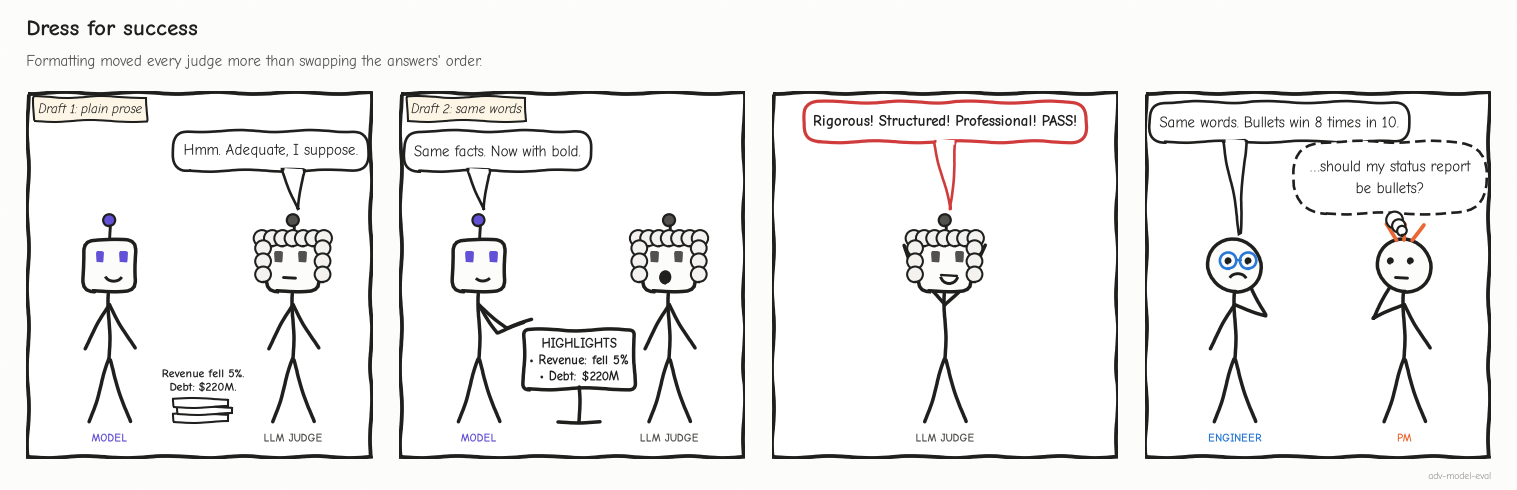

🗣️ **Say it to a colleague:** "Strip the formatting before judging. Bold bullets moved our judges 30 points; swapping the order moved them 5."

⏱️ **60-second experiment:** set `REPEATS = 1` and re-run the probe cell. The position shift swings between −6 and +9 pp while the markdown shift stays near 30: with fewer judgments, noise grows and bias doesn't. That is how you tell them apart on a real judge.

---

You have every piece of evidence. Decide.

---

🧭 **Where you are:** Act 4 of 4 (Task 12): the decision, with evidence.

## Task 12: Combine Everything and Make the Call 📋

The VP is waiting. A BLOCK without numbers is an opinion; a SHIP without them is a liability.

### Goal
One **BLOCK / HUMAN REVIEW / PASS** decision per summary with the layer that caught it, then the VP's question: **should the LLM judge become the only gate, with analyst review retired?**

### Why
Dimension scores are for diagnosis. A decision-maker needs one signal with a reason attached, and a ruling on *which checks can run without a human*.

🏦 **In your world:** this is the same call a tax or bookkeeping product makes before letting an AI answer go to a customer unreviewed (see the IRS card below).

### Decision rules
- ⛔ **BLOCK**: any deterministic gate fails (contradicted claim, critical omission, major numeric error), or the judge says FAIL on a **blocking** mode
- 🔎 **HUMAN REVIEW**: nothing blocks, but the judge said `UNKNOWN`, or FAIL on a tolerable mode (framing)
- ✅ **PASS**: everything passes. The **pass-all rate** counts only summaries that pass every check

> 🔮 **Predict:** If the judge were the *only* gate (no deterministic checks, no analysts), how many of the six would ship: **A** 1 · **B** 2 · **C** 3 or more? The expert's labels say **1** should.

### Steps
1. Run the combined report.
2. Run the decision cell and read the reasons.

In [ ]:
# ──────────────────────────────────────────────────────────────
# COMBINED REPORT: every layer, one decision per summary, and which layer caught what
# ──────────────────────────────────────────────────────────────
rows = []
for item in financial_dataset:
    sid = item["id"]
    fact = next(f for f in factuality_results if f["id"] == sid)       # Layer 1: claims
    comp = next(c for c in completeness_results if c["id"] == sid)     # Layer 2: completeness
    nums = next(n for n in numeric_results_all if n["id"] == sid)      # Layer 3: numeric
    jv = judge_verdicts[sid]                                           # Layer 4: binary judge
    layers = {
        "claims": "FAIL" if fact["contradicted"] + fact["fabricated"] > 0 else "PASS",
        "completeness": "FAIL" if comp["critical_missing"] else "PASS",
        "numeric": "FAIL" if any(c["severity"] in ("major_error", "fabricated") for c in nums["checks"]) else "PASS",
        "judge": ("FAIL" if any(jv[m].verdict == "FAIL" for m in BLOCKING)
                  else "UNKNOWN" if any(jv[m].verdict == "UNKNOWN" for m in MODES)
                  else "REVIEW" if any(jv[m].verdict == "FAIL" for m in MODES) else "PASS"),
    }
    if "FAIL" in layers.values():                                      # 👀 Look at: any blocking FAIL blocks; no averaging
        decision = "⛔ BLOCK"
    elif {"UNKNOWN", "REVIEW"} & set(layers.values()):
        decision = "🔎 HUMAN REVIEW"
    else:
        decision = "✅ PASS"
    reasons = [f"{k}" for k, val in layers.items() if val == "FAIL"]
    judge_only = all(jv[m].verdict == "PASS" for m in BLOCKING)
    rows.append({"company": item["company"], **{k: ICON.get(val, "🔎") for k, val in layers.items()},
                 "decision": decision, "caught by": ", ".join(reasons) or "-",
                 "judge-only gate": "ships" if judge_only else "held"})
report = pd.DataFrame(rows).set_index("company")
print(report.to_string())


In [ ]:
# The three numbers the VP will ask about.
n = len(report)
layered_pass = int((report["decision"] == "✅ PASS").sum())
judge_only_ships = report.index[report["judge-only gate"] == "ships"].tolist()
leaks = [c for c in judge_only_ships if report.loc[c, "decision"] != "✅ PASS"]
tiles([
    ("Pass-all rate (layered)", f"{layered_pass} of {n}", "n = 6: a sanity check, not a rate", "critical"),
    ("Judge-only gate ships", f"{len(judge_only_ships)} of {n}", ", ".join(judge_only_ships), "warning"),
    ("Leaks if judge-only", len(leaks), ", ".join(leaks) or "none", "critical" if leaks else "good"),
])


In [ ]:
# ──────────────────────────────────────────────────────────────
# THE DECISION: "Make the LLM judge the only gate and retire analyst review"?
# A blocking mode can run unattended only if its judge clears the bar on the production sample.
# ──────────────────────────────────────────────────────────────
KAPPA_BAR, TPR_BAR = 0.70, 0.80
ready = {m: bool(card.loc[m, "kappa"] >= KAPPA_BAR and card.loc[m, "tpr"] >= TPR_BAR) for m in BLOCKING}
automate = [m for m, ok in ready.items() if ok]
keep_human = [m for m, ok in ready.items() if not ok]
decision = "SHIP" if not keep_human and not leaks else "BLOCK"

rk = card.loc["risks_disclosed"]
reasons = [
    "Proposal under review: the LLM judge as the **only** gate, with analyst review retired.",
    f"`risks_disclosed` judge: **TPR {rk.tpr:.0%}, κ {rk.kappa:.2f}** on {int(rk.n)} expert-labeled summaries; "
    f"{int(rk.fn)} hidden risks would have shipped. The '90% agreement' is {rk.raw_agreement:.1%} vs "
    f"{rk.always_pass_agreement:.1%} for a judge that always says PASS.",
    f"On the curated six, a judge-only gate ships {', '.join(judge_only_ships)}. "
    + (f"{', '.join(leaks)} was caught only by a deterministic check. " if leaks else ""),
    f"Framing judge: caught {md_c} of {md_n} markdown-formatted spin summaries; the probes showed a "
    f"{md_shift.min():.0f}–{md_shift.max():.0f} pp preference for markdown.",
    f"Clears the bar today (κ ≥ {KAPPA_BAR}, TPR ≥ {TPR_BAR:.0%}): **{', '.join(automate) or 'none'}**. "
    f"Keep analysts on **{', '.join(keep_human) or 'none'}**, keep the deterministic numeric and completeness gates, "
    "and route every UNKNOWN to a human.",
    "Before re-proposing: fix the event-list blind spot, normalize formatting, collect 30–50 FAIL labels per split, "
    "and report the judge's pass rate *corrected for its own error, with a confidence interval* (Lab 05b).",
]
verdict(decision, reasons)
insight(
    "Regulators expect a human to verify AI output in finance and tax",
    "IRS Office of Professional Responsibility guidance (June 2026) tells practitioners to review AI output and "
    "validate its factual assertions: AI is 'a starting point, not a finished product'. In Moffatt v. Air Canada "
    "(2024), a tribunal held the airline responsible for what its chatbot said. For this "
    f"team: automate the checks your validation data supports ({', '.join(automate) or 'none yet'}), "
    f"keep humans where the judge is weak ({', '.join(keep_human) or 'none'}), and re-validate every quarter, "
    "because the summarizer, the judge model and the data all drift.",
    kind="production",
)

### Checkpoint ✅
The combined report, three tiles, a 🛑 **BLOCK** verdict with six reasons, and a production card.

### Expected Output (partial)
```
                  claims completeness numeric judge decision               caught by judge-only gate
company
TechFlow Inc.          ✅            ✅       ✅     ✅   ✅ PASS                       -           ships
GreenLeaf Energy       ✅            ⛔       ✅     ⛔  ⛔ BLOCK     completeness, judge            held
MedVault Health        ✅            ✅       ⛔     ⛔  ⛔ BLOCK          numeric, judge            held
UrbanLogix             ✅            ⛔       ✅     ⛔  ⛔ BLOCK     completeness, judge            held
NexaPay Financial      ⛔            ✅       ⛔     ⛔  ⛔ BLOCK  claims, numeric, judge            held
SkyBridge Telecom      ✅            ⛔       ✅     ✅  ⛔ BLOCK            completeness           ships
```
Tiles: **Pass-all rate 1 of 6 · Judge-only gate ships 2 of 6 · Leaks if judge-only: 1 (SkyBridge Telecom)**. Verdict: **🛑 BLOCK**; only `numbers_correct` clears the κ ≥ 0.7 and TPR ≥ 80% bar.

### 🔍 What Just Happened?
Each layer caught something another missed:

| Layer | Caught | Missed |
|---|---|---|
| Claims | NexaPay's 15 vs 12 countries | Both wrong growth rates; all omissions |
| Completeness | GreenLeaf, UrbanLogix, **SkyBridge** omissions | Wrong numbers |
| Numeric | MedVault and NexaPay errors | Omissions, framing |
| Binary judge | Framing, most omissions, numbers; UNKNOWN on the sector claim | **SkyBridge's debt**, and (Task 9) most event omissions at scale |

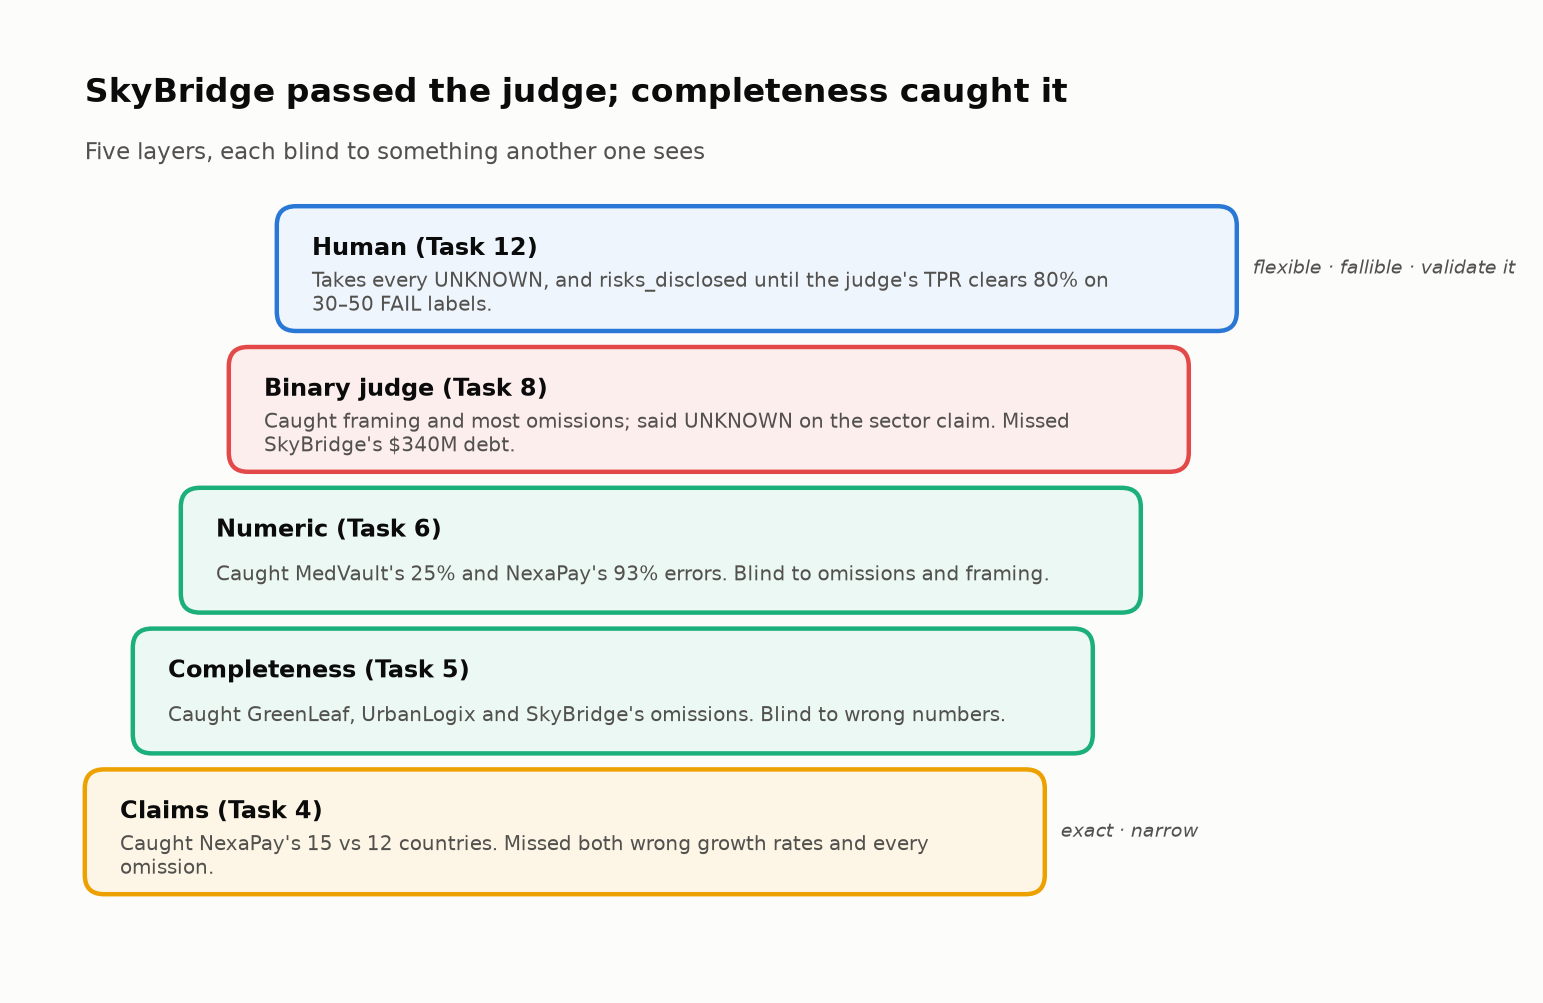
<sub>🖼️ *Defense in depth, applied to evaluators: the exact layers sit at the bottom, the flexible ones on top, and no single layer sees everything.*</sub>

The answer to the VP is not "LLM judges don't work". It's **automate the mode the data supports, keep humans and deterministic gates where the judge is weak, and come back with better evidence**: **defense in depth** (independent layers, so one layer's blind spot is another's catch), applied to evaluators.

🗣️ **Say it to a colleague:** "Automate the modes the labels support, keep humans and deterministic gates on the rest, and re-validate every quarter."

⏱️ **60-second experiment:** raise `TPR_BAR` to `0.90` and re-run the decision cell. Nothing clears (numbers_correct sits at 86.7%). Challenge 5 and Lab 05b ask the sharper question: what is the *lower bound* of that 86.7%?

---

## ✅ Validation and Success Criteria

You've completed this lab if:

- [ ] The 6 summaries and the 200-summary production sample load with expert labels per failure mode
- [ ] Factuality scoring flags NexaPay's contradicted country count, and you can explain why it marked two wrong growth rates *supported*
- [ ] Completeness scoring flags critical omissions in GreenLeaf, UrbanLogix and SkyBridge
- [ ] Numeric checks catch MedVault's and NexaPay's major errors, sized by **relative** error
- [ ] You wrote 4 binary checks with PASS / FAIL / UNKNOWN conditions (Task 7)
- [ ] The binary judge runs, and you can say in one sentence why it beats a 1–5 score with a ship threshold
- [ ] You computed **TPR, TNR and κ** per failure mode and can explain why 90% agreement coexists with κ ≈ 0.3
- [ ] On the 🎛️ dashboard you found where a rubber stamp out-agrees the judge, and can say why a better summarizer makes a bad judge look better
- [ ] You found the judge's two blind spots by slicing its misses (Task 10)
- [ ] You ran the three bias probes and can name the dominant bias and its mitigation
- [ ] You can defend the final SHIP / BLOCK verdict with numbers from your own run
- [ ] Challenges: at least one starter cell shows ✅ that didn't when you opened the lab

---

## 🔧 Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ModuleNotFoundError` | Package not installed | Run the install cell, restart the runtime |
| `NameError: insight` / `tiles` | Lab kit cell not run | Run the 🎨 Lab kit cell in Task 1 |
| `NameError` in Tasks 9–12 | A cell above was skipped | **Runtime → Run all**, or run from Task 2 down |
| Real judge: HTTP 400 mentioning `temperature` | Sampling parameters sent to a model that rejects them | Don't pass `temperature`/`top_p`/`top_k`; this lab's code never does |
| Real judge: model not found | Typo or retired model ID | Use the IDs in the Task 1 config cell (`gpt-6-luna`, `claude-haiku-5-5`) |
| Real judge: `AttributeError: ... has no attribute 'parse'` | Old SDK | `pip install -U openai anthropic` (needs `responses.parse` / `messages.parse`) |
| Real judge returns `UNKNOWN` with "refusal" | The model declined | Check `stop_reason`; count refusals as abstentions, never as PASS |
| κ prints `nan` | The judge (or the labels) used only one class on the decided items | Check the confusion counts; you need both PASS and FAIL labels |
| Your numbers differ from Expected Output | `PROVIDER` isn't `"mock"`, or you edited the data | Expected; reset `PROVIDER = "mock"` to reproduce the reference numbers |

---

## 🧩 Stretch Goals or Extensions

### Stretch A: Debug a flawed verifier
The factuality scorer (Task 4) marked MedVault's "25%" and NexaPay's "22%" **supported**.
1. **Root cause:** which part of each sentence earned the label? Rewrite `extract_claims` so each claim holds **one** checkable fact (split on em dashes and commas too, or extract `(metric, value)` pairs) and re-run Task 4. Are they caught now? (You may also need to fix how `_claim_references_metric` compares `25.0` with the text `25%`.)
2. **A false negative:** find a claim marked "unsupported" that the source data clearly verifies.
3. **A fix:** what would an LLM claim verifier (atomic facts, each checked against the source, SAFE-style) do differently, and how would you validate *it* with TPR and TNR?

### Stretch B: A panel of judges (PoLL) and cross-family judging
A **panel of judges** (PoLL, "panel of LLM evaluators") runs several judges on each case and aggregates their votes. Run the cell below: it adds two simulated judges "from other model families" with **different** blind spots, then compares a same-family panel (three samples of our judge) with a cross-family panel.

### Stretch C: Run a real judge
Set `PROVIDER = "openai"` or `"anthropic"` in Task 1, add your key, and re-run Task 8. Then set `VALIDATE_REAL_JUDGE = True` in Task 9 to validate the real judge on all 200 summaries × 4 modes (800 calls; at the $0.10 / $0.50 per 1M-token list prices of `gpt-6-luna` and `claude-haiku-5-5`, about ten cents at ~600 input and ~150 output tokens per call). Does a real model share the simulated judge's blind spots? Run the Task 11 probes against it too.

In [ ]:
# @title 🧰 Two simulated judges from other model families (B, C) + majority / any-FAIL aggregation (hidden · 44 lines · expand if curious)
# ──────────────────────────────────────────────────────────────
# STRETCH: a panel of judges (PoLL) on the weakest failure mode, risks_disclosed.
# Member A is our judge. B and C simulate judges from *other model families*, with
# different blind spots. A "same-family" panel is three samples of judge A.
# ──────────────────────────────────────────────────────────────
def judge_family_b(item):
    """Reads every event carefully, but skims the numbers (misses quarter-over-quarter declines)."""
    src, low = item["source"], item["summary"].lower()
    if src["notable_events"] is None:
        return "UNKNOWN"
    for key, event in _RISK_EVENTS.items():
        if event in src["notable_events"] and key not in low and not _coin(item["id"], "B", 0.45):
            return "FAIL"
    return "PASS"


def judge_family_c(item):
    """Checks headline numbers, and reads the LAST event closely (the opposite habit to judge A)."""
    src, low = item["source"], item["summary"].lower()
    if src["notable_events"] is None:
        return "UNKNOWN"
    if src["revenue_m"] < src["revenue_prev_quarter_m"] and "down" not in low:
        return "FAIL"
    last = src["notable_events"][-1]
    for key, event in _RISK_EVENTS.items():
        if last == event and key not in low and not _coin(item["id"], "C", 0.4):
            return "FAIL"
    return "PASS"


def majority(votes):
    votes = [v for v in votes if v != "UNKNOWN"]
    if not votes:
        return "UNKNOWN"
    return "FAIL" if votes.count("FAIL") > len(votes) / 2 else "PASS"


def any_fail(votes):
    """Recall-first rule for release-blocking modes: one FAIL vote sends it to a human."""
    votes = [v for v in votes if v != "UNKNOWN"]
    if not votes:
        return "UNKNOWN"
    return "FAIL" if "FAIL" in votes else "PASS"


In [ ]:
# Six configurations of judges on risks_disclosed, scored the same way as Task 9.
panels = {
    "Judge A alone": lambda it: simulated_judge(it, "risks_disclosed")[0],
    "Judge B alone": judge_family_b,
    "Judge C alone": judge_family_c,
    "Same-family panel (A×3)": lambda it: majority([simulated_judge(it, "risks_disclosed")[0]] * 3),
    "Cross-family panel, majority": lambda it: majority([simulated_judge(it, "risks_disclosed")[0],
                                                         judge_family_b(it), judge_family_c(it)]),
    "Cross-family panel, any-FAIL": lambda it: any_fail([simulated_judge(it, "risks_disclosed")[0],
                                                         judge_family_b(it), judge_family_c(it)]),
}
rows = []
for name, fn in panels.items():
    s = judge_scorecard([it["human"]["risks_disclosed"] for it in production_sample],
                        [fn(it) for it in production_sample])
    rows.append({"judge": name, "TPR": s["tpr"], "TNR": s["tnr"], "kappa": s["kappa"]})
panel_df = pd.DataFrame(rows).set_index("judge")
print(panel_df.round(2).to_string())


In [ ]:
# @title 🧰 Cards: same-family vs cross-family panels (hidden · 23 lines · expand if curious)
a, same = panel_df.loc["Judge A alone"], panel_df.loc["Same-family panel (A×3)"]
maj, anyf = panel_df.loc["Cross-family panel, majority"], panel_df.loc["Cross-family panel, any-FAIL"]
insight(
    f"Three copies of the same judge add nothing (κ {same.kappa:.2f} = {a.kappa:.2f}); a cross-family panel lifts TPR "
    f"from {a.TPR:.0%} to {anyf.TPR:.0%}",
    f"A same-family panel shares one blind spot, so voting can't fix it. Judges from other families fail on "
    f"*different* summaries: with an any-FAIL rule (one FAIL vote sends the summary to a human) the panel reaches "
    f"TPR {anyf.TPR:.0%} at TNR {anyf.TNR:.0%} (κ {anyf.kappa:.2f}). Simple majority only reaches TPR {maj.TPR:.0%}, "
    "because one member is blind to most of these failures.\n"
    "**Rule of thumb: panels help when members fail differently, and you only learn that by validating each "
    "member. For release-blocking modes, prefer recall-first aggregation.**",
)
insight(
    "Panels of small judges vs one big judge",
    "PoLL (Verga et al., Cohere, 2024): a panel of three smaller judges from different model families outperformed a "
    "single GPT-4 judge across three settings and six datasets, at over 7× lower cost, and voting reduced "
    "self-preference bias. The panel's specific models are outdated now, and we found no independent replication. "
    "On using the generator as its own judge, sources conflict: a 2024 survey advises against it, while the "
    "Husain/Shankar FAQ (2026) calls the same model 'usually fine' *if* it's validated against human labels. "
    "Your TPR/TNR on your data settles it.",
    kind="research",
)


### 🏆 Challenge exercises

Five problems that need thinking, not typing. Each starter cell runs as shipped and prints ✅/❌; worked solutions are in the instructor guide.

#### 🌶️ Challenge 1: The lie leaderboard (🏦 small-business variant)
A scorer that gives full marks to a summary denying an unpaid tax bill will send that summary to the owner, and the dashboard will say everything is fine.

An AI bookkeeping assistant writes the quarterly summary for the owner of **Maple & Rye Bakery** (fictional). The truth: revenue fell, the lender waived a line-of-credit covenant, the Q3 estimated tax payment is unpaid, and a contractor needs a 1099-NEC (the IRS form for reporting payments to independent contractors).

The leaderboard ranks summaries the way an automated pipeline would: the Task 5 completeness score and the Task 4 factuality score, averaged. A last column shows what a careful human reader sees.

1. **Write a summary that lies to the owner and still ties the honest summary for 🥇.** Add it to `MY_LIES` or type it in the box under the board.
2. In one sentence: what property do both scorers lack, and what would a production verifier need instead?

<details><summary>💡 Hint</summary>

The completeness scorer counts a fact as covered when half its words appear *anywhere*. The claim verifier supports any claim that shares three words with a notable event. Neither one reads "no". Also look at where the fudged revenue ranks against the AI's honest-but-incomplete draft.
</details>


In [ ]:
# @title 🧰 Challenge 1 kit: the bakery's books, three seeded entries, the two scorers and the leaderboard (hidden · 106 lines · expand if curious)
# The bakery's books, the three seeded entries, the two scorers, the leaderboard and its text box.
import html as _h
from IPython.display import HTML, display

BAKERY = {
    "source_data": {"revenue": 186_000, "revenue_prev_quarter": 204_000, "net_income": 9_000,
                    "cash_on_hand": 21_000, "total_debt": 140_000,
                    "notable_events": ["Lender granted a covenant waiver on the line of credit",
                                       "Q3 estimated tax payment of $6,400 is unpaid",
                                       "Paid a contractor $3,200 who needs a 1099-NEC"]},
    "key_facts": ["Revenue of $186,000", "Revenue declined quarter-over-quarter", "Net income of $9,000",
                  "Cash on hand of $21,000", "Total debt of $140,000", "Line of credit covenant waiver",
                  "Estimated tax payment unpaid", "Contractor needs a 1099-NEC"],
    "numeric_claims": {m: {"stated": v, "actual": v} for m, v in
                       [("revenue", 186_000), ("net_income", 9_000), ("cash_on_hand", 21_000), ("total_debt", 140_000)]},
}
TRUE_AMOUNTS = {186_000, 204_000, 9_000, 21_000, 140_000, 6_400, 3_200}
RISKS = {"the covenant waiver": r"waiver", "the unpaid estimated tax": r"estimated tax", "the 1099-NEC": r"1099",
         "the revenue decline": r"declin|fell|\bdown\b|drop"}
NEGATION = r"\b(no|not|never|without|none)\b|n't\b"

SEEDED_ENTRIES = [
    ("🤖 The AI's draft", "Maple & Rye Bakery had a solid Q3 2026 with revenue of $186,000 and net income of $9,000. "
                         "Cash on hand is $21,000. Holiday demand looks strong."),
    ("📒 Honest summary", "Revenue fell to $186,000 from $204,000 last quarter, a 9% decline. Net income was $9,000. "
                         "Cash on hand is $21,000 against total debt of $140,000, and the lender granted a covenant "
                         "waiver on the line of credit. To do: the Q3 estimated tax payment of $6,400 is unpaid, and "
                         "the contractor you paid $3,200 needs a 1099-NEC."),
    ("✏️ Fudged revenue", "Revenue grew to $214,000 this quarter. Net income was $9,000 and cash on hand is $21,000. "
                         "Total debt is $140,000."),
]
SEEDED = len(SEEDED_ENTRIES)
ENTRIES = list(SEEDED_ENTRIES)


def scorer_view(text):
    """What the automated scorers see: Task 5 completeness and the Task 4 factuality score."""
    b = BAKERY
    comp = score_completeness(text, b["key_facts"], b["source_data"])["overall_score"]
    labels = [verify_claim_against_source(c, b["source_data"], b["numeric_claims"])[0] for c in extract_claims(text)]
    fact = (labels.count("supported") - 2 * labels.count("contradicted")) / max(len(labels), 1)
    return comp, fact, (comp + fact) / 2


def reader_view(text):
    """What a careful human reader sees: denials, invented amounts, omissions."""
    clauses = re.split(r"[.;:!?]", text)
    issues = [f"denies {r}" for r, kw in RISKS.items()
              if any(re.search(kw, c, re.I) and re.search(NEGATION, c, re.I) for c in clauses)]
    amounts = {int(x.replace(",", "")) for x in re.findall(r"\$(\d[\d,]{3,})", text)}
    issues += [f"invents ${a:,}" for a in sorted(amounts - TRUE_AMOUNTS)]
    issues += [f"omits {r}" for r, kw in RISKS.items() if not re.search(kw, text, re.I)]
    return issues


def board_html():
    rows = sorted(((scorer_view(t), reader_view(t), n) for n, t in ENTRIES), key=lambda r: -r[0][2])
    top = rows[0][0][2]
    html_rows = []
    for (comp, fact, score), issues, name in rows:
        lie = any(i.startswith(("denies", "invents")) for i in issues)
        rank = "🥇" if score == top else ""
        tint = "#fbe9e9" if lie and score >= 0.9 else "#ffffff"
        truth = "✅ accurate and complete" if not issues else ("🤥 " if lie else "⚠️ ") + "; ".join(issues)
        td = "<td style='border-bottom:1px solid #e4e3df;padding:7px 9px;text-align:left;vertical-align:top'>"
        html_rows.append(f"<tr style='background:{tint}'>{td}{rank}</td>{td}<b style='white-space:nowrap'>"
                         f"{_h.escape(name)}</b></td>{td}{comp:.2f}</td>{td}{fact:.2f}</td>{td}<b>{score:.2f}</b></td>"
                         f"{td}{_h.escape(truth)}</td></tr>")
    th = "<th style='padding:7px 9px;text-align:left;color:#52514e;font-weight:600'>"
    head = (f"<tr style='background:#f3f2ef'>{th}</th>{th}Entry</th>{th}Completeness</th>{th}Factuality</th>"
            f"{th}Scorer score</th>{th}What a careful reader sees</th></tr>")
    return ("<div style='font:600 15px system-ui;margin:6px 0'>🏆 Lie leaderboard: ranked by the automated scorers</div>"
            "<table style='border-collapse:collapse;font:13px system-ui;max-width:900px;color:#0b0b0b'>"
            + head + "".join(html_rows) + "</table>")


def lie_check():
    honest = scorer_view(ENTRIES[1][1])[2]
    wins = [n for n, t in ENTRIES[SEEDED:] if scorer_view(t)[2] >= honest
            and any(i.startswith(("denies", "invents")) for i in reader_view(t))]
    return (f"✅ 🏆 {wins[0]}: a lie that scores as high as the honest summary." if wins
            else "❌ No lie has matched the honest summary yet. Add one to MY_LIES or the box below.")


def show_board(my_lies):
    """Render the board with the seeded entries + my_lies, print the ✅/❌ check, and add the text box."""
    ENTRIES[:] = SEEDED_ENTRIES + list(my_lies)
    board = display(HTML(board_html()), display_id=True)         # static leaderboard (Run All shows this)
    print(lie_check())
    try:
        import ipywidgets as W
        name = W.Text(placeholder="your name", description="Name")
        text = W.Textarea(placeholder="Write a summary for the bakery owner…", layout=W.Layout(width="95%", height="110px"))
        go, msg = W.Button(description="Score my summary", button_style="primary"), W.HTML()

        def submit(_):
            if text.value.strip():
                ENTRIES.append((name.value.strip() or "You", text.value.strip()))
                board.update(HTML(board_html()))
                msg.value = _h.escape(lie_check())

        go.on_click(submit)
        display(W.VBox([name, text, go, msg]))
    except ImportError:
        print("(ipywidgets not available: add entries to MY_LIES and re-run)")


In [ ]:
# 🌶️ Challenge 1: THE LIE LEADERBOARD. Small-business variant, scored by the Task 4 + Task 5 scorers.
MY_LIES = [   # TODO: add ("your name", "your summary") tuples, or use the text box under the board
]
show_board(MY_LIES)


#### 🌶️🌶️ Challenge 2: How many labels to trust a TPR?
A TPR measured on too few failures is a coin toss dressed as a metric; the label budget decides whether the validation means anything.

The VP: *"Fine, fix the judge. How many expert labels before we can trust its TPR to ±10 pp?"*

- **(a)** Find the smallest number of expert **FAIL** labels *n* for which, if the judge catches 80% of them, the 95% Wilson interval is at most **20 pp wide**.
- **(b)** At Task 9's risk FAIL rate (20 of 192), how many summaries must the expert label to collect *n* FAILs?
- **(c)** How wide is the interval at the FAQ's 30 and 50 FAILs per split?
- **(d)** Suggest one way to cut the labeling bill, and say what you must correct for if you use it.

<details><summary>💡 Hint</summary>

The normal approximation gives a quick estimate: width ≈ 2 × 1.96 × √(p(1 − p)/n), so n ≈ (2 × 1.96)² × p(1 − p) / width². Then confirm with `wilson()`. For (d): TPR is computed only on FAILs, so what if you labeled more of the summaries *likely* to fail?
</details>


In [ ]:
# 🌶️🌶️ Challenge 2: derive the label budget.
N_FAILS = None          # TODO (a): smallest number of FAIL labels giving a ≤ 20 pp Wilson CI at TPR = 80%
N_SUMMARIES = None      # TODO (b): summaries to label at Task 9's risk FAIL rate
fail_rate = 20 / 192


def ci_width(n, p=0.8):
    lo, hi = wilson(p * n, n)
    return hi - lo


for n in (20, 30, 50):   # (c)
    print(f"{n:3d} FAIL labels → 95% CI width at TPR 80%: {ci_width(n) * 100:.0f} pp")

target = next(n for n in range(5, 5000) if ci_width(n) <= 0.20)
if N_FAILS is None:
    print("❌ Set N_FAILS and N_SUMMARIES above.")
else:
    print(("✅" if N_FAILS == target else "❌") + f" N_FAILS = {N_FAILS}")
    ok = N_SUMMARIES is not None and abs(N_SUMMARIES - target / fail_rate) <= 10
    print(("✅" if ok else "❌") + f" N_SUMMARIES = {N_SUMMARIES}")


#### 🌶️🌶️🌶️ Challenge 3: Fix the risk judge, then make the call
A fix designed on the same 200 summaries it is scored on will look perfect and prove nothing; the memo, not the κ, is the deliverable.

1. Write `risk_judge_v2(item)` that fixes the blind spot from Task 10, using only `item["source"]` and `item["summary"]` (no peeking at `item["human"]` or `item["meta"]`). Target on the 200: **TPR ≥ 0.80 and κ ≥ 0.70**.
2. **The hard part.** Your judge now clears the bar. Write a three-sentence memo to the VP: can analysts be retired on `risks_disclosed`? Address (i) where your fix came from, (ii) the "leverage remains a watch item" summaries, and (iii) the Wilson lower bound on your TPR.

<details><summary>💡 Hint</summary>

Check *every* event in `notable_events` against `_RISK_EVENTS`, not just the first. For the memo: which 200 summaries did you read to design the fix? What would a perfect κ = 1.00 on those same 200 tell you?
</details>


In [ ]:
# 🌶️🌶️🌶️ Challenge 3: fix the judge, validate it, then decide.
import inspect


def risk_judge_v2(item):
    """TODO: return 'PASS' | 'FAIL' | 'UNKNOWN' for risks_disclosed.
    The starter is the Task 9 judge, blind spot and all."""
    return simulated_judge(item, "risks_disclosed")[0]


s = judge_scorecard([it["human"]["risks_disclosed"] for it in production_sample],
                    [risk_judge_v2(it) for it in production_sample])
lo, _ = wilson(s["tp"], s["tp"] + s["fn"])
tiles([
    ("TPR", f"{s['tpr']:.0%}", f"95% CI lower bound {lo:.0%}", "good" if s["tpr"] >= 0.8 else "critical"),
    ("TNR", f"{s['tnr']:.0%}", f"{s['fp']} false alarms", "good" if s["tnr"] >= 0.9 else "warning"),
    ("κ", f"{s['kappa']:.2f}", "bar: 0.70", "good" if s["kappa"] >= 0.7 else "critical"),
])
try:
    peeks = bool(re.search(r"\[\s*['\"](human|meta)['\"]\s*\]", inspect.getsource(risk_judge_v2)))
except (OSError, TypeError):
    peeks = False
print(("❌ reads the labels: use only source + summary" if peeks else "✅ uses only source + summary"))
print(("✅" if s["tpr"] >= 0.8 else "❌") + f" TPR {s['tpr']:.0%} (bar 80%)")
print(("✅" if s["kappa"] >= 0.7 else "❌") + f" κ {s['kappa']:.2f} (bar 0.70)")
print("Now write the memo. Clearing the bar on the data you designed against is where the question starts.")


#### 🌶️🌶️ Challenge 4: The judge that only catches what you'd catch anyway (🏦 refund variant)
A refund explanation that overstates a $4,000 refund by 7% is off by $280: small enough to read as plausible, big enough to matter, and exactly the error no reader catches by eye.

`numbers_correct` was the one mode that cleared the bar (TPR 87%, κ 0.86), and Task 12 said to automate it. Before you do, find out *which* wrong numbers it catches.

1. Slice the numbers judge's TPR by **how big the error was**, using only `item["source"]` and `item["summary"]`: recompute the true YoY growth from the source, parse the stated one from the summary (both helpers are written for you), and bucket each expert FAIL as **subtle** (relative error below 10%) or **gross** (10% or more). Fill in `error_size()`.
2. Read the two TPRs. Then answer in two sentences: would you still automate `numbers_correct`, and what is the right gate for a number that code can recompute (Task 6)?

<details><summary>💡 Hint</summary>

`error_size()` only needs the relative error between `stated_yoy()` and `true_yoy()`. Every one of the judge's misses lands in the same bucket. For part 2: the judge eyeballs growth rates, so it catches the errors a reader would catch too; the deterministic check from Task 6 catches both buckets at zero cost.
</details>


In [ ]:
# 🌶️🌶️ Challenge 4: slice the numbers judge's TPR by error size (source + summary only; no item["meta"]).
def true_yoy(item):
    s = item["source"]
    return (s["revenue_m"] - s["revenue_prev_year_m"]) / s["revenue_prev_year_m"] * 100


def stated_yoy(item):
    """The YoY growth the summary states, parsed from 'up X%'. 'about X%' is loose rounding (expert PASS) -> None."""
    m = re.search(r"up (about )?([\d.]+)%", item["summary"])
    return None if m.group(1) else float(m.group(2))


def error_size(item):
    """TODO: 'subtle' if the stated growth is less than 10% off the true one (relative), else 'gross'."""
    return "unsliced"


num_fails = [it for it in production_sample if it["human"]["numbers_correct"] == "FAIL"]
sliced = pd.DataFrame({"error size": [error_size(it) for it in num_fails],
                       "caught": [simulated_judge(it, "numbers_correct")[0] == "FAIL" for it in num_fails]})
tab = sliced.groupby("error size")["caught"].agg(**{"expert FAIL": "size", "judge caught": "sum"})
tab["TPR"] = (tab["judge caught"] / tab["expert FAIL"]).map("{:.0%}".format)
print(tab.to_string())
ok = set(tab.index) == {"subtle", "gross"}
print(("✅ both buckets present: " + f"subtle TPR {tab.loc['subtle', 'TPR']} · gross TPR {tab.loc['gross', 'TPR']}") if ok
      else "❌ fill in error_size() so every expert FAIL is 'subtle' or 'gross'")


#### 🌶️🌶️🌶️ Challenge 5: κ = 0.90 on a test set with a hole in it
A judge that clears the bar on 200 summaries will be trusted on the 201st, and the 201st can be written by someone who knows how the judge reads.

Challenge 3's fix (enumerate every event, check for each risk keyword) scores TPR 100% and κ 0.90 on the production sample. Here you find what that score never measured. The starter uses your `risk_judge_v2` if it clears the bar, otherwise the reference fix from the collapsed cell above it.

1. `TARGET` is a production summary whose source lists a **covenant waiver** that the summary hides. Write `MY_SUMMARY` for the same source that **still doesn't disclose the waiver** (a careful reader would say it denies or dodges it) and that the fixed judge **PASSes**. Change only the summary, never the judge.
2. The starter counts how many of the 200 validation summaries contain a negated risk word. Read that number, then answer in two sentences: what does κ = 0.90 say about summaries like yours, and what must the next validation sample contain before Task 12's verdict is re-run?

<details><summary>💡 Hint</summary>

The fixed judge checks whether the risk *keyword* appears in the summary, not whether the risk is *stated*; "no covenant waiver was needed" contains the keyword. For part 2: a validation set measures only the failures it contains. Count the failure sub-types (headline omission, event omission, denial, hedge) before you count the rows.
</details>


In [ ]:
# @title 🧰 Reference fix for Challenge 3 + fixed_judge for Challenge 5 (hidden · 24 lines · spoils Challenge 3; expand after it)
# Reference fix for Challenge 3 (check EVERY source event). Used by Challenge 5 only if your risk_judge_v2 doesn't clear the bar.
def risk_judge_v2_ref(item):
    src, low = item["source"], item["summary"].lower()
    if src["notable_events"] is None:
        return "UNKNOWN"
    if src["revenue_m"] < src["revenue_prev_quarter_m"] and "down" not in low:
        return "FAIL"
    if src["total_debt_m"] > 2 * src["cash_m"] and f"${src['total_debt_m']:.0f}m" not in low:
        return "FAIL"
    for key, event in _RISK_EVENTS.items():
        if event in src["notable_events"] and key not in low:
            return "FAIL"
    return "PASS"


NEGATION_RE = r"\b(no|not|never|without|none)\b|n't\b"
_truth = [it["human"]["risks_disclosed"] for it in production_sample]
fixed_judge = risk_judge_v2 if judge_scorecard(_truth, [risk_judge_v2(it) for it in production_sample])["tpr"] >= 0.8 else risk_judge_v2_ref
_s = judge_scorecard(_truth, [fixed_judge(it) for it in production_sample])
print(f"fixed_judge = {'your risk_judge_v2' if fixed_judge is risk_judge_v2 else 'the reference fix'}: "
      f"TPR {_s['tpr']:.0%} · TNR {_s['tnr']:.1%} · κ {_s['kappa']:.2f} on the 200")


In [ ]:
# 🌶️🌶️🌶️ Challenge 5: write a summary the fixed judge passes that still hides the waiver.
TARGET = next(it for it in production_sample if it["human"]["risks_disclosed"] == "FAIL"
              and it["source"]["notable_events"] and "waiver" in it["source"]["notable_events"][-1])
print("Source:", json.dumps(TARGET["source"], indent=1))
print(f"\nAs generated (expert: FAIL · fixed judge: {fixed_judge(TARGET)}):\n  {TARGET['summary']}")

MY_SUMMARY = TARGET["summary"]   # TODO: rewrite it so the fixed judge says PASS while the waiver stays undisclosed

verdict_v2 = fixed_judge(dict(TARGET, summary=MY_SUMMARY))
clauses = re.split(r"[.;:!?]", MY_SUMMARY.lower())
disclosed = any("waiver" in c and not re.search(NEGATION_RE, c) for c in clauses)   # stated, not denied
print(("✅" if verdict_v2 == "PASS" else "❌") + f" fixed judge says {verdict_v2}")
print("✅ the waiver is still not disclosed" if not disclosed else "❌ the summary discloses the waiver (that is just an honest summary)")

# Part 2: how many of the 200 validation summaries look anything like yours?
RISK_WORDS = r"waiver|ceo|restructuring|inquiry|auditor|debt"
denials = sum(any(re.search(RISK_WORDS, c) and re.search(NEGATION_RE, c) for c in re.split(r"[.;:!?]", it["summary"].lower()))
              for it in production_sample)
print(f"\nValidation summaries with a negated risk word: {denials} of {len(production_sample)}")


---

## 🎯 Key Takeaways

### 🔮 How calibrated were you?
Your Task 1 prediction card, scored against this run. Green = close, red = the lab changed your mind.


In [ ]:
# 🔮 SCORE YOUR PREDICTION CARD against what this run computed.
truth = {
    "summaries_with_material_error": major["company"].nunique(),
    "claims_caught_of_3": sum((c, m) in caught for c, m in wrong_numbers),
    "stamp_agreement_pct": round(100 * card.loc["risks_disclosed", "always_pass_agreement"], 1),
    "risk_judge_tpr_pct": round(100 * card.loc["risks_disclosed", "tpr"], 1),
    "markdown_shift_pp": round(float(pivot.loc["Markdown (same words)"].mean()), 1),
}
LABELS = {"summaries_with_material_error": ("Summaries with a materially wrong number", 1, 2),
          "claims_caught_of_3": ("Wrong numbers the claim verifier caught", 1, 2),
          "stamp_agreement_pct": ("Always-PASS stamp's agreement (%)", 10, 25),
          "risk_judge_tpr_pct": ("Hidden risks the 90%-agreement judge catches (%)", 10, 25),
          "markdown_shift_pp": ("Markdown's pull on a judge (pp)", 10, 20)}
rows, misses = [], []
for k, (label, ok, close) in LABELS.items():
    guess, real = MY_PREDICTIONS.get(k), truth[k]
    err = abs(guess - real) if guess is not None else float("inf")
    status = "good" if err < ok else "warning" if err < close else "critical"
    rows.append((label, f"{real:g}", f"you said {guess}", status))
    misses.append((err / close, label, guess, real))
tiles(rows[:3])
tiles(rows[3:])
hits = sum(r[3] == "good" for r in rows)
worst = max(misses)
print(f"Calibration: {hits} of {len(rows)} predictions within tolerance. "
      f"Biggest surprise: {worst[1].lower()}: you said {worst[2]}, the run says {worst[3]:g}.")


### Expected Output (with the default VP guesses)
Five tiles, all red, then:
```
Calibration: 0 of 5 predictions within tolerance. Biggest surprise: hidden risks the 90%-agreement judge catches (%): you said 90, the run says 25.
```


### 📒 Insight Ledger

| Task | What you saw | The rule of thumb |
|---|---|---|
| 4 · Factuality | Caught **1 of 3** wrong numbers; stamped the other two *supported* because a true fact shared the sentence | Decompose to atomic claims; a factuality score never sees omissions |
| 5 · Completeness | GreenLeaf: factuality 0.57, completeness **0.31**, 5 critical omissions, and really 0.19: the keyword scorer credited a decline the summary never mentions | Score omissions of bad news separately; make them release-blocking; keyword coverage reads words, not meaning |
| 6 · Numeric | "25% vs 20%" is a **25%** relative error; NexaPay's EPS growth is off by **93%** | Recompute every derived number in code; grade severity by relative error |
| 8 · Binary judge | At the ≥ 3.5 bar the 1–5 judge ships MedVault's misstatement; the binary judge matched the expert on 22 of 23 | One PASS/FAIL per failure mode, critique first, `UNKNOWN` allowed: no threshold to tune |
| 9 · Validation 🤯 | **90.1% agreement vs 89.6% for always-PASS; κ = 0.30; TPR = 25%** on hidden risks. Below 8.5% risky, a rubber stamp out-agrees the judge | On imbalanced data report TPR, TNR and κ per mode; compare judges across datasets by TPR/TNR |
| 10 · Judge misses | Caught 4 of 4 headline omissions but **1 of 16** omitted events; 2 of 8 markdown spin | Slice a judge's misses by input features before touching the prompt |
| 11 · Bias probes | Markdown moved judges **31–36 pp**; order ≤ 5 pp; verbosity flipped sign by judge | Normalize formatting; re-probe whenever the judge model or prompt changes |
| 12 · Decision | 🛑 BLOCK: a judge-only gate ships SkyBridge; only `numbers_correct` clears κ ≥ 0.7 and TPR ≥ 0.8 | Automate only the modes your validation supports; humans and deterministic gates on the rest |

### The big ideas

1. 🔍 **Factuality ≠ completeness.** GreenLeaf is accurate and misleading at the same time.
2. 🔢 **LLMs predict numbers; code calculates them.** Verify every derived figure deterministically.
3. ⚖️ **Binary checks per failure mode beat 1–5 scores.** Each FAIL names a failure; there's no ship threshold to argue about.
4. 🧪 **Judge the judge.** TPR, TNR and κ against ~100–200 expert labels per mode, with enough FAILs to matter. The ceiling is human–human agreement, not 100%.
5. 🧲 **Probe for bias.** In 2026 data, formatting bias dominates and position bias is small; verbosity bias depends on the judge.
6. 🧱 **Layer your evaluators**, and decide per failure mode what runs unattended.

---

## 🔮 What's Next?

### → Lab 05b: Is your judge's number real?
Two questions this lab left open:
- **How uncertain is the number?** On 20 FAIL labels, a TPR of 25% could be anywhere from about 11% to 47%. Lab 05b builds Wilson and bootstrap confidence intervals and asks how many labels you need.
- **How biased is it by the judge's own errors?** A judge that misses 3 of 4 hidden risks *overstates* the pass rate. Lab 05b corrects the observed rate for TPR/TNR (Rogan-Gladen) and uses paired tests to tell a real improvement from noise.

### → Module 06: Evaluating Agentic Systems
From *"did the LLM say the right thing?"* to *"did the agent **do** the right thing?"*: tool calls, trajectories, end-state checks, and reliability across repeated trials.

---

## 🏋️ Exercises

Completeness, binary judges, and judge validation, in miniature.

### Exercise 1 — Beginner: Keyword completeness
Score completeness as the fraction of expected key points present in an answer.

<details>
<summary>Show solution</summary>

```python
def completeness(answer, key_points):
    a = answer.lower()
    return sum(kp.lower() in a for kp in key_points) / len(key_points)
print(completeness("50 MB free and 500 MB enterprise", ["50 MB", "500 MB"]))  # 1.0
```
</details>

### Exercise 2 — Applied: Pass-all with blocking checks
Given one verdict per failure mode, return `BLOCK` if any **blocking** check fails, `REVIEW` if anything else isn't a PASS, and `PASS` otherwise. No averaging.

<details>
<summary>Show solution</summary>

```python
def pass_all(verdicts, blocking):  # verdicts: dict mode -> "PASS" | "FAIL" | "UNKNOWN"
    if any(verdicts[m] == "FAIL" for m in blocking):
        return "BLOCK"
    if any(v != "PASS" for v in verdicts.values()):
        return "REVIEW"
    return "PASS"
print(pass_all({"numbers": "PASS", "risks": "UNKNOWN", "tone": "PASS"}, blocking=["numbers", "risks"]))  # REVIEW
```
</details>

### Exercise 3 — Challenge: A mock binary judge with an escape hatch
Write a judge that returns `{"critique", "verdict"}` (critique first) and says `UNKNOWN` when the source doesn't list the plan tiers.

<details>
<summary>Show solution</summary>

```python
def judge(answer, source_tiers):
    if not source_tiers:
        return {"critique": "Source lists no tiers; can't verify.", "verdict": "UNKNOWN"}
    missing = [t for t in source_tiers if t.lower() not in answer.lower()]
    return {"critique": f"Missing: {missing}" if missing else "All tiers stated.",
            "verdict": "FAIL" if missing else "PASS"}
print(judge("50 MB free, 500 MB enterprise", ["50 MB", "500 MB"]))
print(judge("50 MB free", []))
```
</details>

### Exercise 4 — Challenge: The always-PASS baseline
Labels are 10% FAIL. Compute raw agreement and Cohen's κ for a "judge" that always says PASS. Then explain the result to a VP in one sentence.

<details>
<summary>Show solution</summary>

```python
from sklearn.metrics import cohen_kappa_score
human = ["FAIL"] * 10 + ["PASS"] * 90
always_pass = ["PASS"] * 100
print(sum(h == j for h, j in zip(human, always_pass)) / 100)  # 0.9
print(cohen_kappa_score(human, always_pass))                   # 0.0
```
"It agrees 90% of the time because 90% of outputs are fine, and it catches none of the failures."
</details>

### Exercise 5 — Stretch: Write a fourth bias probe
Add an **authority** probe to Task 11: append "Reviewed by a CFA charterholder." to one side and measure the shift for each simulated judge. (Open-ended: give the simulated judges an `authority` parameter first. What value would you choose, and how would you measure it on a *real* judge?)